# Multimodal Harmful Content Detection: Comparing Optimisation Strategies and Their Impact on Explainability

### Hateful meme classification with CLIP ViT-B/32 under four fine-tuning strategies

*Honours thesis, Applied Mathematics and Statistics, RMIT University.*

---

This notebook contains the complete experiment: data preparation, training of four optimisation
strategies, testing, statistical comparison, efficiency measurement and the evaluation of
explanation faithfulness. Every stage is explained before it runs, and every important output is
followed by an **Interpretation** cell.

**Design principle.** The pipeline is defined once: one model factory, one training function and
one test function. Only the backbone changes between strategies, so the claim that *only the
optimisation strategy varies* holds by construction.

**Training and testing are separate parts.** Part IV trains each strategy and selects its
checkpoint on validation AUROC. Part V reloads each selected checkpoint and evaluates it once on
the test set. Nothing before Part V touches the test set. Every run is logged to Weights &
Biases.

**Verification log.** Problems found while verifying the pipeline are numbered F-01 to F-26 and
listed in section 21. Where a correction appears in the code, its ID is cited.

**Runtime.** Each strategy takes about 23 minutes to train on a T4 GPU. Parts I–VII were run in
full and their outputs are shown. The explanation stage (Part VIII) has its own time estimate,
and Parts IX–XI run without a GPU.

## Contents

| Part | Sections | Content |
|---|---|---|
| **Setup** | 0.1–0.4 | Installation, configuration, seeding, experiment tracking |
| **I — Getting data to the model** | 1–4 | Dataset audit, split integrity, preprocessing, data loaders |
| **II — The model** | 5–7 | CLIP, the Vision Transformer, fusion and classification head |
| **III — The machinery** | 8–10 | Loss and optimiser, training function, testing function |
| **IV — Training** | 11–14 | Full fine-tuning, LoRA, QLoRA, SupCon+LoRA; training dynamics |
| **V — Testing** | 15 | Test evaluation of each selected checkpoint |
| **VI — Measurement** | 16–18 | Threshold-dependent metrics, efficiency, link to explainability |
| **VII — Reading the results** | 19–22 | Bootstrap and DeLong tests, RQ1 answer, verification log, running order |
| **VIII — Explainability: how faithfulness is measured** | 23–33 | Verification of the first run; Grad-CAM, transformer attribution, KernelSHAP, ERASER; robustness checks; the run |
| **IX — The first explainability run (superseded)** | 34–38 | The superseded run, with the status of each result |
| **X — Faithfulness analysis** | 39–45 | Tests against random, strategy contrasts, robustness, modality reliance |
| **XI — Answering the research questions** | 46–52 | RQ2 verdict, overall assessment, RQ3 trade-off, achievements, limitations, references |

## Thesis at a glance

**Design.** A single CLIP ViT-B/32 backbone feeds a late-fusion classification head that is
identical in every condition. Four optimisation strategies adapt the backbone: full fine-tuning,
LoRA, QLoRA and SupCon+LoRA. Data, head, optimiser (AdamW), batch size (32), epochs (10), seed
(42) and the selection rule (best validation AUROC) are held fixed. The data are the filtered
Hateful Memes Challenge splits: 6,744 training, 831 validation and 2,408 test memes.
Explanation faithfulness is evaluated on a balanced subsample of 600 test memes.

### Research questions

| RQ | Question | Answer | Where |
|---|---|---|---|
| **RQ1** | How does the optimisation strategy affect classification performance (AUROC)? | All three parameter-efficient strategies outperform full fine-tuning by 0.037–0.051 AUROC (significant after Holm correction) while training at most 1.02% of the parameters. The three are not distinguishable from one another. | Sections 15–20 |
| **RQ2** | How does it affect the faithfulness of Grad-CAM and KernelSHAP explanations (ERASER), per modality? | All explanation methods beat a matched random baseline for every strategy (40 of 40 tests, 39 robust). The strategy changes faithfulness **by modality**: parameter-efficient strategies give more faithful **image** explanations than full fine-tuning, while full fine-tuning gives more faithful **text** sufficiency. 4-bit quantisation does not reduce faithfulness: QLoRA is more faithful than LoRA on three robust measures. | Parts VIII–XI |
| **RQ3** | Are efficiency gains obtained at a cost in faithfulness? | No consistent cost. The cheaper strategies are more faithful on image explanations; the only robust cost is LoRA's lower text sufficiency against full fine-tuning, which is confounded with its higher AUROC. Efficiency: about 110× fewer trainable parameters, about 6 MB against 607 MB to deploy, 4-bit storage 15% lighter in memory, no training-time saving. | Sections 8, 17, 48 |

### What the thesis achieves

1. **A controlled comparison** in which only the strategy varies, by construction.
2. **A statistically supported RQ1 result:** under limited supervision, parameter-efficient
   adaptation *exceeds* full fine-tuning rather than merely approaching it. The training curves
   show why.
3. **An honest efficiency characterisation,** including two corrected measurement confounds
   (F-07, F-08).
4. **A verified explanation-evaluation pipeline for a dual-encoder multimodal model.** It covers
   three attribution methods, a matched random baseline and two robustness checks. Verification
   identified three pitfalls that apply to any ERASER-style evaluation of Hugging Face CLIP.
5. **A modality-specific account of faithfulness.** How faithful each strategy's explanations
   are follows how much its decisions rely on each modality. Full fine-tuning relies on the caption
   about four times as much as on the image, while QLoRA and SupCon+LoRA rely on both equally.

---
# Setup

## 0.1 Install and mount

The environment is Google Colab with a Tesla T4 GPU. `peft` provides LoRA and `bitsandbytes`
provides 4-bit quantisation. **The runtime must be restarted after the installation cell.** Colab
ships a pre-installed `torchao` that conflicts with `peft`, and it has to be force-uninstalled
rather than upgraded.

Images are copied once from Google Drive to the local disk (`/content/hm_img`), and every strategy
reads them from there. If some runs read from Drive and others from local disk, the training times
would partly measure the file system rather than the strategy (F-03).

In [ ]:
!pip -q uninstall -y torchao
!pip -q install -U peft bitsandbytes transformers datasets accelerate wandb

# >>> RESTART THE RUNTIME HERE, then continue from the next cell. <<<

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 835.4/835.4 kB 3.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 43.1/43.1 MB 32.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.6/12.6 MB 42.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 604.4/604.4 kB 45.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 26.1/26.1 MB 46.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 60.3/60.3 kB 5.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 72.5/72.5 kB 6.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 140.1/140.1 kB 11.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 206.3/206.3 kB 18.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 50.1/50.1 MB 28.4 MB/s eta 0:00:00
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
cudf-cu13 26.6.0 requires pyar

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

import os, shutil
SRC = "/content/drive/MyDrive/hateful_memes_local/img"
DST = "/content/hm_img"                       # local SSD — F-03 fix

if not os.path.exists(DST):
    shutil.copytree(SRC, DST)
print("Images staged at", DST, "|", len(os.listdir(DST)), "files")

import torch
print(torch.__version__, "| CUDA", torch.version.cuda,
      "|", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "no GPU")

Mounted at /content/drive
Images staged at /content/hm_img | 9664 files
2.11.0+cu130 | CUDA 13.0 | NVIDIA L4


In [ ]:
import time
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
from PIL import Image
from datasets import load_from_disk
import pandas as pd

# ── Paths ──────────────────────────────────────────────────────────────────
IMG_DIR   = Path("/content/hm_img")
DRIVE_DIR = Path("/content/drive/MyDrive/honours-clip")
OUT_DIR   = DRIVE_DIR / "results"

# ── Seed ───────────────────────────────────────────────────────────────────
RUN_SEED = int(time.time())
rng      = np.random.RandomState(RUN_SEED)
print(f"Seed: {RUN_SEED}")

# ── Load dataset ───────────────────────────────────────────────────────────
ds = load_from_disk("/content/drive/MyDrive/hateful_memes_local_filtered")
all_rows = []
for split in ds:
    for row in ds[split].to_list():
        row["split"] = split
        all_rows.append(row)

df = pd.DataFrame(all_rows)
df["img_name"]   = df["img"].apply(lambda x: Path(x).name)
df["text_clean"] = df["text"].str.strip().str.lower()

# ── Image-swap candidates ──────────────────────────────────────────────────
# Same text, different image, hateful original → benign image makes it not hateful
# NOW: start from the NOT HATEFUL version (benign image) as the "original"
text_groups = (
    df.groupby("text_clean")
      .filter(lambda x: len(x) >= 2 and x["label"].nunique() == 2)
)

img_swap_candidates = []
for _, group in text_groups.groupby("text_clean"):
    h_rows = group[group["label"] == 1]
    b_rows = group[group["label"] == 0]
    if len(h_rows) and len(b_rows):
        h, b = h_rows.iloc[0], b_rows.iloc[0]
        if (h["img_name"] != b["img_name"]
                and (IMG_DIR / h["img_name"]).exists()
                and (IMG_DIR / b["img_name"]).exists()):
            # Store as (not_hateful, hateful) — benign first this time
            img_swap_candidates.append((b, h))

# ── Text-swap candidates ───────────────────────────────────────────────────
# Same image, different text
# NOW: start from the NOT HATEFUL version (benign text) as the "original"
img_groups = (
    df.groupby("img_name")
      .filter(lambda x: len(x) >= 2 and x["label"].nunique() == 2)
)

txt_swap_candidates = []
for _, group in img_groups.groupby("img_name"):
    h_rows = group[group["label"] == 1]
    b_rows = group[group["label"] == 0]
    if len(h_rows) and len(b_rows):
        h, b = h_rows.iloc[0], b_rows.iloc[0]
        if (h["text_clean"] != b["text_clean"]
                and (IMG_DIR / h["img_name"]).exists()):
            # Store as (not_hateful, hateful) — benign first
            txt_swap_candidates.append((b, h))

print(f"Image-swap pool: {len(img_swap_candidates)} pairs")
print(f"Text-swap pool : {len(txt_swap_candidates)} pairs")

# ── Random selection ───────────────────────────────────────────────────────
img_pair = None
if len(img_swap_candidates) > 0:
    img_pair = img_swap_candidates[rng.randint(0, len(img_swap_candidates))]

txt_pair = None
if len(txt_swap_candidates) > 0:
    txt_pair = txt_swap_candidates[rng.randint(0, len(txt_swap_candidates))]

# ── Helper ─────────────────────────────────────────────────────────────────
def show_meme(ax, row, title):
    img    = Image.open(IMG_DIR / Path(row["img"]).name).convert("RGB")
    label_str = "HATEFUL" if row["label"] == 1 else "NOT HATEFUL"
    colour    = "#D32F2F" if row["label"] == 1 else "#2E7D32"
    ax.imshow(img)
    ax.set_title(
        f"{title}\n[{label_str}]\n\"{row['text'][:55]}{'…' if len(row['text'])>55 else ''}\"",
        color=colour, fontsize=8.5, fontweight="bold", pad=5
    )
    ax.axis("off")

# ── Plot ───────────────────────────────────────────────────────────────────
n_rows = 2
if img_pair is None or txt_pair is None:
    n_rows = 1

if n_rows == 0:
    print("Both candidate pools are empty; skipping visualization.")
else:
    fig, axes = plt.subplots(n_rows, 2, figsize=(12, 5 * n_rows))
    fig.suptitle(
        "Benign Confounder Pairs — Starting from Not Hateful\n"
        "Swapping one modality converts a benign meme into a hateful one",
        fontsize=12, fontweight="bold"
    )

    # Reshape axes array if there is only 1 row to maintain 2D indexing compatibility
    if n_rows == 1:
        axes = np.expand_dims(axes, axis=0)

    current_row = 0

    # Row — image swapped (benign → hateful)
    if img_pair is not None:
        orig, swapped = img_pair
        show_meme(axes[current_row, 0], orig,    "Original (benign image)")
        show_meme(axes[current_row, 1], swapped, "Image swapped → hateful\n(same text, hateful image)")
        axes[current_row, 0].set_ylabel("Image-swap\nconfounder",
                                fontsize=10, rotation=90,
                                labelpad=10, va="center")
        fig.text(0.495, 0.74 if n_rows == 2 else 0.5, "→", fontsize=22, ha="center", va="center", color="gray")
        current_row += 1

    # Row — text swapped (benign → hateful)
    if txt_pair is not None:
        orig, swapped = txt_pair
        show_meme(axes[current_row, 0], orig,    "Original (benign text)")
        show_meme(axes[current_row, 1], swapped, "Text swapped → hateful\n(same image, hateful text)")
        axes[current_row, 0].set_ylabel("Text-swap\nconfounder",
                                fontsize=10, rotation=90,
                                labelpad=10, va="center")
        fig.text(0.495, 0.27 if n_rows == 2 else 0.5, "→", fontsize=22, ha="center", va="center", color="gray")

    plt.tight_layout(rect=[0, 0, 1, 0.95 if n_rows == 2 else 0.90])

    fig_path = OUT_DIR / f"confounder_pairs_benign_origin_seed{RUN_SEED}.png"
    plt.savefig(fig_path, dpi=300, bbox_inches="tight")
    plt.show()
    print(f"Saved → {fig_path}")

## 0.2 Configuration

Every hyperparameter is defined in one place. The values are fixed in advance and **not tuned**:
tuning one strategy and not the others would break the matched comparison that the study depends
on. The two learning rates differ by design:

- **1e-5 for full fine-tuning,** which moves weights that are already near a good solution;
- **1e-4 for the parameter-efficient runs,** whose adapters start at zero.

In [ ]:
from pathlib import Path
CONFIG = dict(
    clip_name      = "openai/clip-vit-base-patch32",
    img_dir        = Path("/content/hm_img"),
    data_path      = "/content/drive/MyDrive/hateful_memes_local_filtered",
    ckpt_dir       = Path("/content/drive/MyDrive/honours-clip/checkpoints"),
    results_dir    = Path("/content/drive/MyDrive/honours-clip/results"),

    proj_dim       = 256,       # per-modality width before fusion
    max_text_len   = 77,        # CLIP's context length — fixed, not a choice
    dropout        = 0.2,
    batch_size     = 32,
    epochs         = 10,
    num_workers    = 2,

    lr_full_ft     = 1e-5,      # near-optimal weights -> small steps
    lr_peft        = 1e-4,      # adapters start at zero -> larger steps

    lora_r         = 8,
    lora_alpha     = 16,
    lora_dropout   = 0.1,
    lora_targets   = ["q_proj", "k_proj", "v_proj", "out_proj"],

    supcon_dim     = 128,
    supcon_temp    = 0.07,
    lambda_sup     = 0.5,

    seed           = 42,
    device         = "cuda" if torch.cuda.is_available() else "cpu",
)

CONFIG["ckpt_dir"].mkdir(parents=True, exist_ok=True)
CONFIG["results_dir"].mkdir(parents=True, exist_ok=True)
DEVICE = CONFIG["device"]
CONFIG

{'clip_name': 'openai/clip-vit-base-patch32',
 'img_dir': PosixPath('/content/hm_img'),
 'data_path': '/content/drive/MyDrive/hateful_memes_local_filtered',
 'ckpt_dir': PosixPath('/content/drive/MyDrive/honours-clip/checkpoints'),
 'results_dir': PosixPath('/content/drive/MyDrive/honours-clip/results'),
 'proj_dim': 256,
 'max_text_len': 77,
 'dropout': 0.2,
 'batch_size': 32,
 'epochs': 10,
 'num_workers': 2,
 'lr_full_ft': 1e-05,
 'lr_peft': 0.0001,
 'lora_r': 8,
 'lora_alpha': 16,
 'lora_dropout': 0.1,
 'lora_targets': ['q_proj', 'k_proj', 'v_proj', 'out_proj'],
 'supcon_dim': 128,
 'supcon_temp': 0.07,
 'lambda_sup': 0.5,
 'seed': 42,
 'device': 'cuda'}

## 0.3 Seeding

Python's `random`, NumPy, PyTorch, CUDA and the data-loader workers are all seeded with 42, and
cuDNN is set to deterministic mode (F-02).

An earlier, unseeded version of the experiment showed why this matters. Two LoRA runs with
identical settings reached validation AUROC of 0.7039 and 0.7074. That spread of 0.0035 is the
same size as some of the differences being compared. Seeding makes each run reproducible. The
seed-to-seed spread, about 0.004 AUROC, is used later as a yardstick for which differences are
meaningful.

In [ ]:
import random, numpy as np, torch

def set_seed(seed=CONFIG["seed"]):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

def seed_worker(worker_id):
    s = torch.initial_seed() % 2**32
    np.random.seed(s); random.seed(s)

set_seed()
print("seeded:", CONFIG["seed"])

seeded: 42


## 0.4 Experiment tracking with Weights & Biases

All runs log to the project `hmc-finetuning` under `s3957216-rmit-university`:

- **Training runs** log the per-epoch training loss and validation AUROC.
- **Evaluation runs** (one per strategy) log the test metrics, an ROC curve and a confusion
  matrix.

Parameter counts, learning rate, `pos_weight` and the gradient-checkpointing flag are logged to
each run's configuration, so every efficiency claim can be audited from the dashboard alone. Each
run is closed in a `finally` block, so it closes even if training fails (F-06).

The API key is read from Colab's secrets manager (`wandb_key`) and never written into a cell.
`WANDB_MODE = "offline"` allows running without a network connection and syncing later.

In [ ]:
import wandb
from google.colab import userdata

WANDB_PROJECT = "hmc-finetuning"
WANDB_ENTITY  = "s3957216-rmit-university"     # None = the account's default entity
os.environ["WANDB_MODE"] = "online"            # "offline" to sync later

wandb.login(key=userdata.get("wandb_key"))
print("logged in to W&B |", WANDB_ENTITY, "/", WANDB_PROJECT)

# Runs appear at:
#   https://wandb.ai/s3957216-rmit-university/hmc-finetuning
# Grouped by strategy, with a "train" and an "eval" run in each group.

/usr/local/lib/python3.13/dist-packages/notebook/notebookapp.py:191: SyntaxWarning: invalid escape sequence '\/'
  | |_| | '_ \/ _` / _` |  _/ -_)
wandb: WARNING If you're specifying your api key in code, ensure this code is not shared publicly.
wandb: WARNING Consider setting the WANDB_API_KEY environment variable, or running `wandb login` from the command line.
wandb: [wandb.login()] Using explicit session credentials for https://api.wandb.ai.
wandb: No netrc file found, creating one.
wandb: Appending key for api.wandb.ai to your netrc file: /root/.netrc
wandb: Currently logged in as: s3957216 (s3957216-rmit-university) to https://api.wandb.ai. Use `wandb login --relogin` to force relogin


logged in to W&B | s3957216-rmit-university / hmc-finetuning


---
# Part I — Getting data to the model

## 1. The dataset and the missing 20%

The Hateful Memes Challenge (Kiela et al., 2020) was designed to defeat single-modality
shortcuts. Every hateful meme has **benign confounders**: the same image with different text, or
the same text over a different image. A model that reads only one modality therefore performs
near chance, which is the justification for a multimodal architecture.

The copy used here is incomplete. The official images sit behind a data agreement that the
public mirror does not carry, so about 20% of the memes are unavailable (F-11). The audit below
checks whether that loss was selective with respect to the label.

In [ ]:
from datasets import load_from_disk

ds = load_from_disk(CONFIG["data_path"])
IMG_DIR = CONFIG["img_dir"]

print(f"{'split':<12}{'usable':>8}{'hateful':>9}{'prior':>8}{'img missing':>13}")
print("-" * 50)
for split in ds:
    rows    = ds[split].to_list()
    hateful = sum(r["label"] == 1 for r in rows)
    present = sum((IMG_DIR / Path(r["img"]).name).exists() for r in rows)
    print(f"{split:<12}{len(rows):>8,}{hateful:>9,}"
          f"{hateful/len(rows):>8.3f}{len(rows)-present:>13,}")

# Canonical sizes for the thesis: 8,500 / 1,040 / 3,000

split         usable  hateful   prior  img missing
--------------------------------------------------
train          6,744    2,394   0.355            0
validation       831      359   0.432            0
test           2,408      993   0.412            0


#### Interpretation — the data actually used

| Split | Memes | Hateful | Prior |
|---|---|---|---|
| Train | 6,744 | 2,394 | 0.355 |
| Validation | 831 | 359 | 0.432 |
| Test | 2,408 | 993 | 0.412 |

- **Size.** 9,983 usable memes, against the canonical 8,500 / 1,040 / 3,000. Every split in this
  filtered copy has its image present (the "img missing" column is zero), so the roughly 20% loss
  happened upstream, when the mirror was built. The audit (F-11) shows the hateful proportion
  barely moves, so the missingness is close to random with respect to the label.
- **Class prior differs by split.** Training is 35.5% hateful; validation and test are 41–43%.
  AUROC does not depend on the class prior, which is one more reason it is the primary metric.
  Threshold-based metrics such as F1 do depend on it.
- **Consequence for reporting.** Absolute AUROC values are not comparable with the published
  leaderboard, which uses the full test sets. Comparisons *between* strategies are unaffected,
  because all four see identical data.

## 2. Split integrity and class imbalance

Two checks run before training: that the three ID sets are pairwise disjoint, and what the class
prior actually is.

**Imbalance is handled by weighting the loss, not by resampling.** `pos_weight` multiplies the
hateful class's loss term, so each hateful meme contributes proportionally more to the gradient.
It is derived from the training counts rather than from rounded percentages (F-10). A weighted
sampler would have corrected the imbalance a second time and is not used (F-09).

In [ ]:
train_ids = set(ds["train"]["id"])
val_ids   = set(ds["validation"]["id"])
test_ids  = set(ds["test"]["id"])
assert not (train_ids & val_ids) and not (train_ids & test_ids) \
       and not (val_ids & test_ids), "SPLIT LEAKAGE"
print("splits disjoint")

labels_train = np.array(ds["train"]["label"])
n_pos, n_neg = int((labels_train == 1).sum()), int((labels_train == 0).sum())
POS_WEIGHT   = n_neg / n_pos                      # derived, not typed

print(f"train: {n_neg:,} benign / {n_pos:,} hateful"
      f"  ->  pos_weight = {POS_WEIGHT:.6f}")
print(f"(rounded-percentage value 64.5/35.5 = {64.5/35.5:.6f})")

splits disjoint
train: 4,350 benign / 2,394 hateful  ->  pos_weight = 1.817043
(rounded-percentage value 64.5/35.5 = 1.816901)


#### Interpretation — split integrity and class weighting

- **No leakage.** The three ID sets are pairwise disjoint, so no test meme was seen in training
  or model selection.
- **Class weighting.** `pos_weight` = 4,350 / 2,394 = 1.817. Each hateful meme's loss term
  counts 1.82 times, so the two classes contribute equally to the gradient in expectation.
- **Weighting, not resampling.** Weighting the loss leaves the data distribution untouched.
  The unused `WeightedRandomSampler` (F-09) would have corrected the imbalance a second time
  had it been connected.

## 3. Preprocessing

**Images.** `CLIPImageProcessor` resizes the shorter side to 224 pixels, centre-crops to
224×224, rescales to [0, 1] and normalises with CLIP's own channel statistics. Those statistics
are not interchangeable with ImageNet's, because CLIP's weights were fitted under them.

**Text.** `CLIPTokenizer` applies byte-pair encoding and pads or truncates to 77 tokens. That is
CLIP's fixed context length, with learned position embeddings for exactly that many positions.

In [ ]:
from transformers import CLIPImageProcessor, CLIPTokenizer

image_processor = CLIPImageProcessor.from_pretrained(CONFIG["clip_name"])
tokenizer       = CLIPTokenizer.from_pretrained(CONFIG["clip_name"])

print("normalisation mean:", image_processor.image_mean)
print("normalisation std :", image_processor.image_std)
print("max text length   :", tokenizer.model_max_length)

# how many captions actually hit the 77-token wall?
lens = [len(tokenizer(t)["input_ids"]) for t in ds["train"]["text"][:1000]]
print(f"of 1000 train captions: longest {max(lens)} tokens, "
      f"{sum(l > 77 for l in lens)} truncated")

preprocessor_config.json:   0%|          | 0.00/316 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/592 [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/862k [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/525k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/2.22M [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/389 [00:00<?, ?B/s]

normalisation mean: (0.48145466, 0.4578275, 0.40821073)
normalisation std : (0.26862954, 0.26130258, 0.27577711)
max text length   : 77
of 1000 train captions: longest 70 tokens, 0 truncated


#### Interpretation — preprocessing

- **Images** use CLIP's own normalisation statistics, the ones the pretrained weights expect.
- **Captions.** Of 1,000 sampled training captions, the longest is 70 tokens and none is
  truncated. CLIP's 77-token limit is therefore not binding: the text encoder sees complete
  captions.

## 4. Dataset and data loaders

`__getitem__` returns a four-tuple of tensors, which the default collate function stacks without
custom code.

| Item | Per example | Batch of 32 |
|---|---|---|
| `pixel_values` | (3, 224, 224) | (32, 3, 224, 224) |
| `input_ids` | (77,) | (32, 77) |
| `attention_mask` | (77,) | (32, 77) |
| `label` | scalar float | (32,) |

The label is a float because `BCEWithLogitsLoss` expects a float target. Preprocessing runs per
item on two CPU workers. `pin_memory` and `persistent_workers` are enabled to reduce loading
overhead (F-14), and the workers are seeded (F-02).

In [ ]:
from torch.utils.data import Dataset, DataLoader
from PIL import Image

class HatefulMemesDataset(Dataset):
    def __init__(self, rows, img_dir, preprocess, tokenizer, max_len):
        self.rows, self.img_dir = rows, Path(img_dir)
        self.preprocess, self.tokenizer, self.max_len = preprocess, tokenizer, max_len

    def __len__(self):
        return len(self.rows)

    def __getitem__(self, idx):
        row   = self.rows[idx]
        img   = Image.open(self.img_dir / Path(row["img"]).name).convert("RGB")
        pixel = self.preprocess(images=img, return_tensors="pt")["pixel_values"].squeeze(0)
        tok   = self.tokenizer([row["text"]], padding="max_length", truncation=True,
                               max_length=self.max_len, return_tensors="pt")
        return (pixel,
                tok["input_ids"].squeeze(0),
                tok["attention_mask"].squeeze(0),
                torch.tensor(row["label"], dtype=torch.float32))


def make_loader(split, shuffle):
    return DataLoader(
        HatefulMemesDataset(ds[split].to_list(), IMG_DIR, image_processor,
                            tokenizer, CONFIG["max_text_len"]),
        batch_size=CONFIG["batch_size"], shuffle=shuffle,
        num_workers=CONFIG["num_workers"], pin_memory=True,
        persistent_workers=True,
        worker_init_fn=seed_worker,                                  # F-02
        generator=torch.Generator().manual_seed(CONFIG["seed"]),     # F-02
    )

train_loader = make_loader("train", True)
val_loader   = make_loader("validation", False)
test_loader  = make_loader("test", False)

pixel, ids, mask, y = next(iter(train_loader))
print(pixel.shape, ids.shape, mask.shape, y.shape, y.dtype)
print(f"batches per epoch: {len(train_loader)} / {len(val_loader)} / {len(test_loader)}")

torch.Size([32, 3, 224, 224]) torch.Size([32, 77]) torch.Size([32, 77]) torch.Size([32]) torch.float32
batches per epoch: 211 / 26 / 76


---
# Part II — The model

## 5. What CLIP provides

`CLIPModel.from_pretrained` loads two independent encoders, a Vision Transformer and a text
Transformer, each ending in a linear projection into a shared 512-dimensional space. CLIP was
trained contrastively on 400 million image–caption pairs, so matching images and captions land
close together in that space (Radford et al., 2021). This study uses CLIP's **representation**,
not its zero-shot classification.

`extract_embeds` returns the **projected** 512-dimensional embedding whichever output type the
installed `transformers` version produces, and asserts the width (F-05). The projection width is
read from the configuration rather than hard-coded.

In [ ]:
from transformers import CLIPModel

def extract_embeds(output, expected_dim):
    """Version-tolerant, and correct: returns the *projected* embedding."""
    if torch.is_tensor(output):
        emb = output
    else:
        emb = (getattr(output, "image_embeds", None)
               if hasattr(output, "image_embeds") else None)
        if emb is None:
            emb = getattr(output, "text_embeds", None)
        if emb is None:                       # last resort, will assert below
            emb = output.pooler_output
    assert emb.shape[-1] == expected_dim, (
        f"expected projected dim {expected_dim}, got {emb.shape[-1]} "
        "— this is finding F-05")
    return emb


_probe = CLIPModel.from_pretrained(CONFIG["clip_name"])
EMBED_DIM = _probe.config.projection_dim        # read from config, never hard-coded
print("projection_dim :", EMBED_DIM)
print("total params   :", f"{sum(p.numel() for p in _probe.parameters()):,}")
print("vision width   :", _probe.config.vision_config.hidden_size,
      "| layers", _probe.config.vision_config.num_hidden_layers)
print("text width     :", _probe.config.text_config.hidden_size,
      "| layers", _probe.config.text_config.num_hidden_layers)
del _probe

config.json:   0%|          | 0.00/4.19k [00:00<?, ?B/s]

pytorch_model.bin: reconstructing file:   0%|          |  0.00B /  605MB            

pytorch_model.bin: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/398 [00:00<?, ?it/s]

projection_dim : 512
total params   : 151,277,313
vision width   : 768 | layers 12
text width     : 512 | layers 12


## 6. Inside the Vision Transformer

A 224×224 image divided into 32×32 patches gives 7×7 = 49 patches. Each patch is flattened,
embedded to 768 dimensions and given a position embedding, and a learned `[CLS]` token is
prepended. The sequence of **50 tokens of width 768** passes through twelve Transformer blocks.

Two consequences follow:

- **The LoRA targets are the attention projections.** Each block's `q_proj`, `k_proj`, `v_proj`
  and `out_proj` are where the low-rank adaptation happens.
- **Forty-nine patches is the spatial resolution of every image explanation** in Part VIII.

In [ ]:
cfg = CLIPModel.from_pretrained(CONFIG["clip_name"]).config.vision_config
n_patches = (cfg.image_size // cfg.patch_size) ** 2
grid      = cfg.image_size // cfg.patch_size

print(f"{cfg.image_size}x{cfg.image_size} image / {cfg.patch_size}px patches")
print(f"  -> {grid}x{grid} = {n_patches} patches, +1 CLS = {n_patches+1} tokens")
print(f"  -> Grad-CAM spatial resolution: {grid}x{grid}")
print(f"  ViT-B/16 would give: {(224//16)**2} patches, {224//16}x{224//16} map")

Loading weights:   0%|          | 0/398 [00:00<?, ?it/s]

224x224 image / 32px patches
  -> 7x7 = 49 patches, +1 CLS = 50 tokens
  -> Grad-CAM spatial resolution: 7x7
  ViT-B/16 would give: 196 patches, 14x14 map


#### Interpretation — what the 7×7 grid means for explanations

ViT-B/32 represents an image as 49 patches of 32×32 pixels plus one `[CLS]` token. Every image
explanation in Part VIII is therefore a ranking of 49 regions. A face typically spans about four
patches, and a printed caption runs across a full row.

This resolution is a property of the backbone, not of the explanation method. ViT-B/16 would
give 196 patches (14×14). The thesis names it as the natural extension, because it would
separate "the model ignores the image" from "the grid is too coarse to show what it uses".

## 7. Fusion and the classification head

Each modality has its own `Linear(512, 256)` projection. The two 256-dimensional vectors are
concatenated, and the result passes through
`Linear(512, 256) → ReLU → Dropout(0.2) → Linear(256, 1)`. That head has 394,241 parameters and
is **identical across all four strategies**.

**Concatenation is additive.** The head can learn that certain image features and certain text
features each raise the odds of "hateful". It cannot directly represent *this image combined with
this text*, which is where the meaning of many memes lies. This is a deliberate trade of
performance for measurability: keeping the modality streams separate until fusion is what lets
explanations be evaluated per modality, as RQ2 requires. Interaction-based fusion, as in
Hate-CLIPper, scores higher but would entangle the two modalities.

`squeeze(-1)` turns the (32, 1) output into (32,), matching the label shape. Without it,
broadcasting would silently produce a (32, 32) loss matrix.

The heads sit outside the PEFT wrapper, so they stay fully trainable in every condition. The
SupCon projection head exists only in the contrastive condition.

In [ ]:
import torch.nn as nn
import torch.nn.functional as F

class MemeClassifier(nn.Module):
    """One architecture, four backbones. The head is identical in every condition."""

    def __init__(self, clip, embed_dim, proj_dim=CONFIG["proj_dim"],
                 dropout=CONFIG["dropout"], supcon_dim=None):
        super().__init__()
        self.clip      = clip                 # plain, LoRA-wrapped, or quantised
        self.embed_dim = embed_dim

        # Heads live OUTSIDE the PEFT wrapper so they stay fully trainable.
        self.image_proj = nn.Linear(embed_dim, proj_dim)
        self.text_proj  = nn.Linear(embed_dim, proj_dim)
        self.classifier = nn.Sequential(
            nn.Linear(proj_dim * 2, proj_dim),
            nn.ReLU(),
            nn.Dropout(dropout),
            nn.Linear(proj_dim, 1),
        )
        # Auxiliary projection head, only for the contrastive condition.
        self.proj_head = None if supcon_dim is None else nn.Sequential(
            nn.Linear(proj_dim * 2, proj_dim),
            nn.ReLU(),
            nn.Linear(proj_dim, supcon_dim),
        )

    @property
    def vision_target_layer(self):
        """Grad-CAM hook point: LayerNorm at the input of the final vision block (F-18)."""
        clip = self.clip
        if hasattr(clip, "base_model"):                  # peft wrapper
            clip = clip.base_model.model
        return clip.vision_model.encoder.layers[-1].layer_norm1

    def forward(self, pixel_values, input_ids, attention_mask):
        img = extract_embeds(self.clip.get_image_features(pixel_values=pixel_values),
                             self.embed_dim)
        txt = extract_embeds(self.clip.get_text_features(input_ids=input_ids,
                                                        attention_mask=attention_mask),
                             self.embed_dim)
        fused  = torch.cat([self.image_proj(img), self.text_proj(txt)], dim=-1)
        logits = self.classifier(fused).squeeze(-1)
        if self.proj_head is None:
            return logits
        return logits, F.normalize(self.proj_head(fused), dim=-1)


def count_params(model):
    """Absolute counts. Never report a percentage for a quantised model — F-08."""
    trainable = sum(p.numel() for p in model.parameters() if p.requires_grad)
    total     = sum(p.numel() for p in model.parameters())
    return trainable, total

print("MemeClassifier defined")

MemeClassifier defined


---
# Part III — The machinery

The loss, the optimiser, and the two functions everything else calls.

## 8. The loss and the optimiser

`BCEWithLogitsLoss` keeps the sigmoid inside the loss, which allows the numerically stable form

```
loss = max(z, 0) − z·y + log(1 + e^−|z|)
```

where $z$ is the logit and $y$ the label. Its gradient is simply $\partial L/\partial z = \sigma(z) - y$.

**AdamW** decouples weight decay from the adaptive update. It also explains where
parameter-efficient methods save memory. Each **trainable** parameter costs about 16 bytes during
training: 4 for the weight, 4 for its gradient and 8 for Adam's two moment estimates.

In [ ]:
criterion = nn.BCEWithLogitsLoss(
    pos_weight=torch.tensor(POS_WEIGHT, device=DEVICE))

def optimiser_memory_gb(n_trainable):
    """param + grad + 2 Adam moments, fp32."""
    return n_trainable * 16 / 1e9

for name, n in [("full fine-tuning", 151_671_554), ("LoRA", 1_377_281)]:
    print(f"{name:<18}{n:>13,} trainable  ->  {optimiser_memory_gb(n):.3f} GB")
print(f"ratio: {151_671_554/1_377_281:.0f}x")

full fine-tuning    151,671,554 trainable  ->  2.427 GB
LoRA                  1,377,281 trainable  ->  0.022 GB
ratio: 110x


#### Interpretation — the theoretical memory budget

Training with AdamW in fp32 costs about 16 bytes per **trainable** parameter: 4 for the weight,
4 for its gradient and 8 for Adam's two moment estimates. That gives:

- **Full fine-tuning:** ≈ 2.43 GB of optimiser-related memory.
- **LoRA:** ≈ 0.022 GB.

This is the memory that parameter-efficient methods save. What they do **not** save:

- **The frozen weights** (≈ 0.61 GB in fp32), which every strategy holds. QLoRA shrinks these
  by storing them in 4 bits.
- **The activations** kept for the backward pass. LoRA still needs them, because gradients
  must flow back through every layer to reach the adapters inside it.

Section 17 measures only a forward–backward pass, so it does not include the optimiser's
share. The interpretation after section 17 returns to this.

## 9. The model factory and the training function

**`build_model(strategy)`** returns the architecture for a strategy name. Testing and
explanation rebuild models through the same factory, so architectures always match their
checkpoints.

**`train_model(strategy)`** runs ten epochs. After each epoch it evaluates on validation, computes
AUROC, and saves the checkpoint if validation AUROC improved. It logs every epoch to Weights &
Biases and closes the run. It never touches the test set.

The training set-up has no learning-rate schedule, warm-up, gradient clipping or early stopping
(F-15). Adding any of them to one condition and not the others would break the matched
comparison. Full fine-tuning in particular was therefore not tuned, and conclusions are stated
for matched, untuned configurations.

In [ ]:
import time, json, gc
from sklearn.metrics import (roc_auc_score, accuracy_score, f1_score,
                             precision_score, recall_score, confusion_matrix,
                             average_precision_score)

from peft import LoraConfig, TaskType, get_peft_model, prepare_model_for_kbit_training
from transformers import BitsAndBytesConfig

# --- Strategy components. Each is explained in its own section in Part IV; ---
# --- they live here so build_model() also works in a fresh testing session. ---

def build_lora_backbone(base):                                    # section 12
    return get_peft_model(base, LoraConfig(
        r=CONFIG["lora_r"], lora_alpha=CONFIG["lora_alpha"],
        lora_dropout=CONFIG["lora_dropout"],
        target_modules=CONFIG["lora_targets"],
        bias="none", task_type=TaskType.FEATURE_EXTRACTION))

USE_CHECKPOINTING = False        # section 13, F-07: False matches LoRA
bnb = BitsAndBytesConfig(                                         # section 13
    load_in_4bit=True,
    bnb_4bit_quant_type="nf4",
    bnb_4bit_compute_dtype=torch.float16,
    bnb_4bit_use_double_quant=True,
)

class SupervisedContrastiveLoss(nn.Module):                       # section 14
    """Khosla et al. (2020), L_out. NaN-safe masking - F-04 fix."""

    def __init__(self, temperature=CONFIG["supcon_temp"]):
        super().__init__()
        self.t = temperature

    def forward(self, embeddings, labels):
        N   = embeddings.size(0)
        sim = embeddings @ embeddings.T / self.t

        self_mask = torch.eye(N, dtype=torch.bool, device=embeddings.device)
        pos_mask  = (labels.view(-1, 1) == labels.view(1, -1)) & ~self_mask

        log_prob = F.log_softmax(sim.masked_fill(self_mask, float("-inf")), dim=1)

        # F-04: torch.where never multiplies -inf by 0.
        log_prob = torch.where(pos_mask, log_prob, torch.zeros_like(log_prob))

        n_pos = pos_mask.sum(1)
        valid = n_pos > 0                       # anchors with no positive pair
        if not valid.any():
            return sim.new_zeros(())
        return -(log_prob.sum(1)[valid] / n_pos[valid]).mean()


STRATEGIES = {                       # name -> (learning rate, uses SupCon)
    "full_ft":     (CONFIG["lr_full_ft"], False),
    "lora":        (CONFIG["lr_peft"],    False),
    "qlora":       (CONFIG["lr_peft"],    False),
    "supcon_lora": (CONFIG["lr_peft"],    True),
}

def build_model(strategy):
    """One factory. Testing rebuilds from here, so architectures always match."""
    set_seed()
    base = CLIPModel.from_pretrained(
        CONFIG["clip_name"],
        **(dict(quantization_config=bnb) if strategy == "qlora" else {}))

    if strategy == "full_ft":
        return MemeClassifier(base, EMBED_DIM)
    if strategy == "qlora":
        base = prepare_model_for_kbit_training(
            base, use_gradient_checkpointing=USE_CHECKPOINTING)      # F-07
    clip = build_lora_backbone(base)
    return MemeClassifier(
        clip, EMBED_DIM,
        supcon_dim=CONFIG["supcon_dim"] if strategy == "supcon_lora" else None)


def del_model():
    gc.collect(); torch.cuda.empty_cache()


@torch.no_grad()
def collect_logits(model, loader):
    """Returns (labels, logits) as numpy. Always sets eval(), so dropout is off."""
    model.eval()
    L, Y = [], []
    for pixel, ids, mask, y in loader:
        out = model(pixel.to(DEVICE), ids.to(DEVICE), mask.to(DEVICE))
        logits = out[0] if isinstance(out, tuple) else out
        L.append(logits.float().cpu()); Y.append(y)
    return torch.cat(Y).numpy(), torch.cat(L).numpy()


def epoch_metrics(y, logits, tau=0.5):
    """AUROC plus the threshold-dependent metrics, for one split, one epoch."""
    pred = (1 / (1 + np.exp(-logits)) >= tau).astype(int)
    return dict(auroc=float(roc_auc_score(y, logits)),
                accuracy=float(accuracy_score(y, pred)),
                precision=float(precision_score(y, pred, zero_division=0)),
                recall=float(recall_score(y, pred)),
                f1=float(f1_score(y, pred)))


def train_model(strategy, epochs=CONFIG["epochs"]):
    """Train, select on validation AUROC, save the best checkpoint. No test set."""
    lr, uses_supcon = STRATEGIES[strategy]
    set_seed()

    model = build_model(strategy).to(DEVICE)
    opt   = torch.optim.AdamW(
        [p for p in model.parameters() if p.requires_grad], lr=lr)
    supcon = SupervisedContrastiveLoss().to(DEVICE) if uses_supcon else None
    ckpt   = CONFIG["ckpt_dir"] / f"{strategy}_best.pt"

    trainable, total = count_params(model)

    run = wandb.init(
        project=WANDB_PROJECT, entity=WANDB_ENTITY,
        name=f"{strategy}-clip-vitb32", job_type="train",
        group=strategy, reinit=True, config={
            **{k: str(v) for k, v in CONFIG.items()},
            "strategy": strategy, "lr": lr,
            "trainable_params": trainable,          # absolute — F-08
            "total_params": total,
            "pos_weight": POS_WEIGHT,
            "gradient_checkpointing": USE_CHECKPOINTING if strategy == "qlora" else False,
        })

    print(f"\n=== training {strategy} ===  trainable {trainable:,}"
          f"  |  W&B: {run.url}")

    best, history, epoch_log, t0 = 0.0, [], [], time.time()
    try:
        for epoch in range(epochs):
            model.train()
            running, n = 0.0, 0
            tr_logits, tr_labels = [], []          # reused from the forward pass
            for pixel, ids, mask, y in train_loader:
                pixel, ids, mask, y = (pixel.to(DEVICE), ids.to(DEVICE),
                                       mask.to(DEVICE), y.to(DEVICE))
                opt.zero_grad(set_to_none=True)
                out = model(pixel, ids, mask)
                if supcon is None:
                    logits = out
                    loss   = criterion(logits, y)
                else:
                    logits, embeds = out
                    loss = (criterion(logits, y)
                            + CONFIG["lambda_sup"] * supcon(embeds, y))
                loss.backward(); opt.step()
                running += loss.item() * y.size(0); n += y.size(0)
                tr_logits.append(logits.detach().float().cpu())
                tr_labels.append(y.detach().cpu())

            # Training metrics come free from the logits already computed.
            # They are "running" — the model changed during the epoch — so they
            # read slightly pessimistic. The train-val GAP is the useful signal.
            tm = epoch_metrics(torch.cat(tr_labels).numpy(),
                               torch.cat(tr_logits).numpy())

            y_val, l_val = collect_logits(model, val_loader)
            vm = epoch_metrics(y_val, l_val)
            auroc = vm["auroc"]
            history.append(auroc)

            epoch_log.append({"epoch": epoch + 1, "train_loss": running / n,
                              **{f"train_{k}": v for k, v in tm.items()},
                              **{f"val_{k}":   v for k, v in vm.items()}})

            wandb.log({"epoch": epoch + 1, "train_loss": running / n,
                       **{f"train/{k}": v for k, v in tm.items()},
                       **{f"val/{k}":   v for k, v in vm.items()},
                       "gap/auroc":    tm["auroc"]    - vm["auroc"],
                       "gap/accuracy": tm["accuracy"] - vm["accuracy"],
                       "val_auroc": auroc,                 # kept for continuity
                       "elapsed_min": (time.time() - t0) / 60})

            flag = ""
            if auroc > best:
                best = auroc
                torch.save(model.state_dict(), ckpt)
                np.save(CONFIG["results_dir"] / f"{strategy}_val_logits.npy", l_val)
                np.save(CONFIG["results_dir"] / f"{strategy}_val_labels.npy", y_val)
                flag = "  <- best, saved"
            print(f"  epoch {epoch+1:>2}  loss {running/n:.4f}"
                  f"  | train acc {tm['accuracy']:.4f} auroc {tm['auroc']:.4f}"
                  f"  | val acc {vm['accuracy']:.4f} auroc {vm['auroc']:.4f}"
                  f"  | gap {tm['auroc'] - vm['auroc']:+.4f}{flag}")

        minutes = (time.time() - t0) / 60
        wandb.summary.update({
            "best_val_auroc": best,
            "best_epoch": int(np.argmax(history)) + 1,
            "train_minutes": minutes,
            "peak_gpu_gb": torch.cuda.max_memory_allocated(DEVICE) / 1e9,
        })

        art = wandb.Artifact(f"{strategy}-checkpoint", type="model",
                             metadata={"best_val_auroc": best})
        art.add_file(str(ckpt)); run.log_artifact(art)

        with open(CONFIG["results_dir"] / f"{strategy}_train.json", "w") as fh:
            json.dump(dict(strategy=strategy, best_val_auroc=best,
                           val_history=history, epochs=epoch_log,
                           trainable=trainable, total=total,
                           train_minutes=minutes, lr=lr), fh, indent=2)

        print(f"  best val {best:.4f} at epoch {int(np.argmax(history))+1}"
              f"  |  {minutes:.1f} min")
    finally:
        wandb.finish()          # F-06: always closed, even if the loop raises

    del model, opt; del_model()
    return epoch_log

print("factory and training function defined")

factory and training function defined


## 10. The testing function

Testing is a separate function. It rebuilds the architecture, **loads the selected checkpoint**,
evaluates once on the test set, and logs the result as its own evaluation run. Because one
function serves all four strategies, every strategy is tested by the same rule (F-01).

**Loading a QLoRA checkpoint (F-17).** `bitsandbytes` stores quantisation state (block-wise
scaling constants) alongside the packed 4-bit weights, and a freshly built model already derives
its own. The loader drops those entries, loads non-strictly, and then **asserts** that every
trainable parameter (adapters and heads) was restored. Frozen base weights reported as missing
are expected: `from_pretrained` already restored them, and NF4 quantisation is deterministic.

**Choosing the threshold.** The threshold for F1 and the confusion matrix is chosen on
**validation**, never on test. The function also reports the F1 of a trivial classifier that
labels every meme hateful. A strategy whose F1 sits close to that value is telling more about the
class prior than about the model.

In [ ]:
def load_checkpoint(model, path, strategy):
    """Load a checkpoint safely. Handles bitsandbytes quant state — F-17."""
    sd = torch.load(path, map_location=DEVICE, weights_only=True)      # F-13

    # bitsandbytes serialises quantisation state next to the packed 4-bit
    # weights. It is derived, not learned — the rebuilt model already has it.
    QUANT_SUFFIXES = (".absmax", ".quant_map", ".nested_absmax",
                      ".nested_quant_map", ".quant_state.bitsandbytes__nf4",
                      ".quant_state.bitsandbytes__fp4", ".bitsandbytes__nf4")
    dropped = [k for k in sd if k.endswith(QUANT_SUFFIXES)]
    for k in dropped:
        del sd[k]

    missing, unexpected = model.load_state_dict(sd, strict=False)

    # Frozen base weights may be missing — from_pretrained restored them.
    # A missing TRAINABLE parameter is a real failure.
    trainable = {n for n, p in model.named_parameters() if p.requires_grad}
    lost = sorted(trainable & set(missing))
    assert not lost, f"trainable params absent from checkpoint: {lost[:5]}"
    assert not unexpected, f"unexpected keys after filtering: {unexpected[:5]}"

    print(f"  loaded {len(sd):,} tensors"
          f" | dropped {len(dropped):,} quant-state"
          f" | {len(missing):,} frozen keys rebuilt from pretrained")
    return model


def best_threshold(y_val, l_val):
    """Threshold maximising F1 on VALIDATION. Never fit this on test."""
    probs = 1 / (1 + np.exp(-l_val))
    grid  = np.linspace(0.05, 0.95, 91)
    return float(max(grid, key=lambda t: f1_score(y_val, probs >= t)))


def trivial_f1(y):
    """F1 of predicting 'hateful' for everything. The floor any F1 must clear."""
    p = float(np.mean(y))
    return 2 * p / (1 + p)


def test_model(strategy):
    """Rebuild -> load best checkpoint -> evaluate on test -> log. F-01, F-17."""
    ckpt = CONFIG["ckpt_dir"] / f"{strategy}_best.pt"
    assert ckpt.exists(), f"no checkpoint for {strategy} — train it first"

    model = build_model(strategy).to(DEVICE)
    load_checkpoint(model, ckpt, strategy)
    model.eval()

    y_test, l_test = collect_logits(model, test_loader)
    y_val = np.load(CONFIG["results_dir"] / f"{strategy}_val_labels.npy")
    l_val = np.load(CONFIG["results_dir"] / f"{strategy}_val_logits.npy")
    tau   = best_threshold(y_val, l_val)

    probs = 1 / (1 + np.exp(-l_test))
    def at(t):
        pred = (probs >= t).astype(int)
        return dict(accuracy=accuracy_score(y_test, pred),
                    f1=f1_score(y_test, pred),
                    precision=precision_score(y_test, pred, zero_division=0),
                    recall=recall_score(y_test, pred),
                    predicted_positive_rate=float(pred.mean()),
                    confusion=confusion_matrix(y_test, pred).tolist())

    res = dict(strategy=strategy,
               test_auroc=float(roc_auc_score(y_test, l_test)),
               test_pr_auc=float(average_precision_score(y_test, l_test)),
               threshold_val_optimal=tau,
               trivial_f1=trivial_f1(y_test),
               at_0p5=at(0.5), at_tau=at(tau))

    run = wandb.init(project=WANDB_PROJECT, entity=WANDB_ENTITY,
                     name=f"{strategy}-test", job_type="eval",
                     group=strategy, reinit=True,
                     config={"strategy": strategy, "threshold": tau})
    try:
        wandb.summary.update({
            "test_auroc": res["test_auroc"], "test_pr_auc": res["test_pr_auc"],
            "test_f1_0.5": res["at_0p5"]["f1"], "test_f1_tau": res["at_tau"]["f1"],
            "test_accuracy": res["at_0p5"]["accuracy"],
            "trivial_f1": res["trivial_f1"], "threshold": tau})
        wandb.log({
            "roc": wandb.plot.roc_curve(
                y_test, np.stack([1 - probs, probs], 1), labels=["benign", "hateful"]),
            "confusion_matrix": wandb.plot.confusion_matrix(
                y_true=y_test.astype(int), preds=(probs >= tau).astype(int),
                class_names=["benign", "hateful"])})
    finally:
        wandb.finish()

    np.save(CONFIG["results_dir"] / f"{strategy}_test_logits.npy", l_test)
    np.save(CONFIG["results_dir"] / f"{strategy}_test_labels.npy", y_test)
    with open(CONFIG["results_dir"] / f"{strategy}_test.json", "w") as fh:
        json.dump(res, fh, indent=2)

    margin = res["at_tau"]["f1"] - res["trivial_f1"]
    print(f"{strategy:<14} AUROC {res['test_auroc']:.4f}"
          f" | PR-AUC {res['test_pr_auc']:.4f}"
          f" | F1@0.5 {res['at_0p5']['f1']:.4f}"
          f" | F1@{tau:.2f} {res['at_tau']['f1']:.4f}"
          f" | vs trivial {margin:+.4f}")

    del model; del_model()
    return res

print("testing function defined")

---
# Part IV — Training the four strategies

This part addresses RQ1. Each cell builds one backbone from the factory and passes it to the same
training function. Runs are independent and take about 23 minutes each on a T4. Each run trains
for ten epochs, selects on validation AUROC and saves a checkpoint. The test set is not touched
until Part V.

#### Method in brief — the four optimisation strategies

| Strategy | Backbone weights | What is trained | Learning rate | Trainable parameters | Loss |
|---|---|---|---|---|---|
| Full fine-tuning | fp32, all updated | Entire backbone + head | 1e-5 | 151,671,554 | Weighted BCE |
| LoRA | fp32, frozen | Rank-8 adapters on q, k, v, out in all 24 attention blocks (12 vision, 12 text) + head | 1e-4 | 1,377,281 | Weighted BCE |
| QLoRA | NF4 4-bit, frozen; double quantisation; fp16 compute | Same adapters + head | 1e-4 | 1,377,281 | Weighted BCE |
| SupCon+LoRA | fp32, frozen | Same adapters + head + 128-d projection head | 1e-4 | 1,541,505 | Weighted BCE + 0.5 × SupCon (τ = 0.07) |

**LoRA** (Hu et al., 2022) replaces each targeted weight update with a low-rank product:
$h = W_0x + \tfrac{\alpha}{r}BAx$, with $W_0$ frozen, $A \in \mathbb{R}^{r\times d}$,
$B \in \mathbb{R}^{d\times r}$, $r = 8$ and $\alpha/r = 2$. Because $B$ starts at zero, training
begins exactly at the pretrained model.

**QLoRA** (Dettmers et al., 2023) stores $W_0$ in 4-bit NormalFloat and de-quantises it to fp16
on the fly for each matrix multiplication. Gradients flow through the de-quantised weights to
the adapters only. The adapters are identical to LoRA's, so QLoRA − LoRA isolates the effect of
quantisation.

**SupCon+LoRA** adds Khosla et al.'s (2020) supervised contrastive loss on the normalised
projection $z$ of the fused 512-d vector:

$$\mathcal{L}_{\text{SupCon}} = -\sum_i \frac{1}{|P(i)|}\sum_{p\in P(i)}
\log\frac{\exp(z_i\!\cdot\! z_p/\tau)}{\sum_{a\neq i}\exp(z_i\!\cdot\! z_a/\tau)}$$

Here $P(i)$ is the set of other memes in the batch with the same label. The total loss is
BCE + 0.5 × SupCon. The adapters are identical to LoRA's, so SupCon+LoRA − LoRA isolates the
training objective.

**Held fixed for all four:** AdamW, batch size 32, 10 epochs, no learning-rate schedule or early
stopping (F-15), seed 42, and the checkpoint with the best validation AUROC kept for testing.

**Reading the training logs below.** Each epoch line reports:

- the mean training loss;
- training accuracy and AUROC, computed on the training batches during the epoch with dropout
  active;
- validation accuracy and AUROC;
- `gap` = training AUROC − validation AUROC, a direct measure of overfitting.

`<- best, saved` marks the checkpoint that is used for testing.

## 11. Full fine-tuning

Everything is trainable: 151,671,554 parameters at a learning rate of 1e-5.

In [ ]:
hist_full = train_model("full_ft")

del_model()   # free the GPU before the next strategy

Loading weights:   0%|          | 0/398 [00:00<?, ?it/s]

wandb: WARNING Using a boolean value for 'reinit' is deprecated. Use 'return_previous' or 'finish_previous' instead.



=== training full_ft ===  trainable 151,671,554  |  W&B: https://wandb.ai/s3957216-rmit-university/hmc-finetuning/runs/9szjqyij
  epoch  1  loss 0.7769  | train acc 0.6794 auroc 0.7466  | val acc 0.6149 auroc 0.6238  | gap +0.1228  <- best, saved
  epoch  2  loss 0.5977  | train acc 0.7918 auroc 0.8651  | val acc 0.5776 auroc 0.6301  | gap +0.2350  <- best, saved
  epoch  3  loss 0.4246  | train acc 0.8594 auroc 0.9330  | val acc 0.6041 auroc 0.6340  | gap +0.2990  <- best, saved
  epoch  4  loss 0.2567  | train acc 0.9232 auroc 0.9738  | val acc 0.6101 auroc 0.6282  | gap +0.3457
  epoch  5  loss 0.1633  | train acc 0.9548 auroc 0.9895  | val acc 0.6089 auroc 0.6041  | gap +0.3854
  epoch  6  loss 0.0809  | train acc 0.9806 auroc 0.9972  | val acc 0.5957 auroc 0.6049  | gap +0.3923
  epoch  7  loss 0.0409  | train acc 0.9899 auroc 0.9991  | val acc 0.6053 auroc 0.6020  | gap +0.3971
  epoch  8  loss 0.0423  | train acc 0.9910 auroc 0.9990  | val acc 0.5933 auroc 0.5960  | gap +0.4029

wandb: WARNING Artifact "full_ft-checkpoint" already exists with the same content. No new version will be created.


  best val 0.6340 at epoch 3  |  23.6 min


elapsed_min,▁▂▃▄▄▅▆▇▇█
epoch,▁▂▃▃▄▅▆▆▇█
gap/accuracy,▁▄▅▆▇▇▇███
gap/auroc,▁▄▅▆▇█████
train/accuracy,▁▄▅▆▇█████
train/auroc,▁▄▆▇██████
train/f1,▁▃▅▆▇█████
train/precision,▁▃▅▆▇█████
train/recall,▁▃▅▇▇█████
train_loss,█▆▅▃▂▁▁▁▁▁
+6,...


#### Interpretation — full fine-tuning

| Epoch | 1 | 2 | **3** | 4 | 5 | 7 | 10 |
|---|---|---|---|---|---|---|---|
| Train AUROC | 0.747 | 0.865 | 0.933 | 0.974 | 0.990 | 0.999 | 0.999 |
| Validation AUROC | 0.624 | 0.630 | **0.634** | 0.628 | 0.604 | 0.602 | 0.591 |
| Gap | +0.12 | +0.24 | +0.30 | +0.35 | +0.39 | +0.40 | +0.41 |

- **The training set is memorised.** Loss falls from 0.777 to 0.048, and training AUROC
  reaches 0.999 by epoch 7.
- **Validation peaks early and then degrades.** The best checkpoint is at epoch 3 (0.6340).
  After that, validation AUROC falls for seven epochs to 0.5910, while the gap widens from
  +0.12 to +0.41.
- **Reading.** This is classic overfitting with representation drift. With 151.7 million free
  parameters and 6,744 examples, the network can fit the training set by changing the
  pretrained features that made it generalise.
- **Caveat.** The configuration was not tuned for full fine-tuning: no schedule and no
  layer-wise learning-rate decay. The claim the evidence supports is therefore the matched one:
  *under identical, untuned configurations*, full fine-tuning generalised worst.

## 12. LoRA

Instead of updating a weight matrix $W$, LoRA learns a low-rank correction $BA$ and computes
$W + (\alpha/r)\,BA$ with $W$ frozen (Hu et al., 2022). The parameter count follows from the
architecture:

```
vision   12 layers × 4 projections × 2 matrices × r=8 × 768 = 589,824
text     12 layers × 4 projections × 2 matrices × r=8 × 512 = 393,216
                                                   adapters = 983,040
                                       + classification head = 394,241
                                            total trainable = 1,377,281
```

That is 0.91% of full fine-tuning. The cell checks this derivation against the actual count
before training.

In [ ]:
print("LoRA config:", {k: CONFIG[k] for k in
      ["lora_r", "lora_alpha", "lora_dropout", "lora_targets"]})

# --- verify the parameter derivation before spending 25 minutes on it ---
_probe   = build_model("lora")
adapters = sum(p.numel() for n, p in _probe.clip.named_parameters()
               if "lora_" in n and p.requires_grad)
expected = 12*4*2*CONFIG["lora_r"]*768 + 12*4*2*CONFIG["lora_r"]*512
print(f"adapters: {adapters:,}  expected: {expected:,}  match: {adapters == expected}")
del _probe; torch.cuda.empty_cache()

hist_lora = train_model("lora")

del_model()

LoRA config: {'lora_r': 8, 'lora_alpha': 16, 'lora_dropout': 0.1, 'lora_targets': ['q_proj', 'k_proj', 'v_proj', 'out_proj']}


Loading weights:   0%|          | 0/398 [00:00<?, ?it/s]

adapters: 983,040  expected: 983,040  match: True


Loading weights:   0%|          | 0/398 [00:00<?, ?it/s]


=== training lora ===  trainable 1,377,281  |  W&B: https://wandb.ai/s3957216-rmit-university/hmc-finetuning/runs/xcccriwz
  epoch  1  loss 0.7698  | train acc 0.7042 auroc 0.7508  | val acc 0.5957 auroc 0.6536  | gap +0.0972  <- best, saved
  epoch  2  loss 0.5808  | train acc 0.7933 auroc 0.8723  | val acc 0.6522 auroc 0.6956  | gap +0.1767  <- best, saved
  epoch  3  loss 0.4083  | train acc 0.8704 auroc 0.9387  | val acc 0.6402 auroc 0.7034  | gap +0.2352  <- best, saved
  epoch  4  loss 0.2252  | train acc 0.9367 auroc 0.9801  | val acc 0.6655 auroc 0.7022  | gap +0.2779
  epoch  5  loss 0.1027  | train acc 0.9718 auroc 0.9955  | val acc 0.6474 auroc 0.6935  | gap +0.3020
  epoch  6  loss 0.0480  | train acc 0.9892 auroc 0.9990  | val acc 0.6498 auroc 0.6948  | gap +0.3043
  epoch  7  loss 0.0288  | train acc 0.9932 auroc 0.9994  | val acc 0.6258 auroc 0.6919  | gap +0.3076
  epoch  8  loss 0.0143  | train acc 0.9967 auroc 0.9998  | val acc 0.6679 auroc 0.7018  | gap +0.2980
  ep

wandb: WARNING Artifact "lora-checkpoint" already exists with the same content. No new version will be created.


  best val 0.7034 at epoch 3  |  22.4 min


elapsed_min,▁▂▃▄▄▅▆▇▇█
epoch,▁▂▃▃▄▅▆▆▇█
gap/accuracy,▁▂▄▅▇▇█▇▇█
gap/auroc,▁▄▅▇███▇██
train/accuracy,▁▃▅▇▇█████
train/auroc,▁▄▆▇██████
train/f1,▁▃▅▇▇█████
train/precision,▁▃▄▆▇█████
train/recall,▁▄▆▇██████
train_loss,█▆▅▃▂▁▁▁▁▁
+6,...


#### Interpretation — LoRA

- **The parameter derivation checks out.** 983,040 adapter parameters, exactly as derived, plus
  394,241 in the head, for 1,377,281 trainable in total (0.91% of full fine-tuning).
- **Validation rises, then plateaus.** It goes 0.654 → 0.696 → **0.703 (epoch 3, best)**, then
  stays between 0.686 and 0.702 for the remaining seven epochs. There is no collapse.
- **The training set is still memorised** (training AUROC 0.9999 by epoch 10), yet validation
  holds. The rank-8 constraint keeps the model in a neighbourhood of pretrained CLIP, so
  overfitting is limited to what low-rank updates and the head can express.
- **Against full fine-tuning at the same epoch,** LoRA's validation AUROC is higher at every
  epoch: 0.654 against 0.624 at epoch 1 and 0.686 against 0.591 at epoch 10. The advantage is
  present from the first epoch and widens as full fine-tuning degrades.

## 13. QLoRA

QLoRA uses the same adapters over a 4-bit quantised backbone: NF4 quantisation, double
quantisation and fp16 compute (Dettmers et al., 2023). Because the adapters are identical to
LoRA's, QLoRA − LoRA isolates the effect of quantisation.

Two reporting traps are handled here:

- **The percentage trap (F-08).** `bitsandbytes` packs two 4-bit weights into one `uint8`
  element, so `numel()` roughly halves and a "trainable percentage" becomes misleading. Absolute
  counts are reported instead: 1,377,281 trainable parameters, as for LoRA.
- **The memory confound (F-07).** `prepare_model_for_kbit_training` enables gradient
  checkpointing by default. Checkpointing alone would produce most of a memory saving and slow
  training down. The flag `USE_CHECKPOINTING = False` holds it off for QLoRA, as for every other
  strategy, so memory differences reflect quantisation.

In [ ]:
# Defined in section 9. What each flag means:
#   load_in_4bit               store backbone weights in 4 bits
#   bnb_4bit_quant_type        NF4 - NormalFloat4, for normally distributed weights
#   bnb_4bit_compute_dtype     matmuls run in fp16 despite 4-bit storage
#   bnb_4bit_use_double_quant  quantise the quantisation constants too
print("NF4 config :", bnb)
print("checkpointing:", USE_CHECKPOINTING, " (False matches LoRA - F-07)")

_probe = build_model("qlora")
t, _   = count_params(_probe)
print(f"trainable (absolute, the honest number): {t:,}")
print("gradient checkpointing:", USE_CHECKPOINTING)
del _probe; torch.cuda.empty_cache()

hist_qlora = train_model("qlora")

del_model()

NF4 config : BitsAndBytesConfig {
  "_load_in_4bit": true,
  "_load_in_8bit": false,
  "bnb_4bit_compute_dtype": "float16",
  "bnb_4bit_quant_storage": "uint8",
  "bnb_4bit_quant_type": "nf4",
  "bnb_4bit_use_double_quant": true,
  "llm_int8_enable_fp32_cpu_offload": false,
  "llm_int8_has_fp16_weight": false,
  "llm_int8_skip_modules": null,
  "llm_int8_threshold": 6.0,
  "load_in_4bit": true,
  "load_in_8bit": false,
  "quant_method": "bitsandbytes"
}

checkpointing: False  (False matches LoRA - F-07)


Loading weights:   0%|          | 0/398 [00:00<?, ?it/s]

trainable (absolute, the honest number): 1,377,281
gradient checkpointing: False


Loading weights:   0%|          | 0/398 [00:00<?, ?it/s]


=== training qlora ===  trainable 1,377,281  |  W&B: https://wandb.ai/s3957216-rmit-university/hmc-finetuning/runs/pfmcxt2c
  epoch  1  loss 0.7742  | train acc 0.6891 auroc 0.7442  | val acc 0.5957 auroc 0.6501  | gap +0.0941  <- best, saved
  epoch  2  loss 0.5808  | train acc 0.7955 auroc 0.8723  | val acc 0.6354 auroc 0.6792  | gap +0.1930  <- best, saved
  epoch  3  loss 0.4052  | train acc 0.8668 auroc 0.9398  | val acc 0.6354 auroc 0.6830  | gap +0.2568  <- best, saved
  epoch  4  loss 0.2311  | train acc 0.9321 auroc 0.9795  | val acc 0.6402 auroc 0.6821  | gap +0.2974
  epoch  5  loss 0.1021  | train acc 0.9748 auroc 0.9953  | val acc 0.6245 auroc 0.6698  | gap +0.3255
  epoch  6  loss 0.0433  | train acc 0.9901 auroc 0.9989  | val acc 0.6450 auroc 0.6833  | gap +0.3157  <- best, saved
  epoch  7  loss 0.0290  | train acc 0.9927 auroc 0.9995  | val acc 0.6438 auroc 0.6806  | gap +0.3189
  epoch  8  loss 0.0210  | train acc 0.9951 auroc 0.9997  | val acc 0.6643 auroc 0.6842  |

#### Interpretation — QLoRA

- **Checks pass.** The trainable count is the absolute 1,377,281, identical to LoRA (F-08), and
  gradient checkpointing is off, as for LoRA (F-07). The two runs therefore differ only in 4-bit
  storage of the frozen weights.
- **Optimisation is almost unchanged by quantisation.** Training losses for epochs 1–3 are
  0.774 / 0.581 / 0.405, against LoRA's 0.770 / 0.581 / 0.408.
- **Validation is consistently slightly lower than LoRA's.** It peaks at 0.6842 (epoch 8) and
  sits on a flat 0.67–0.68 plateau, below LoRA at every epoch and mostly by 0.01–0.02. This is consistent
  with a small representational cost of NF4 weights, which section 19b tests on the test set.
- **The late best epoch reflects a flat curve,** not continued learning: epochs 3, 6 and 8 are
  within 0.002 of each other.

## 14. Supervised contrastive learning on LoRA

The supervised contrastive objective (Khosla et al., 2020) is layered **on top of** LoRA: an
auxiliary projection head to 128 dimensions, temperature 0.07, combined with the classification
loss at λ = 0.5. Because the adapters are identical to LoRA's, LoRA is the matched comparator and
SupCon+LoRA − LoRA isolates the training objective.

The masking uses `torch.where`, which never multiplies −∞ by zero and so cannot produce NaN
values (F-04). The objective uses a single view per meme rather than two augmented views (F-16).

In [ ]:
# Defined in section 9. The masking is the part worth reading:
import inspect
print(inspect.getsource(SupervisedContrastiveLoss.forward))

hist_supcon = train_model("supcon_lora")

del_model()

    def forward(self, embeddings, labels):
        N   = embeddings.size(0)
        sim = embeddings @ embeddings.T / self.t

        self_mask = torch.eye(N, dtype=torch.bool, device=embeddings.device)
        pos_mask  = (labels.view(-1, 1) == labels.view(1, -1)) & ~self_mask

        log_prob = F.log_softmax(sim.masked_fill(self_mask, float("-inf")), dim=1)

        # F-04: torch.where never multiplies -inf by 0.
        log_prob = torch.where(pos_mask, log_prob, torch.zeros_like(log_prob))

        n_pos = pos_mask.sum(1)
        valid = n_pos > 0                       # anchors with no positive pair
        if not valid.any():
            return sim.new_zeros(())
        return -(log_prob.sum(1)[valid] / n_pos[valid]).mean()



Loading weights:   0%|          | 0/398 [00:00<?, ?it/s]


=== training supcon_lora ===  trainable 1,541,505  |  W&B: https://wandb.ai/s3957216-rmit-university/hmc-finetuning/runs/9nnljh98
  epoch  1  loss 2.5007  | train acc 0.6882 auroc 0.7332  | val acc 0.6077 auroc 0.6562  | gap +0.0770  <- best, saved
  epoch  2  loss 2.2667  | train acc 0.7914 auroc 0.8683  | val acc 0.6330 auroc 0.6939  | gap +0.1743  <- best, saved
  epoch  3  loss 2.0324  | train acc 0.8671 auroc 0.9374  | val acc 0.6414 auroc 0.6923  | gap +0.2451
  epoch  4  loss 1.7583  | train acc 0.9367 auroc 0.9797  | val acc 0.6643 auroc 0.7039  | gap +0.2759  <- best, saved
  epoch  5  loss 1.5654  | train acc 0.9723 auroc 0.9949  | val acc 0.6570 auroc 0.6829  | gap +0.3120
  epoch  6  loss 1.4742  | train acc 0.9871 auroc 0.9984  | val acc 0.6606 auroc 0.6887  | gap +0.3097
  epoch  7  loss 1.4259  | train acc 0.9947 auroc 0.9995  | val acc 0.6655 auroc 0.6871  | gap +0.3124
  epoch  8  loss 1.4288  | train acc 0.9936 auroc 0.9998  | val acc 0.6426 auroc 0.6884  | gap +0.31

elapsed_min,▁▂▃▄▄▅▆▇▇█
epoch,▁▂▃▃▄▅▆▆▇█
gap/accuracy,▁▃▅▆▇▇▇██▇
gap/auroc,▁▄▆▇██████
train/accuracy,▁▃▅▇▇█████
train/auroc,▁▅▆▇██████
train/f1,▁▃▅▇▇█████
train/precision,▁▃▅▆▇█████
train/recall,▁▄▆▇██████
train_loss,█▆▅▃▂▁▁▁▁▁
+6,...


#### Interpretation — SupCon+LoRA

- **The loss is on a different scale** because it combines two terms: BCE + 0.5 × SupCon. It
  falls from 2.50 to 1.41 and flattens near 1.4, the floor of the contrastive term at batch
  size 32. Its values cannot be compared with the other three runs.
- **Validation peaks at 0.7039 (epoch 4),** essentially identical to LoRA's 0.7034, with the same
  plateau shape (0.68–0.70).
- **Reading.** The contrastive objective changed neither generalisation nor the speed of
  learning in a measurable way. Three explanations are supported by the set-up (section 14):
  - a single view per meme rather than two augmented views (F-16);
  - few positive pairs per batch of 32;
  - a CLIP representation that was already trained contrastively, leaving little for an extra
    contrastive term to add.

### Training dynamics compared

The cell below collects the four training logs printed above into one figure and one table. It
uses those recorded values directly, so it needs no files and no GPU.

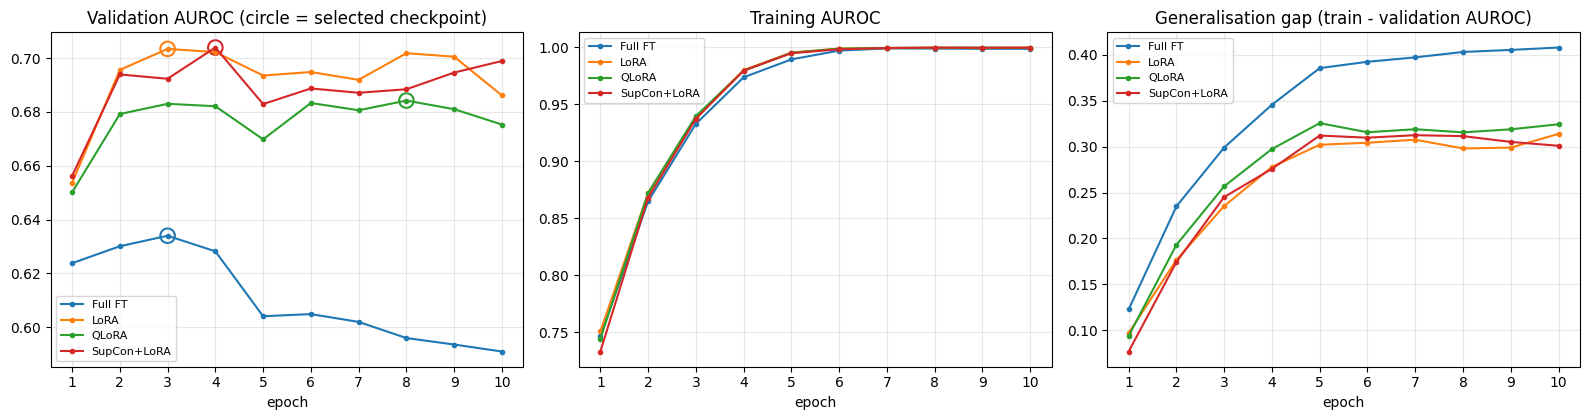

Training summary


,best val AUROC,best epoch,"val AUROC, epoch 10",drop from best,gap at best epoch,gap at epoch 10,train minutes
strategy,,,,,,,
Full FT,0.6340,3,0.5910,-0.0430,0.2990,0.4078,23.6
LoRA,0.7034,3,0.6861,-0.0173,0.2353,0.3138,22.4
QLoRA,0.6842,8,0.6753,-0.0089,0.3155,0.3243,22.1
SupCon+LoRA,0.7039,4,0.6989,-0.0050,0.2758,0.3009,23.3


In [ ]:
# Training dynamics of the four strategies.
# Values are copied from the training logs printed in sections 11-14: no files, no GPU.
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

EPOCHS = np.arange(1, 11)
LABELS = {"full_ft": "Full FT", "lora": "LoRA", "qlora": "QLoRA", "supcon_lora": "SupCon+LoRA"}
TRAIN_LOG = {
    "full_ft": dict(
        val=[0.6238, 0.6301, 0.6340, 0.6282, 0.6041, 0.6049, 0.6020, 0.5960, 0.5936, 0.5910],
        train=[0.7466, 0.8651, 0.9330, 0.9738, 0.9895, 0.9972, 0.9991, 0.9990, 0.9988, 0.9988],
        minutes=23.6),
    "lora": dict(
        val=[0.6536, 0.6956, 0.7034, 0.7022, 0.6935, 0.6948, 0.6919, 0.7018, 0.7005, 0.6861],
        train=[0.7508, 0.8723, 0.9387, 0.9801, 0.9955, 0.9990, 0.9994, 0.9998, 0.9994, 0.9999],
        minutes=22.4),
    "qlora": dict(
        val=[0.6501, 0.6792, 0.6830, 0.6821, 0.6698, 0.6833, 0.6806, 0.6842, 0.6810, 0.6753],
        train=[0.7442, 0.8723, 0.9398, 0.9795, 0.9953, 0.9989, 0.9995, 0.9997, 0.9998, 0.9996],
        minutes=22.1),
    "supcon_lora": dict(
        val=[0.6562, 0.6939, 0.6923, 0.7039, 0.6829, 0.6887, 0.6871, 0.6884, 0.6946, 0.6989],
        train=[0.7332, 0.8683, 0.9374, 0.9797, 0.9949, 0.9984, 0.9995, 0.9998, 0.9997, 0.9998],
        minutes=23.3),
}

fig, axes = plt.subplots(1, 3, figsize=(16, 4.3))
for s, log in TRAIN_LOG.items():
    val, tr = np.array(log["val"]), np.array(log["train"])
    b = int(np.argmax(val))
    line, = axes[0].plot(EPOCHS, val, marker="o", ms=3, label=LABELS[s])
    axes[0].scatter(EPOCHS[b], val[b], s=110, facecolors="none", edgecolors=line.get_color(), lw=1.5)
    axes[1].plot(EPOCHS, tr, marker="o", ms=3, label=LABELS[s])
    axes[2].plot(EPOCHS, tr - val, marker="o", ms=3, label=LABELS[s])
axes[0].set_title("Validation AUROC (circle = selected checkpoint)")
axes[1].set_title("Training AUROC")
axes[2].set_title("Generalisation gap (train - validation AUROC)")
for ax in axes:
    ax.set_xlabel("epoch"); ax.set_xticks(EPOCHS); ax.grid(alpha=0.3); ax.legend(fontsize=8)
plt.tight_layout(); plt.show()

rows = []
for s, log in TRAIN_LOG.items():
    val, tr = np.array(log["val"]), np.array(log["train"])
    b = int(np.argmax(val))
    rows.append({"strategy": LABELS[s], "best val AUROC": val[b], "best epoch": b + 1,
                 "val AUROC, epoch 10": val[-1], "drop from best": val[-1] - val[b],
                 "gap at best epoch": tr[b] - val[b], "gap at epoch 10": tr[-1] - val[-1],
                 "train minutes": log["minutes"]})
print("Training summary")
display(pd.DataFrame(rows).set_index("strategy").round(4))

#### Interpretation — training dynamics across strategies

- **All four strategies memorise the training set.** Training AUROC reaches about 0.999 by
  epoch 6–7 in every case. What distinguishes them is what happens on validation data.
- **Full fine-tuning degrades.** It drops 0.043 from its peak by epoch 10. The three low-rank
  strategies plateau and lose 0.005–0.017.
- **The parameter-efficient curves sit above full fine-tuning at every epoch,** and the
  separation grows after epoch 3. The RQ1 advantage is therefore not an accident of checkpoint
  selection: it holds wherever training is stopped.
- **Within the parameter-efficient family, the ordering is LoRA ≈ SupCon+LoRA > QLoRA** at
  almost every epoch, by up to about 0.02. The ordering is consistent but small. Section 19b shows that on
  the test set it does not survive correction for multiple comparisons.
- **The best epochs are early** (3–4), except QLoRA's flat curve. Early stopping would have
  saved roughly half of the compute. It was left out deliberately, to keep the four conditions
  matched (F-15).
- **Training time is 22–24 minutes for every strategy.** LoRA does not train faster here
  because backpropagation still traverses the whole network to reach adapters in every layer.
  Per-item image loading on the T4 is also a likely bottleneck (F-14).

---
# Part V — Testing

Training is finished, and every strategy has a selected checkpoint on disk. **Nothing above has
touched the test set.**

Testing has its own part so that evaluation cannot run without reloading the selected checkpoint.
It rebuilds each architecture from the factory, loads the saved weights and evaluates. It needs
no GPU memory from training, so it can run in a fresh session.

## 15. Test evaluation

Each strategy's selected checkpoint is evaluated once on the 2,408 test memes. The metrics and
the **raw test logits** are saved to disk. The saved logits allow the bootstrap and DeLong tests
in Part VII to run without retraining.

In [ ]:
test_results = {}
for strategy in ["full_ft", "lora", "qlora", "supcon_lora"]:
    ckpt = CONFIG["ckpt_dir"] / f"{strategy}_best.pt"
    if not ckpt.exists():
        print(f"skipping {strategy} — no checkpoint yet")
        continue
    test_results[strategy] = test_model(strategy)

print("\ntested:", list(test_results))

Loading weights:   0%|          | 0/398 [00:00<?, ?it/s]

  loaded 406 tensors | dropped 0 quant-state | 0 frozen keys rebuilt from pretrained


wandb: WARNING Using a boolean value for 'reinit' is deprecated. Use 'return_previous' or 'finish_previous' instead.


test_accuracy,0.65947
test_auroc,0.68444
test_f1_0.5,0.53567
test_f1_tau,0.60947
test_pr_auc,0.5997
threshold,0.07
trivial_f1,0.58395


full_ft        AUROC 0.6844 | PR-AUC 0.5997 | F1@0.5 0.5357 | F1@0.07 0.6095 | vs trivial +0.0255


...

qlora          AUROC 0.7218 | PR-AUC 0.6402 | F1@0.5 0.5221 | F1@0.05 0.5930 | vs trivial +0.0090


Loading weights:   0%|          | 0/398 [00:00<?, ?it/s]

  loaded 602 tensors | dropped 0 quant-state | 0 frozen keys rebuilt from pretrained


test_accuracy,0.67733
test_auroc,0.73508
test_f1_0.5,0.52477
test_f1_tau,0.64508
test_pr_auc,0.65262
threshold,0.07
trivial_f1,0.58395


supcon_lora    AUROC 0.7351 | PR-AUC 0.6526 | F1@0.5 0.5248 | F1@0.07 0.6451 | vs trivial +0.0611

tested: ['full_ft', 'lora', 'qlora', 'supcon_lora']


#### Interpretation — test results (one evaluation per strategy)

| Strategy | Test AUROC | PR-AUC | F1 @ 0.5 | Validation-optimal τ | F1 @ τ | F1 @ τ minus "all hateful" |
|---|---|---|---|---|---|---|
| Full FT | 0.6844 | 0.5997 | 0.5357 | 0.07 | 0.6095 | +0.026 |
| LoRA | 0.7340 | 0.6466 | 0.5954 | 0.19 | 0.6436 | +0.060 |
| QLoRA | 0.7218 | 0.6402 | 0.5221 | 0.05 | 0.5930 | +0.009 |
| SupCon+LoRA | 0.7351 | 0.6526 | 0.5248 | 0.07 | 0.6451 | +0.061 |

- **Correct checkpoints were tested.** Each strategy's best-validation checkpoint was reloaded
  before testing (F-01). The QLoRA checkpoint loaded after its 725 quantisation-state tensors
  were removed (F-17).
- **PR-AUC.** The no-skill level is the test prior, 0.412. All four models are well above it
  (0.60–0.65).
- **F1 is a weak criterion on this dataset.** The thresholds that maximise F1 on validation are
  very low (0.05–0.19), meaning F1 is maximised by labelling almost every meme hateful. Labelling
  everything hateful scores F1 = 2(0.412)/1.412 = 0.584 on test. At its F1-optimal threshold,
  QLoRA beats that trivial rule by only 0.009. F1 therefore says more about the class prior than
  about the classifier, which is why AUROC is the primary metric.
- **Test AUROC is 0.03–0.05 higher than validation AUROC for all four strategies.** The gap
  reflects the splits (validation is small, 831 memes, with a different prior), not any
  strategy, so comparisons between strategies are unaffected.

---
# Part VI — Measurement

This part covers threshold-dependent metrics and efficiency (RQ3), and links to the explanation
stage (RQ2).

## 16. Metrics and the threshold artefact

**AUROC is the primary metric.** It is independent of the threshold, so it measures how well a
model **ranks** memes rather than where a fixed cut-off happens to fall. The challenge itself
reports AUROC.

**F1 at τ = 0.5 can mislead.** In the final run, full fine-tuning scores F1 0.5357 at τ = 0.5,
above SupCon+LoRA's 0.5248 and QLoRA's 0.5221, even though full fine-tuning has the **lowest**
AUROC (0.6844 against 0.7351 and 0.7218). SupCon+LoRA and QLoRA are simply more conservative at
that particular threshold; their discrimination is not inferior.

AUROC is therefore reported as primary, together with PR-AUC, and F1 is shown at both τ = 0.5 and
the validation-optimal threshold.

In [ ]:
import pandas as pd

R = CONFIG["results_dir"]
STRATS = ["full_ft", "lora", "qlora", "supcon_lora"]

rows = []
for name in STRATS:
    f = R / f"{name}_test.json"
    if not f.exists():
        continue
    r, m = json.load(open(f)), json.load(open(f))["at_0p5"]
    rows.append({"strategy":  name,
                 "AUROC":     r["test_auroc"],
                 "precision": m["precision"],
                 "recall":    m["recall"],
                 "F1":        m["f1"],
                 "accuracy":  m["accuracy"]})

df = pd.DataFrame(rows).set_index("strategy").round(4)
display(df)

print("Confusion matrices at tau = 0.5   [[TN, FP], [FN, TP]]")
for name in df.index:
    cm = json.load(open(R / f"{name}_test.json"))["at_0p5"]["confusion"]
    print(f"  {name:<14}{cm}")


,AUROC,precision,recall,F1,accuracy
strategy,,,,,
full_ft,0.6844,0.6119,0.4763,0.5357,0.6595
lora,0.7340,0.6344,0.5609,0.5954,0.6856
qlora,0.7218,0.6526,0.4350,0.5221,0.6715
supcon_lora,0.7351,0.6682,0.4320,0.5248,0.6773


Confusion matrices at tau = 0.5   [[TN, FP], [FN, TP]]
  full_ft       [[1115, 300], [520, 473]]
  lora          [[1094, 321], [436, 557]]
  qlora         [[1185, 230], [561, 432]]
  supcon_lora   [[1202, 213], [564, 429]]


#### Interpretation — threshold-dependent metrics at τ = 0.5

| Strategy | TN | FP | FN | TP | Precision | Recall | F1 | AUROC |
|---|---|---|---|---|---|---|---|---|
| Full FT | 1,115 | 300 | 520 | 473 | 0.612 | 0.476 | 0.536 | 0.684 |
| LoRA | 1,094 | 321 | 436 | 557 | 0.634 | 0.561 | 0.595 | 0.734 |
| QLoRA | 1,185 | 230 | 561 | 432 | 0.653 | 0.435 | 0.522 | 0.722 |
| SupCon+LoRA | 1,202 | 213 | 564 | 429 | 0.668 | 0.432 | 0.525 | 0.735 |

- **The rankings disagree.** By F1 at 0.5: LoRA > full FT > SupCon+LoRA > QLoRA. By AUROC:
  SupCon+LoRA ≈ LoRA > QLoRA > full FT. Full fine-tuning, the weakest discriminator, beats two
  stronger models on F1. This is the threshold artefact predicted in section 16, now
  demonstrated rather than asserted.
- **Operating points differ.** QLoRA and SupCon+LoRA are the most conservative: highest
  precision (0.65–0.67), lowest recall (0.43). LoRA is the most balanced.
- **Practical implication.** At τ = 0.5, every model misses 44–57% of hateful memes. A
  deployment would set the threshold from the relative cost of missed hate (false negatives)
  against wrongful removal (false positives). AUROC measures the ranking quality that any such
  threshold would work with.

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
from pathlib import Path
from sklearn.metrics import roc_auc_score

In [ ]:
OUT_DIR = Path("/content/drive/MyDrive/honours-clip/results")

strategies = {
    "Full FT"     : "full_ft",
    "LoRA"        : "lora",
    "QLoRA"       : "qlora",
    "SupCon+LoRA" : "supcon_lora",
}

data = {}
for display, key in strategies.items():
    logits = np.load(OUT_DIR / f"{key}_test_logits.npy")
    labels = np.load(OUT_DIR / f"{key}_test_labels.npy")
    data[display] = {"logits": logits, "labels": labels}
    print(f"{display}: {len(labels)} examples, "
          f"AUROC={roc_auc_score(labels, logits):.4f}")

Full FT: 2408 examples, AUROC=0.6844
LoRA: 2408 examples, AUROC=0.7340
QLoRA: 2408 examples, AUROC=0.7218
SupCon+LoRA: 2408 examples, AUROC=0.7351


In [ ]:
def bootstrap_auroc_ci(labels, logits, n_boot=10000, alpha=0.05, seed=42):
    rng  = np.random.RandomState(seed)
    n    = len(labels)
    boot = np.array([
        roc_auc_score(
            labels[idx := rng.choice(n, n, replace=True)],
            logits[idx]
        )
        for _ in range(n_boot)
    ])
    point = roc_auc_score(labels, logits)
    lo    = np.percentile(boot, 100 * alpha / 2)
    hi    = np.percentile(boot, 100 * (1 - alpha / 2))
    return point, lo, hi

print("Bootstrap CI function defined")

Bootstrap CI function defined


Full FT: 0.6844 [0.6629, 0.7054]
LoRA: 0.7340 [0.7139, 0.7538]
QLoRA: 0.7218 [0.7011, 0.7416]
SupCon+LoRA: 0.7351 [0.7149, 0.7550]


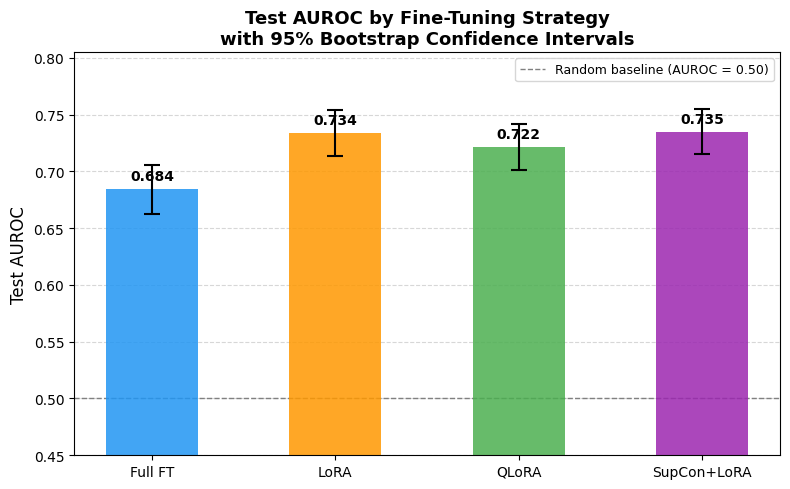

Saved → /content/drive/MyDrive/honours-clip/results/test_auroc_by_strategy.png


In [ ]:
# ── Compute point estimates and CIs ───────────────────────────────────────
results = {}
for display, d in data.items():
    point, lo, hi = bootstrap_auroc_ci(d["labels"], d["logits"])
    results[display] = (point, lo, hi)
    print(f"{display}: {point:.4f} [{lo:.4f}, {hi:.4f}]")

# ── Plot ───────────────────────────────────────────────────────────────────
strategy_names = list(results.keys())
points = [results[s][0] for s in strategy_names]
lows   = [results[s][1] for s in strategy_names]
highs  = [results[s][2] for s in strategy_names]
yerr_lo = [p - l for p, l in zip(points, lows)]
yerr_hi = [h - p for p, h in zip(points, highs)]

colours = ["#2196F3", "#FF9800", "#4CAF50", "#9C27B0"]

fig, ax = plt.subplots(figsize=(8, 5))

bars = ax.bar(
    strategy_names, points,
    color=colours, alpha=0.85, width=0.5,
    zorder=2
)
ax.errorbar(
    strategy_names, points,
    yerr=[yerr_lo, yerr_hi],
    fmt="none", color="black",
    capsize=6, capthick=1.5, linewidth=1.5,
    zorder=3
)

# Annotate bars with point estimate
for bar, point in zip(bars, points):
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        point + 0.005,
        f"{point:.3f}",
        ha="center", va="bottom",
        fontsize=10, fontweight="bold"
    )

# Random baseline reference line
ax.axhline(0.5, color="gray", linestyle="--", linewidth=1,
           label="Random baseline (AUROC = 0.50)", zorder=1)

ax.set_ylim(0.45, min(1.0, max(highs) + 0.05))
ax.set_ylabel("Test AUROC", fontsize=12)
ax.set_title("Test AUROC by Fine-Tuning Strategy\nwith 95% Bootstrap Confidence Intervals",
             fontsize=13, fontweight="bold")
ax.legend(fontsize=9)
ax.yaxis.grid(True, linestyle="--", alpha=0.5, zorder=0)
ax.set_axisbelow(True)

plt.tight_layout()

fig_path = OUT_DIR / "test_auroc_by_strategy.png"
plt.savefig(fig_path, dpi=300, bbox_inches="tight")
plt.show()
print(f"Saved → {fig_path}")

## 17. Efficiency

Peak GPU memory is profiled for **one forward–backward step** of each strategy, with everything
else held constant and gradient checkpointing off for all four (F-07). It needs no retraining and
takes about a minute.

Training time comes from the training runs in Part IV, where every strategy read images from the
same local disk (F-03). Peak memory, training time and trainable parameters are the efficiency
axes of RQ3.

In [ ]:
supcon_loss = SupervisedContrastiveLoss().to(DEVICE)
batch       = next(iter(train_loader))

def peak_memory(strategy):
    """Peak GPU memory for one forward-backward step of this strategy."""
    set_seed()
    model = build_model(strategy).to(DEVICE)
    model.train()

    torch.cuda.empty_cache()
    torch.cuda.reset_peak_memory_stats(DEVICE)

    pixel, ids, mask, y = batch
    y   = y.to(DEVICE)
    out = model(pixel.to(DEVICE), ids.to(DEVICE), mask.to(DEVICE))
    if isinstance(out, tuple):                       # supcon_lora
        logits, embeds = out
        loss = criterion(logits, y) + CONFIG["lambda_sup"] * supcon_loss(embeds, y)
    else:
        loss = criterion(out, y)
    loss.backward()

    gb = torch.cuda.max_memory_allocated(DEVICE) / 1e9
    del model, out, loss
    del_model()
    return gb


STRATS = ["full_ft", "lora", "qlora", "supcon_lora"]

gpu = {s: peak_memory(s) for s in STRATS}

# Training time was recorded during Part IV — just read it back.
res_dir = CONFIG["results_dir"]
rows = []
for s in STRATS:
    tr = res_dir / f"{s}_train.json"
    t  = json.load(open(tr)) if tr.exists() else {}
    rows.append({"strategy":  s,
                 "peak_GB":   round(gpu[s], 3),
                 "train_min": round(t.get("train_minutes", float("nan")), 1),
                 "trainable": t.get("trainable")})

efficiency = pd.DataFrame(rows).set_index("strategy")
display(efficiency)

print(f"LoRA saves over full fine-tuning: {gpu['full_ft'] - gpu['lora']:.3f} GB")
print(f"NF4 quantisation saves over LoRA: {gpu['lora'] - gpu['qlora']:.3f} GB")

efficiency.to_csv(res_dir / "efficiency.csv")


Loading weights:   0%|          | 0/398 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/398 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/398 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/398 [00:00<?, ?it/s]

,peak_GB,train_min,trainable
strategy,,,
full_ft,3.161,23.6,151671554
lora,3.040,22.4,1377281
qlora,2.597,22.1,1377281
supcon_lora,3.042,23.3,1541505


LoRA saves over full fine-tuning: 0.121 GB
NF4 quantisation saves over LoRA: 0.444 GB


#### Interpretation — efficiency (RQ3, efficiency side)

| Strategy | Trainable parameters | Peak GPU GB, one forward–backward step | Training minutes |
|---|---|---|---|
| Full FT | 151,671,554 | 3.161 | 23.6 |
| LoRA | 1,377,281 | 3.040 | 22.4 |
| QLoRA | 1,377,281 | 2.597 | 22.1 |
| SupCon+LoRA | 1,541,505 | 3.042 | 23.3 |

**Parameters.** LoRA and QLoRA train 110× fewer parameters than full fine-tuning; SupCon+LoRA
trains 98× fewer.

**Why LoRA saves only 0.121 GB in this profile.** The cell measures one forward and backward
pass **without an optimiser step**. Its peak therefore contains:

- the frozen or trainable weights, about 0.61 GB in fp32, held by every strategy;
- the activations stored for backpropagation, which every strategy needs because gradients
  must reach adapters in every layer;
- full fine-tuning's parameter gradients (0.61 GB), but only partly: they are allocated during
  backward while activations are being freed, so they add little to the peak.

**AdamW's moment buffers are not in this measurement at all.** For full fine-tuning they are
2 × 0.61 = 1.21 GB; for LoRA, about 0.011 GB. Section 8 identifies them as the main memory cost
of full fine-tuning. A complete training step for full fine-tuning is therefore expected to peak
roughly **1.2–1.8 GB higher** than shown here. The optional cell below measures it directly in
about two minutes, without retraining.

> A statement that "LoRA saves under 4% of GPU memory" is true only of this forward–backward
> profile. It should not be reported as the memory cost of training.

**QLoRA saves 0.444 GB against LoRA** by storing the frozen linear weights in 4 bits instead of
32. Because gradient checkpointing is off for both (F-07), this saving is attributable to
quantisation.

**Training time does not differ meaningfully** (22.1–23.6 minutes). On this hardware and data
pipeline, parameter efficiency did not translate into wall-clock savings.

**What the thesis can state for RQ3's efficiency side:**

1. Parameters and deployable storage fall about 110-fold.
2. 4-bit storage lowers forward–backward peak memory by 15% against LoRA.
3. Full fine-tuning's optimiser state costs a further ≈1.2 GB, which the optional profile
   measures.
4. Training time is unchanged.

#### Optional check — peak memory for a complete training step (about two minutes, no retraining)

This repeats the section 17 profile but includes the AdamW update, so the optimiser's moment
buffers are counted. It runs two steps, so the second one starts with those buffers already
allocated. Set `RUN_OPTIMISER_PROFILE = True` to run it; it needs the GPU session from Setup and
Parts I–III. Nothing is saved to the checkpoints.

In [ ]:
import torch
import pandas as pd
from IPython.display import display

RUN_OPTIMISER_PROFILE = False      # set True to run: about 2 minutes on a T4

FORWARD_BACKWARD_GB = {"full_ft": 3.161, "lora": 3.040, "qlora": 2.597, "supcon_lora": 3.042}


def peak_memory_training_step(strategy, steps=2):
    """Peak GPU memory over complete training steps: forward, backward and AdamW update."""
    set_seed()
    model = build_model(strategy).to(DEVICE)
    model.train()
    lr, _ = STRATEGIES[strategy]
    opt = torch.optim.AdamW([p for p in model.parameters() if p.requires_grad], lr=lr)
    pixel, ids, mask, y = (t.to(DEVICE) for t in profile_batch)
    torch.cuda.empty_cache()
    torch.cuda.reset_peak_memory_stats(DEVICE)
    for _ in range(steps):          # step 2 runs with Adam's buffers already allocated
        opt.zero_grad(set_to_none=True)
        out = model(pixel, ids, mask)
        if isinstance(out, tuple):
            loss = criterion(out[0], y) + CONFIG["lambda_sup"] * profile_supcon(out[1], y)
        else:
            loss = criterion(out, y)
        loss.backward()
        opt.step()
    gb = torch.cuda.max_memory_allocated(DEVICE) / 1e9
    del model, opt, out, loss
    del_model()
    return gb


if RUN_OPTIMISER_PROFILE and torch.cuda.is_available():
    profile_batch  = next(iter(train_loader))
    profile_supcon = SupervisedContrastiveLoss().to(DEVICE)
    full_step = {s: peak_memory_training_step(s) for s in FORWARD_BACKWARD_GB}
    prof = pd.DataFrame({"forward-backward only (section 17)": FORWARD_BACKWARD_GB,
                         "complete training step": full_step})
    prof["optimiser and update overhead"] = (prof["complete training step"]
                                             - prof["forward-backward only (section 17)"])
    prof["saving vs full FT"] = (prof.loc["full_ft", "complete training step"]
                                 - prof["complete training step"])
    display(prof.round(3))
    prof.to_csv(CONFIG["results_dir"] / "efficiency_full_training_step.csv")
else:
    print("Skipped. Set RUN_OPTIMISER_PROFILE = True to measure (about 2 minutes, no retraining).")

## 18. Link to the explanation stage

Explanation faithfulness is evaluated in Part VIII on a fixed, balanced subsample of test memes.
That part:

- uses the selected checkpoints from Part IV through the same model factory;
- documents and checks the verification of the first explanation run (section 24);
- adds a transformer-specific attribution method and two robustness checks to the two methods RQ2
  names (Grad-CAM and KernelSHAP).

---
# Part VII — Reading the results

## 19. The comparison, with uncertainty

Every number below is loaded from the result files written by the training and testing
functions, so nothing is transcribed and nothing can go stale. With one training run per
strategy, resampling the test set is the way to attach uncertainty to differences between
strategies.

#### Method in brief — how the strategies are compared statistically

Each model scores the **same** 2,408 test memes, so differences in AUROC are paired.

- **Paired bootstrap (section 19).** Resample the 2,408 memes with replacement 2,000 times,
  recompute both AUROCs on each resample, and take the 2.5th and 97.5th percentiles of the
  difference. This is distribution-free and makes no assumption about the ROC curves.
- **DeLong's test (section 19b; DeLong et al., 1988; fast implementation by Sun & Xu, 2014).**
  It gives the variance of an AUROC, and the covariance between two AUROCs on the same examples,
  in closed form from per-example "structural components". From these it produces 95%
  confidence intervals and a z-test for each pair. This is the standard test for comparing
  correlated ROC curves.
- **Holm–Bonferroni.** Six pairwise tests are run, so six p-values are adjusted with Holm's
  step-down procedure. This controls the probability of any false positive at 5% and is less
  conservative than Bonferroni.

Both methods quantify **test-set sampling** uncertainty: how much AUROC would vary on a
different sample of memes. Training-run (seed) variability is separate; it was measured at about
0.004 AUROC and is used below as a yardstick.

In [ ]:
def bootstrap_auroc_diff(y, la, lb, n=2000, seed=CONFIG["seed"]):
    """Paired bootstrap 95% CI for AUROC(a) - AUROC(b) on the same test set."""
    rng, N, diffs = np.random.default_rng(seed), len(y), []
    for _ in range(n):
        i = rng.integers(0, N, N)
        if len(np.unique(y[i])) < 2:
            continue
        diffs.append(roc_auc_score(y[i], la[i]) - roc_auc_score(y[i], lb[i]))
    lo, hi = np.percentile(diffs, [2.5, 97.5])
    return float(np.mean(diffs)), float(lo), float(hi)


runs = {}
for name in ["full_ft", "lora", "qlora", "supcon_lora"]:
    tr, te = R / f"{name}_train.json", R / f"{name}_test.json"
    if tr.exists() and te.exists():
        runs[name] = {**json.load(open(tr)), **json.load(open(te))}

print(f"{'strategy':<14}{'best val':>10}{'ep':>4}{'test AUROC':>12}"
      f"{'trainable':>13}{'min':>7}")
print("-" * 62)
for n, r in runs.items():
    print(f"{n:<14}{r['best_val_auroc']:>10.4f}"
          f"{int(np.argmax(r['val_history']))+1:>4}{r['test_auroc']:>12.4f}"
          f"{r['trainable']:>13,}{r['train_minutes']:>7.1f}")

print("\nPaired bootstrap, 95% CI on test AUROC difference:")
pairs = [("lora", "full_ft"), ("qlora", "lora"), ("supcon_lora", "lora")]
for a, b in pairs:
    if a in runs and b in runs:
        y  = np.load(R / f"{a}_test_labels.npy")
        la = np.load(R / f"{a}_test_logits.npy")
        lb = np.load(R / f"{b}_test_logits.npy")
        d, lo, hi = bootstrap_auroc_diff(y, la, lb)
        verdict = "REAL" if lo > 0 or hi < 0 else "not resolved"
        print(f"  {a} - {b:<14}{d:>+8.4f}  [{lo:+.4f}, {hi:+.4f}]  {verdict}")

strategy        best val  ep  test AUROC    trainable    min
--------------------------------------------------------------
full_ft           0.6340   3      0.6844  151,671,554   23.6
lora              0.7034   3      0.7340    1,377,281   22.4
qlora             0.6842   8      0.7218    1,377,281   22.1
supcon_lora       0.7039   4      0.7351    1,541,505   23.3

Paired bootstrap, 95% CI on test AUROC difference:
  lora - full_ft        +0.0499  [+0.0330, +0.0665]  REAL
  qlora - lora           -0.0125  [-0.0245, -0.0003]  REAL
  supcon_lora - lora           +0.0008  [-0.0091, +0.0104]  not resolved


#### Interpretation — paired bootstrap

| Contrast | Difference | 95% CI | Resolved (uncorrected)? |
|---|---|---|---|
| LoRA − full FT | +0.0499 | [+0.0330, +0.0665] | Yes |
| QLoRA − LoRA | −0.0125 | [−0.0245, −0.0003] | Only just |
| SupCon+LoRA − LoRA | +0.0008 | [−0.0091, +0.0104] | No |

- **LoRA's advantage over full fine-tuning is large and clear.** It is about twelve times the
  seed variation.
- **QLoRA's deficit to LoRA has an interval whose upper end touches zero.** It is about three
  times the seed variation. This is the borderline case that section 19b tests with correction.
- **SupCon+LoRA and LoRA are indistinguishable.** The point estimate is 0.0008, and the interval
  is centred on zero.
- The best-validation epochs listed (3, 3, 8, 4) match the training logs, confirming that the
  tested checkpoints are the selected ones.

## 19b. DeLong 95% confidence intervals

DeLong's method gives the same kind of interval as the bootstrap, but in closed form, and it is
the standard test for comparing AUROCs. It works because AUROC is a Mann–Whitney U statistic, so
its variance has an analytic form. Sun and Xu's (2014) algorithm computes it from midranks in
O(n log n) time.

**Why the paired version matters.** All four strategies were evaluated on the identical 2,408
memes, so their errors are correlated: a meme that is hard for LoRA is usually hard for QLoRA
too. The paired test includes that covariance. Treating the AUROCs as independent would overstate
the variance of their difference and hide real effects.

**Reading the output.**

- An interval on a single AUROC shows how precisely that model was measured.
- An interval on a *difference* that excludes zero indicates a difference that can be claimed.
- The Holm–Bonferroni column adjusts for running six comparisons at once.

This cell needs only the saved test logits: no GPU, no data loaders, no retraining.

In [ ]:
"""Fast DeLong (Sun & Xu, 2014) — 95% CIs and paired tests on test AUROC.

Reads only the saved test logits and labels, so it needs no GPU, no data
loaders and no retraining. It can run in a fresh session.
"""
import numpy as np, json
from scipy.stats import norm
from sklearn.metrics import roc_auc_score

def _midrank(x):
    J = np.argsort(x)
    Z = x[J]
    N = len(x)
    T = np.zeros(N, dtype=float)
    i = 0
    while i < N:
        j = i
        while j < N and Z[j] == Z[i]:
            j += 1
        T[i:j] = 0.5 * (i + j - 1) + 1      # average rank handles ties
        i = j
    T2 = np.empty(N, dtype=float)
    T2[J] = T
    return T2


def _fast_delong(preds_sorted, m):
    """preds_sorted: (k, N) scores, positives first. m = number of positives."""
    n = preds_sorted.shape[1] - m
    k = preds_sorted.shape[0]
    pos, neg = preds_sorted[:, :m], preds_sorted[:, m:]

    tx = np.empty([k, m]); ty = np.empty([k, n]); tz = np.empty([k, m + n])
    for r in range(k):
        tx[r] = _midrank(pos[r]); ty[r] = _midrank(neg[r])
        tz[r] = _midrank(preds_sorted[r])

    aucs = tz[:, :m].sum(axis=1) / m / n - (m + 1) / (2.0 * n)
    v01  = (tz[:, :m] - tx) / n                      # structural components
    v10  = 1.0 - (tz[:, m:] - ty) / m
    cov  = (np.cov(v01, ddof=1).reshape(k, k) / m
            + np.cov(v10, ddof=1).reshape(k, k) / n)
    return aucs, cov


def _prepare(y, *scores):
    order = (-y).argsort(kind="mergesort")           # positives first
    return np.vstack([s[order] for s in scores]), int(y.sum())


def delong_ci(y, scores, alpha=0.95):
    """AUROC with a DeLong confidence interval."""
    auc, cov = _fast_delong(*_prepare(y, scores))
    se = float(np.sqrt(cov[0, 0]))
    z  = norm.ppf(1 - (1 - alpha) / 2)
    return float(auc[0]), max(0.0, auc[0] - z * se), min(1.0, auc[0] + z * se), se


def delong_test(y, scores_a, scores_b, alpha=0.95):
    """Paired DeLong test for two correlated ROC curves on the SAME examples."""
    aucs, cov = _fast_delong(*_prepare(y, scores_a, scores_b))
    diff = float(aucs[0] - aucs[1])
    var  = float(cov[0, 0] + cov[1, 1] - 2 * cov[0, 1])
    se   = float(np.sqrt(max(var, 1e-300)))
    z    = norm.ppf(1 - (1 - alpha) / 2)
    stat = diff / se
    return dict(diff=diff, lo=diff - z * se, hi=diff + z * se,
                se=se, z=stat, p=float(2 * norm.sf(abs(stat))))


# ---------------------------------------------------------------- run it
R = CONFIG["results_dir"]
STRATS = ["full_ft", "lora", "qlora", "supcon_lora"]

scores, labels = {}, None
for s in STRATS:
    f = R / f"{s}_test_logits.npy"
    if not f.exists():
        continue
    scores[s] = np.load(f)
    y = np.load(R / f"{s}_test_labels.npy")
    if labels is None:
        labels = y
    assert np.array_equal(labels, y), f"{s} evaluated on a different test set"

print(f"n = {len(labels):,}   positives = {int(labels.sum()):,}"
      f"   prior = {labels.mean():.3f}\n")

print(f"{'strategy':<14}{'AUROC':>8}{'95% CI (DeLong)':>22}{'SE':>9}")
print("-" * 54)
ci = {}
for s, l in scores.items():
    auc, lo, hi, se = delong_ci(labels, l)
    ci[s] = (auc, lo, hi)
    assert abs(auc - roc_auc_score(labels, l)) < 1e-9      # sanity check
    print(f"{s:<14}{auc:>8.4f}   [{lo:.4f}, {hi:.4f}]{se:>11.4f}")

print(f"\n{'comparison':<26}{'diff':>9}{'95% CI':>22}{'p':>10}   verdict")
print("-" * 80)
pairs = [("lora", "full_ft"), ("qlora", "full_ft"), ("supcon_lora", "full_ft"),
         ("qlora", "lora"),   ("supcon_lora", "lora"), ("qlora", "supcon_lora")]

delong_results = {}
for a, b in pairs:
    if a not in scores or b not in scores:
        continue
    r = delong_test(labels, scores[a], scores[b])
    delong_results[f"{a}_vs_{b}"] = r
    verdict = "significant" if r["p"] < 0.05 else "not resolved"
    print(f"{a + ' - ' + b:<26}{r['diff']:>+9.4f}"
          f"   [{r['lo']:+.4f}, {r['hi']:+.4f}]{r['p']:>10.4f}   {verdict}")

# Holm-Bonferroni across the six pairwise tests
ps = sorted(delong_results.items(), key=lambda kv: kv[1]["p"])
print("\nHolm-Bonferroni adjusted (6 comparisons):")
for rank, (name, r) in enumerate(ps):
    adj = min(1.0, r["p"] * (len(ps) - rank))
    delong_results[name]["p_holm"] = adj
    print(f"  {name:<28}p = {r['p']:.4f}  ->  {adj:.4f}"
          f"   {'significant' if adj < 0.05 else 'not resolved'}")

with open(R / "delong.json", "w") as fh:
    json.dump({"auroc_ci": {k: dict(auroc=v[0], lo=v[1], hi=v[2])
                            for k, v in ci.items()},
               "pairwise": delong_results}, fh, indent=2)


n = 2,408   positives = 993   prior = 0.412

strategy         AUROC       95% CI (DeLong)       SE
------------------------------------------------------
full_ft         0.6844   [0.6629, 0.7059]     0.0110
lora            0.7340   [0.7140, 0.7540]     0.0102
qlora           0.7218   [0.7014, 0.7422]     0.0104
supcon_lora     0.7351   [0.7151, 0.7551]     0.0102

comparison                     diff                95% CI         p   verdict
--------------------------------------------------------------------------------
lora - full_ft              +0.0495   [+0.0325, +0.0665]    0.0000   significant
qlora - full_ft             +0.0374   [+0.0185, +0.0562]    0.0001   significant
supcon_lora - full_ft       +0.0506   [+0.0318, +0.0695]    0.0000   significant
qlora - lora                -0.0122   [-0.0243, -0.0001]    0.0484   significant
supcon_lora - lora          +0.0011   [-0.0086, +0.0108]    0.8238   not resolved
qlora - supcon_lora         -0.0133   [-0.0257, -0.0009]    0.0361  

#### Interpretation — DeLong intervals and tests: the answer to RQ1

**Intervals.** Full fine-tuning's 95% interval, [0.663, 0.706], does not overlap LoRA's
[0.714, 0.754] or SupCon+LoRA's [0.715, 0.755], and overlaps QLoRA's [0.701, 0.742] only
slightly.

**Pairwise tests (Holm over six):**

| Comparison | Difference | Holm-adjusted p | Conclusion |
|---|---|---|---|
| LoRA − full FT | +0.0495 | < 0.0001 | Significant |
| SupCon+LoRA − full FT | +0.0506 | < 0.0001 | Significant |
| QLoRA − full FT | +0.0374 | 0.0004 | Significant |
| QLoRA − SupCon+LoRA | −0.0133 | 0.108 | Not resolved |
| QLoRA − LoRA | −0.0122 | 0.097 | Not resolved |
| SupCon+LoRA − LoRA | +0.0011 | 0.824 | Not resolved |

The bootstrap and DeLong methods agree closely: LoRA − full FT is +0.0499 by bootstrap and
+0.0495 by DeLong.

> **RQ1 answer.** Under matched, untuned configurations on the filtered Hateful Memes test set,
> all three parameter-efficient strategies classify significantly better than full fine-tuning
> (+0.037 to +0.051 AUROC), while training at most 1.02% of its parameters. Among the three,
> no difference survives correction. QLoRA's deficit of about 0.012–0.013 is nominally
> significant but not robust to multiplicity, so it is best described as small and unconfirmed.

**Against the hypothesis.** The project plan expected LoRA and QLoRA to *approach* full
fine-tuning. They exceed it. The training curves explain why: with 6,744 examples, the low-rank
constraint acts as regularisation, while unconstrained full fine-tuning overfits and drifts.

**Context.** On the complete test set, published references are 0.7544 AUROC for a
VisualBERT-COCO baseline and 0.8265 for human annotators. The figures here use a filtered subset
and are not directly comparable, but they are of a similar order to the published baselines.

### RQ1 at a glance

The figure below uses the recorded DeLong results, so it needs no files and no GPU. The optional
cell after it draws ROC curves from the test logits saved in Drive.

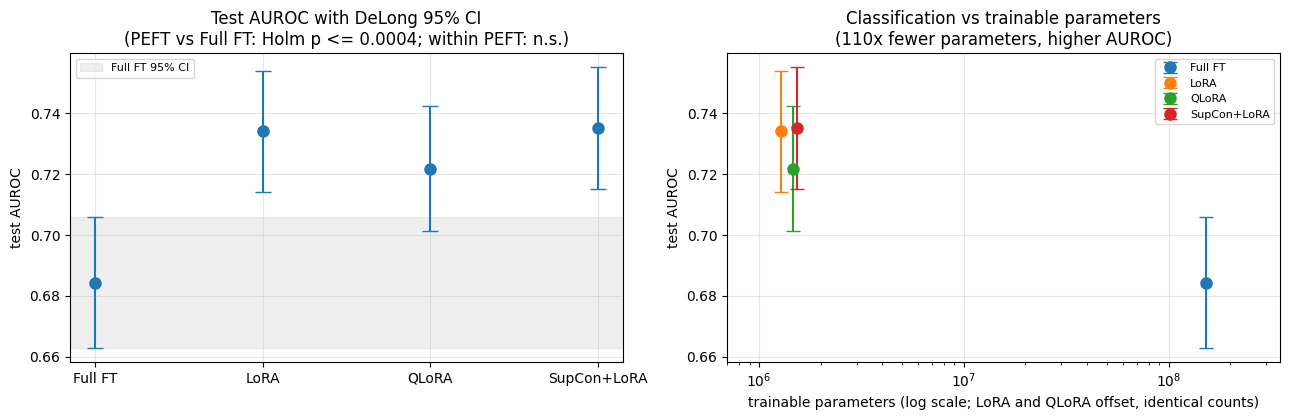

In [ ]:
# RQ1 summary figure from the recorded DeLong results (section 19b). No files, no GPU.
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

rq1 = pd.DataFrame({
    "trainable": [151_671_554, 1_377_281, 1_377_281, 1_541_505],
    "auroc":     [0.6844, 0.7340, 0.7218, 0.7351],
    "lo":        [0.6629, 0.7140, 0.7014, 0.7151],
    "hi":        [0.7059, 0.7540, 0.7422, 0.7551],
}, index=["Full FT", "LoRA", "QLoRA", "SupCon+LoRA"])

fig, axes = plt.subplots(1, 2, figsize=(13, 4.3))
x = np.arange(len(rq1))
axes[0].errorbar(x, rq1.auroc, yerr=[rq1.auroc - rq1.lo, rq1.hi - rq1.auroc],
                 fmt="o", capsize=6, ms=8)
axes[0].axhspan(rq1.loc["Full FT", "lo"], rq1.loc["Full FT", "hi"], color="grey", alpha=0.12,
                label="Full FT 95% CI")
axes[0].set_xticks(x); axes[0].set_xticklabels(rq1.index)
axes[0].set_ylabel("test AUROC"); axes[0].legend(fontsize=8)
axes[0].set_title("Test AUROC with DeLong 95% CI\n(PEFT vs Full FT: Holm p <= 0.0004; within PEFT: n.s.)")

offset = {"Full FT": 1.0, "LoRA": 0.93, "QLoRA": 1.07, "SupCon+LoRA": 1.0}  # LoRA = QLoRA count
for name, r in rq1.iterrows():
    axes[1].errorbar(r.trainable * offset[name], r.auroc, yerr=[[r.auroc - r.lo], [r.hi - r.auroc]],
                     fmt="o", capsize=5, ms=8, label=name)
axes[1].set_xscale("log"); axes[1].set_xlim(7e5, 3.5e8)
axes[1].set_xlabel("trainable parameters (log scale; LoRA and QLoRA offset, identical counts)")
axes[1].set_ylabel("test AUROC"); axes[1].legend(fontsize=8)
axes[1].set_title("Classification vs trainable parameters\n(110x fewer parameters, higher AUROC)")
for ax in axes:
    ax.grid(alpha=0.3)
plt.tight_layout(); plt.show()

In [ ]:
# Optional: ROC curves from the saved test logits (CPU only; needs Drive mounted).
from pathlib import Path
from sklearn.metrics import roc_curve, roc_auc_score
import numpy as np
import matplotlib.pyplot as plt

res_path = Path("/content/drive/MyDrive/honours-clip/results")
names = {"full_ft": "Full FT", "lora": "LoRA", "qlora": "QLoRA", "supcon_lora": "SupCon+LoRA"}
found = [s for s in names if (res_path / f"{s}_test_logits.npy").exists()]
if not found:
    print(f"No saved test logits in {res_path}; mount Drive to draw ROC curves.")
else:
    plt.figure(figsize=(5.8, 5.2))
    for s in found:
        y = np.load(res_path / f"{s}_test_labels.npy")
        l = np.load(res_path / f"{s}_test_logits.npy")
        fpr, tpr, _ = roc_curve(y, l)
        plt.plot(fpr, tpr, label=f"{names[s]} (AUROC {roc_auc_score(y, l):.4f})")
    plt.plot([0, 1], [0, 1], "k--", lw=0.8, label="chance")
    plt.xlabel("false positive rate"); plt.ylabel("true positive rate")
    plt.title("Test ROC curves (2,408 memes)"); plt.legend(fontsize=8); plt.grid(alpha=0.3)
    plt.tight_layout(); plt.show()

## 20. What the classification results support

All values come from the final seeded run, with each selected checkpoint reloaded before testing.

**Supported.**

1. **Every parameter-efficient strategy outperforms full fine-tuning.** LoRA, QLoRA and
   SupCon+LoRA reach test AUROC 0.7340, 0.7218 and 0.7351, against 0.6844 for full fine-tuning:
   gains of 0.037–0.051, each significant under DeLong with Holm correction (adjusted
   p ≤ 0.0004). They do this while training 1.38–1.54 million parameters instead of 151.7 million.
2. **The three parameter-efficient strategies cannot be separated.**
   - SupCon+LoRA − LoRA = +0.0011 (p = 0.82).
   - QLoRA − LoRA = −0.0122, nominal p = 0.048, Holm-adjusted 0.097.
   - QLoRA − SupCon+LoRA = −0.0133, nominal p = 0.036, Holm-adjusted 0.108.
3. **Full fine-tuning peaks early and degrades** under limited supervision. Its best validation
   AUROC is at epoch 3 of 10, and it loses 0.043 by epoch 10.

**Not supported.**

- **Any ordering within the parameter-efficient family.** The QLoRA gap is borderline: the
  uncorrected bootstrap and DeLong intervals just exclude zero, but neither survives correction
  for six comparisons.
- **"Quantisation cost nothing."** "No detectable cost after correction" is accurate.
- **A training-memory saving for LoRA read from section 17,** which excludes optimiser state.
- **Any wall-clock advantage.** All four strategies train in 22–24 minutes.

**Consequence for RQ2.** Because the parameter-efficient strategies are indistinguishable on
AUROC, a faithfulness difference *within* that family cannot be put down to one model classifying
better. The same logic does not extend to full fine-tuning, which is the weaker classifier (F-24).

For context, all on the complete test set rather than this filtered subset: human accuracy is
0.8265 AUROC, the VisualBERT-COCO baseline 0.7544, and the top five challenge entries 0.79–0.84.

## 21. Verification log

Every problem found while verifying the pipeline is listed below. Critical and high-severity
items are corrected in the code; the rest are documented.

| ID | Severity | Issue | Status |
|---|---|---|---|
| F-01 | **Critical** | The LoRA test evaluation did not reload the selected checkpoint (it used epoch-10 weights) | Fixed: one test function reloads the selected checkpoint for every strategy |
| F-07 | **Critical** | Gradient checkpointing was enabled only for QLoRA, confounding the memory comparison | Fixed: an explicit flag, off for every strategy |
| F-18 | **Critical** | Grad-CAM was hooked to the final vision block's output, where the gradient is exactly zero | Fixed: hook `layers[-1].layer_norm1` (section 27) |
| F-19 | **Critical** | Text removal used the pad token, which equals CLIP's end-of-text token, so removing a word truncated the caption | Fixed: token deletion (section 30) |
| F-02 | High | No seeding | Fixed: full seeding (section 0.3) |
| F-03 | High | Full fine-tuning read images from Drive while other runs read local disk | Fixed: every run reads `/content/hm_img` |
| F-04 | High | `−∞ × 0 = NaN` pattern in the SupCon masking | Fixed: `torch.where` |
| F-08 | High | QLoRA's trainable percentage is an artefact of 4-bit packing | Fixed: absolute counts reported |
| F-17 | High | QLoRA checkpoints contain quantisation state, so a strict load fails | Fixed: state dropped; trainable parameters asserted |
| F-20 | High | KernelSHAP's default L1 regularisation left about 10 non-zero values | Fixed: `l1_reg=False`, seeded (section 29) |
| F-21 | High | Random baseline computed in a separate pipeline with a different grid, cut-off and subsample | Fixed: scored in the same call (section 31) |
| F-25 | High | KernelSHAP rankings in the corrected run were not oriented to the predicted class, so for memes predicted benign the evidence *against* the decision was ranked first | Fixed in code (section 32); stored run re-scored from the saved SHAP values (section 32b) |
| F-05 | Medium | The embedding helper's fallback read the pre-projection output | Fixed: projected embeddings, width asserted |
| F-06 | Medium | Efficiency logging ran inside the epoch loop; a W&B run was left open | Fixed: profiled separately; runs closed in `finally` |
| F-09 | Medium | An unused weighted sampler was defined | Removed |
| F-10 | Medium | `pos_weight` was computed from rounded percentages | Fixed: derived from counts |
| F-11 | Medium | About 20% of the data is unavailable; the test split is non-standard | Documented and audited (section 1) |
| F-22 | Medium | The cross-strategy Holm step was not applied in the first explanation run | Fixed: bootstrap p-values with Holm (section 39) |
| F-23 | Medium | Two different explanation subsamples existed | Fixed: one nested subsample (section 25) |
| F-24 | Medium | The explanation analysis assumed all four strategies tie on AUROC | Corrected: full-FT contrasts flagged as confounded |
| F-12 | Low | A boolean was logged as training time | Removed |
| F-13 | Low | `torch.load` was called without `weights_only` | Fixed |
| F-14 | Low | Per-item CPU preprocessing is likely input-bound | Mitigated: `pin_memory`, persistent workers |
| F-26 | Note | QLoRA's single and batched forward passes differ by up to 0.08 on the logit scale (4-bit kernels in fp16) | Documented; extent checked in section 33 |
| F-15 | Note | No schedule, warm-up, clipping or early stopping | Unchanged by design (matched control) |
| F-16 | Note | SupCon uses a single view without augmentation | Documented |

**Provenance.** The training loop, Dataset pattern, weighted BCE, AdamW and metric suite are
standard idioms. LoRA, QLoRA, Grad-CAM, KernelSHAP, ERASER and the transformer attribution method
are published methods accessed through libraries or reimplemented, and are cited. The supervised
contrastive loss is an independent implementation of Khosla et al.'s objective. It differs from
their reference code in its masking, its number of views and the omitted `base_temperature`
term.

## 22. Running order

| Goal | Run | GPU | Time |
|---|---|---|---|
| Inspect all recorded results | Nothing: the outputs are stored in the notebook | — | — |
| Re-test or re-profile | Setup → Parts I–III → section 15 or 17 | T4 | Minutes |
| Retrain a strategy | Setup → Parts I–III → one of sections 11–14 | T4 | About 23 min each |
| Statistical comparison | Sections 19–19b (saved logits only) | No | Seconds |
| Check the first explanation run | Section 24 | No (check 2: optional) | About 1 min |
| Explanation run | Setup → Parts I–III → sections 25–33 (`QUICK = True` first) | T4 | See section 32's estimate |
| Orient KernelSHAP rankings | Setup → Parts I–III → sections 25–31 → section 32b | T4 or L4 | About 10–15 min |
| Faithfulness analysis and answers | Parts X–XI (after sections 32 and 32b) | No | Minutes |

Every Colab session reset requires re-running Setup and Parts I–III before any model work.

---
# Part VIII — Explainability: how faithfulness is measured

Parts IV–VII establish how well each strategy **classifies**. This part asks whether the
account a model gives of a decision can be trusted, and whether that depends on how the model
was adapted (RQ2). It also provides the faithfulness side of the efficiency trade-off (RQ3).

**Running order.**

1. **Section 24 checks (no GPU, about a minute).** They confirm the first run's measurement
   faults directly on the files saved in Drive.
2. **Sections 25–32 with `QUICK = True` (about 10 minutes).** This smoke test exercises every
   code path and prints a time estimate for the full run.
3. **Section 32 with `QUICK = False`.** This is the full run on 600 memes. It saves progress
   every 25 memes and resumes after a disconnect, so each strategy can run in its own Colab
   session.
4. **Parts X–XI.** These are CPU only and can run in a fresh session.

## 23. What is measured: faithfulness

| Term | Meaning | Measured here? |
|---|---|---|
| *Explainability* | The broad property of a system whose decisions can be accounted for | Umbrella term |
| *Plausibility* | Whether an explanation **looks** convincing to a person | No |
| *Faithfulness* | Whether an explanation reflects the evidence the model **actually used** | **Yes** |

An explanation can look entirely reasonable while describing something the model ignores, so
faithfulness and plausibility must be evaluated separately (Jacovi & Goldberg, 2020). ERASER
(DeYoung et al., 2020) measures faithfulness only. RQ2 is therefore answered as a question
about faithfulness.

### Components

| Component | Role | Output | Modality |
|---|---|---|---|
| **Grad-CAM** (Selvaraju et al., 2017) | Primary attribution method | Non-negative score per patch (7×7) | Image |
| **KernelSHAP** (Lundberg & Lee, 2017) | Primary attribution method | Signed score per patch or token | Image, text |
| **Transformer attribution** (Chefer et al., 2021) | Supplementary method built for transformers | Relevance per patch and per token | Image, text |
| **ERASER** (DeYoung et al., 2020) | Evaluation: delete or keep only the top-ranked features | Comprehensiveness and sufficiency (AOPC) | Both |
| **Random baseline** | Reference: the same scores for random rankings | Comprehensiveness and sufficiency per meme | Both |

The attribution methods *propose* which inputs mattered. ERASER *tests* each proposal by
changing the input and re-running the model. The random baseline makes the tests
interpretable: a model that reacts strongly to any deletion produces large scores for every
ranking, including a meaningless one.

RQ2 names Grad-CAM and KernelSHAP, so those two form the primary analysis. The transformer
attribution method is reported as supplementary evidence, in its own family of tests.

### Main analysis and robustness checks (fixed before any result is seen)

| | Main analysis | Robustness check 1 | Robustness check 2 |
|---|---|---|---|
| How an image patch is removed | Mean colour of the same image | Gaussian blur of the same image | Mean colour |
| Scale of the score | Probability of the predicted class | Probability | Logit of the predicted class |
| Applies to | All methods and modalities | Image metrics | All metrics |

The robustness checks answer two questions. Does a conclusion depend on how "removed" pixels
are filled in? And does it depend on the probability scale, which moves most near 0.5? A
conclusion is reported as robust when it holds under all three settings.

### Design invariants

Every strategy is explained on the same 600 test memes, with the same grid, removal operators,
bins, SHAP budget and random permutations. Only the model weights change between runs.

### What the comparison supports

The three parameter-efficient strategies cannot be separated on test AUROC after correction
(section 19b). Within that family, a faithfulness difference cannot be put down to one model
classifying better. Full fine-tuning is significantly worse on AUROC, so contrasts against it
confound the adaptation method with classification quality, and they are interpreted with that
caveat.

## 24. Verification of the first explainability run

Before the corrected pipeline was built, the outputs of a first explainability run were
audited. Seven problems were found, continuing the verification log in section 21.

| ID | Severity | Problem | Effect on the first run's numbers | Correction in this part |
|---|---|---|---|---|
| F-18 | Critical | Grad-CAM was hooked to the **output** of the final vision block | Every map is zero; "Grad-CAM" scores measure top-row-first occlusion | Hook `layers[-1].layer_norm1` (section 27) |
| F-19 | Critical | Text removal replaced tokens with the pad token, whose id **equals CLIP's end-of-text id** | Removing a word cut the caption off at that word; text scores measure truncation | Delete tokens and re-pack the caption (section 30) |
| F-20 | High | KernelSHAP's default L1 regularisation keeps about 10 non-zero values | Remaining patches and tokens tie at zero and are ranked in index order | `l1_reg=False`, seeded sampling (section 29) |
| F-21 | High | Random baseline computed in a separate pipeline: 196-patch grid, one cut-off, a different subsample | Not paired with the attribution scores; "beats random" verdicts unusable | Random rankings scored in the same call (section 31) |
| F-22 | Medium | Holm correction not applied to cross-strategy contrasts | Contrasts uncorrected | Bootstrap p-values with Holm (section 39) |
| F-23 | Medium | Two different subsample files | Risk of comparing different memes | One subsample, nested within the first run's (section 25) |
| F-24 | Medium | Premise that all four strategies tie on AUROC | Full-FT contrasts over-interpreted | Full-FT contrasts flagged as confounded |

**F-18.** Hugging Face's CLIP builds the image embedding from the `[CLS]` token alone:
`pooled = post_layernorm(h_L[:, 0])`. Patch tokens leaving the final block are never read
again, so their gradient is exactly zero, and so is the Grad-CAM map. With all scores tied,
patches are ranked 0, 1, 2, …, so the top rows of each image are deleted first.

**F-19.** CLIP's tokenizer uses `<|endoftext|>` as its pad token, and the text encoder reads
the caption from the **first** `<|endoftext|>`. Because the encoder is causal, each position
sees only earlier words. Replacing word *j* with the pad token therefore moves the read-out to
*j*, which is the same as cutting the caption at *j*. The check below shows that the two give
identical embeddings.

**F-20.** In current `shap` releases, `KernelExplainer.shap_values` defaults to
`l1_reg="num_features(10)"`. Of 49 patches, 39 receive exactly zero.

The two cells below make these faults checkable rather than asserted. The first reads the first
run's saved files. The second uses the pretrained CLIP backbone. Neither needs a trained
checkpoint.

In [ ]:
# Check 1: the first run's saved explanations. Reads files only; no model, no GPU.
import json
import numpy as np
import pandas as pd
from pathlib import Path
from IPython.display import display

RESULTS_DIR = (CONFIG["results_dir"] if "CONFIG" in globals()
               else Path("/content/drive/MyDrive/honours-clip/results"))
XAI_DIR = RESULTS_DIR / "xai"
STRATEGY_ORDER = ["full_ft", "lora", "qlora", "supcon_lora"]

rows = []
for s in STRATEGY_ORDER:
    d = XAI_DIR / "gradcam" / s
    cams  = sorted(p for p in d.glob("*.npy") if not p.stem.endswith("_text"))
    texts = sorted(d.glob("*_text.npy"))
    if not cams:
        rows.append({"strategy": s, "saved Grad-CAM maps": 0})
        continue
    cam_max = np.array([np.abs(np.load(p)).max() for p in cams])
    n_tok = np.array([np.load(p).size for p in texts])
    n_nz  = np.array([int((np.load(p) != 0).sum()) for p in texts])
    long_ = n_tok > 10
    rows.append({
        "strategy": s,
        "saved Grad-CAM maps": len(cams),
        "all-zero maps (F-18)": int((cam_max == 0).sum()),
        "captions > 10 tokens": int(long_.sum()),
        "max non-zero text SHAP values (F-20)": int(n_nz[long_].max()) if long_.any() else None,
        "mean share of tokens with non-zero SHAP":
            round(float((n_nz[long_] / n_tok[long_]).mean()), 3) if long_.any() else None,
    })
print("First run: saved explanations")
display(pd.DataFrame(rows).set_index("strategy"))

if "tokenizer" in globals():
    print(f"pad id = {tokenizer.pad_token_id}, end-of-text id = {tokenizer.eos_token_id} "
          f"-> identical: {tokenizer.pad_token_id == tokenizer.eos_token_id}  (precondition for F-19)")

First run: saved explanations


,saved Grad-CAM maps,all-zero maps (F-18),captions > 10 tokens,max non-zero text SHAP values (F-20),mean share of tokens with non-zero SHAP
strategy,,,,,
full_ft,150,150,72,10,0.664
lora,150,150,72,10,0.664
qlora,150,150,72,10,0.571
supcon_lora,150,150,72,10,0.663


pad id = 49407, end-of-text id = 49407 -> identical: True  (precondition for F-19)


In [ ]:
# Check 2: F-18 and F-19 on the pretrained CLIP backbone (about 1 minute; no checkpoints).
import torch
import pandas as pd
from transformers import CLIPModel
from IPython.display import display

clip_check = CLIPModel.from_pretrained(CONFIG["clip_name"]).to(DEVICE).eval()
image, ids_, am_, _ = test_loader.dataset[0]

# ---- F-18: gradient reaching the 49 patch tokens at two hook points -------------
grads = {}
def keep_gradient(name):
    def hook(module, inputs, output):
        t = output[0] if isinstance(output, tuple) else output
        t.register_hook(lambda g: grads.__setitem__(name, g.detach()))
    return hook

last_block = clip_check.vision_model.encoder.layers[-1]
handles = [
    last_block.register_forward_hook(keep_gradient("final block OUTPUT (first run)")),
    last_block.layer_norm1.register_forward_hook(keep_gradient("final block INPUT, layer_norm1 (corrected)")),
]
torch.manual_seed(0)
probe_head = torch.nn.Linear(EMBED_DIM, 1).to(DEVICE)       # any downstream score will do
px = image[None].to(DEVICE).clone().requires_grad_(True)
probe_head(extract_embeds(clip_check.get_image_features(pixel_values=px), EMBED_DIM)).sum().backward()
for h in handles:
    h.remove()
print("F-18: gradient reaching the patch tokens")
display(pd.DataFrame({"sum of |d score / d patch token| over 49 patches":
                      {k: float(v[:, 1:].abs().sum()) for k, v in grads.items()}}))

# ---- F-19: pad-token masking of word j vs truncating the caption at j ------------
with torch.no_grad():
    ids, am = ids_[None].to(DEVICE), am_[None].to(DEVICE)
    seq = ids[0].tolist()
    first_eos = seq.index(tokenizer.eos_token_id, 1)
    j = min(3, first_eos - 1)

    masked = ids.clone()
    masked[0, j] = tokenizer.pad_token_id                    # the first run's operation

    truncated = torch.full_like(ids, tokenizer.pad_token_id)
    truncated[0, :j] = ids[0, :j]
    truncated[0, j] = tokenizer.eos_token_id
    am_trunc = torch.zeros_like(am)
    am_trunc[0, :j + 1] = 1

    text_emb = lambda i, m: extract_embeds(
        clip_check.get_text_features(input_ids=i, attention_mask=m), EMBED_DIM)
    e_full, e_mask, e_trunc = text_emb(ids, am), text_emb(masked, am), text_emb(truncated, am_trunc)

print("F-19: pad-token masking vs truncation")
display(pd.DataFrame({"max |difference| between text embeddings": {
    "pad-masked vs caption truncated at that word": float((e_mask - e_trunc).abs().max()),
    "pad-masked vs complete caption": float((e_mask - e_full).abs().max()),
}}))
del clip_check, probe_head
del_model()

Loading weights:   0%|          | 0/398 [00:00<?, ?it/s]

F-18: gradient reaching the patch tokens


/usr/local/lib/python3.13/dist-packages/torch/autograd/graph.py:869: UserWarning: Attempting to run cuBLAS, but there was no current CUDA context! Attempting to set the primary context... (Triggered internally at /pytorch/aten/src/ATen/cuda/CublasHandlePool.cpp:335.)
  return Variable._execution_engine.run_backward(  # Calls into the C++ engine to run the backward pass


,sum of |d score / d patch token| over 49 patches
final block OUTPUT (first run),0.000000
"final block INPUT, layer_norm1 (corrected)",3.276764


F-19: pad-token masking vs truncation


,max |difference| between text embeddings
pad-masked vs caption truncated at that word,0.00000
pad-masked vs complete caption,0.58685


**Reading the checks.**

- **F-18 is confirmed** if every saved Grad-CAM map is all-zero, and the gradient at the
  final block's output is 0 while the gradient at `layer_norm1` is positive.
- **F-20 is confirmed** if captions longer than 10 tokens never have more than about 10
  non-zero SHAP values.
- **F-19 is confirmed** by a difference of 0.0 between "pad-masked" and "truncated", together
  with a large difference from the complete caption.

The faults depend only on the architecture and the tokenizer, so they apply equally to all
four strategies. Part IX records the first run's numbers and states which of them remain
usable.

#### Interpretation — what the checks found

| Check | Result | Confirms |
|---|---|---|
| Saved Grad-CAM maps that are all zero | 150 of 150, for every strategy | F-18 |
| Gradient reaching the 49 patches (pretrained CLIP) | 0.000 at the final block's output; 3.28 at `layer_norm1` | F-18 mechanism |
| Non-zero text SHAP values, captions longer than 10 tokens | At most 10 (72 such captions per strategy) | F-20 |
| Pad id vs end-of-text id | Both 49407 | F-19 precondition |
| Pad-masked vs truncated caption embedding | Maximum difference 0.00000 | F-19 |
| Pad-masked vs complete caption embedding | Maximum difference 0.587 | The masking was a large change, not a small perturbation |

All three faults are confirmed, both on the first run's saved files and on the pretrained
backbone. The first run's faithfulness numbers (Part IX) therefore cannot be reported as
faithfulness.

## 25. Setup, constants and the subsample

**Grid.** ViT-B/32 divides a 224×224 image into a 7×7 grid of 32-pixel patches: 49 patches,
each one feature for every image method.

**Bins.** Faithfulness is measured at the top 1, 5, 10, 20 and 50% of features and averaged
(DeYoung et al., 2020). For 49 patches that is k = 1, 2, 5, 10 and 24.

**Subsample.** 600 test memes, 300 hateful and 300 benign, drawn with seed 42 by the same
procedure as the first run's 150. Because the procedure shuffles each class once and takes the
first *n*, the 600 contain the first run's 150. Compared with 150 memes, intervals are half as
wide (√(600/150) = 2) and each model makes about four times as many errors to analyse. The test
set holds 993 hateful and 1,415 benign memes, so 300 of each is available.

**Budget.**

- 300 KernelSHAP coalitions per modality per meme.
- 10 random rankings per meme and modality, matching ERASER's own random baseline.
- Masked inputs evaluated in batches of 64.

**Run modes.** `QUICK = True` runs 20 memes with 60 coalitions (a smoke test with a time
estimate). Results are written under a tag (`corrected`, or `corrected_quick`), so the first
run's files are never overwritten.

In [ ]:
import json, random, gc, time, inspect
import numpy as np
import pandas as pd
import torch
import torch.nn.functional as F
import matplotlib.pyplot as plt
from pathlib import Path
from tqdm.auto import tqdm
from IPython.display import display, HTML

try:
    import shap
except ImportError:
    !pip install -q shap
    import shap

needed = ["CONFIG", "DEVICE", "build_model", "load_checkpoint", "del_model",
          "test_loader", "tokenizer", "set_seed", "MemeClassifier", "extract_embeds"]
missing = [n for n in needed if n not in globals()]
assert not missing, f"run Setup and Parts I-III first; missing: {missing}"

# ---- Architecture-derived constants -------------------------------------
PATCH_PIXELS     = 32
PATCH_GRID       = 224 // PATCH_PIXELS            # 7
N_IMAGE_FEATURES = PATCH_GRID ** 2                # 49
ERASER_BINS      = (0.01, 0.05, 0.10, 0.20, 0.50)

# ---- Run budget ----------------------------------------------------------
XAI_N         = 600      # memes, 300 hateful + 300 benign
SHAP_NSAMPLES = 300      # KernelSHAP coalitions per modality per meme
N_RANDOM      = 10       # random rankings per meme and modality
MASK_BATCH    = 64       # masked inputs per forward pass
BLUR_KERNEL, BLUR_SIGMA = 33, 8.0                 # robustness check: blurred patches
SAVE_EVERY    = 25       # progress is written to Drive every 25 memes
QUICK         = False    # True -> 20 memes, 60 coalitions: smoke test with time estimate
RUN_TAG       = "corrected"

if QUICK:
    XAI_N, SHAP_NSAMPLES, RUN_TAG = 20, 60, "corrected_quick"

SEED          = CONFIG["seed"]
RESULTS_DIR   = CONFIG["results_dir"]
XAI_DIR       = RESULTS_DIR / "xai"
XAI_DIR.mkdir(parents=True, exist_ok=True)
STRATEGY_ORDER = ["full_ft", "lora", "qlora", "supcon_lora"]
MODALITY_CODE  = {"image": 1, "text": 2}
test_dataset   = test_loader.dataset


def get_subsample(n=XAI_N, seed=SEED):
    """Balanced subsample by the first run's procedure; nested across sizes."""
    labels = [int(r["label"]) for r in test_dataset.rows]
    pos = [i for i, l in enumerate(labels) if l == 1]
    neg = [i for i, l in enumerate(labels) if l == 0]
    rng = random.Random(seed)
    rng.shuffle(pos); rng.shuffle(neg)
    assert n // 2 <= min(len(pos), len(neg)), "not enough memes of one class"
    idx = sorted(pos[: n // 2] + neg[: n - n // 2])
    path = XAI_DIR / f"subsample_indices_{n}.json"
    json.dump({"indices": idx, "n": n, "seed": seed}, open(path, "w"), indent=2)

    first_run = XAI_DIR / "subsample_indices.json"                 # the first run's 150
    if first_run.exists():
        old = set(json.load(open(first_run))["indices"])
        if n >= len(old):
            print(f"contains the first run's {len(old)} memes: {old <= set(idx)}")
    return idx


XAI_INDICES = get_subsample()
_lab = np.array([int(test_dataset.rows[i]["label"]) for i in XAI_INDICES])
print(f"{len(XAI_INDICES)} memes | hateful {int(_lab.sum())} | benign {int((1 - _lab).sum())} | "
      f"grid {PATCH_GRID}x{PATCH_GRID} = {N_IMAGE_FEATURES} patches | "
      f"bins -> k = {[max(1, int(round(f * N_IMAGE_FEATURES))) for f in ERASER_BINS]} | "
      f"tag '{RUN_TAG}'")

contains the first run's 150 memes: True
600 memes | hateful 300 | benign 300 | grid 7x7 = 49 patches | bins -> k = [1, 2, 5, 10, 24] | tag 'corrected'


## 26. One interface for four model types

The four models are different Python objects:

- full fine-tuning wraps a plain `CLIPModel`;
- LoRA and SupCon+LoRA wrap a `PeftModel`;
- QLoRA's frozen layers are 4-bit `Linear4bit` modules;
- SupCon+LoRA returns a tuple `(logits, embeddings)`.

Five small helpers let one explanation pipeline serve all four:

| Helper | Purpose |
|---|---|
| `logits_of` | Unwraps the SupCon tuple, so SupCon's explanations describe its decision rather than its projection embedding |
| `unwrap_clip`, `vision_layers`, `text_layers` | Reach the CLIP encoders through any wrapper |
| `use_eager_attention` | Switches attention to the standard ("eager") implementation, which returns attention probabilities. The transformer attribution method needs these; the fused default does not expose them. The arithmetic is the same, so predictions agree to about 1e-6 |
| `load_for_xai` | Rebuilds each model from the same factory used in training, then loads the selected checkpoint through `load_checkpoint`, which handles 4-bit state and asserts that no trainable parameter is missing |

The check prints one prediction per strategy, the type of the Grad-CAM hook layer (which should
be `LayerNorm`), and whether attention probabilities are exposed.

In [ ]:
def logits_of(out):
    """SupCon+LoRA returns (logits, embeddings); everything else returns logits."""
    return out[0] if isinstance(out, tuple) else out


def unwrap_clip(model):
    clip = getattr(model, "clip", model)
    if hasattr(clip, "base_model") and hasattr(clip.base_model, "model"):
        clip = clip.base_model.model                 # PeftModel -> LoraModel -> CLIPModel
    return clip


def vision_layers(model):
    return unwrap_clip(model).vision_model.encoder.layers


def text_layers(model):
    return unwrap_clip(model).text_model.encoder.layers


def gradcam_target_layer(model):
    """LayerNorm at the input of the final vision block (F-18)."""
    return vision_layers(model)[-1].layer_norm1


def use_eager_attention(model):
    """Expose attention probabilities (needed by the transformer attribution method)."""
    clip = unwrap_clip(model)
    if hasattr(clip, "set_attn_implementation"):
        try:
            clip.set_attn_implementation("eager")
            return
        except Exception:
            pass
    for cfg in (clip.config, getattr(clip.config, "vision_config", None),
                getattr(clip.config, "text_config", None)):
        if cfg is not None:
            try:
                cfg._attn_implementation = "eager"
            except Exception:
                pass


def load_for_xai(strategy):
    """Rebuild from the training factory, restore the selected checkpoint, eval mode."""
    checkpoint_path = CONFIG["ckpt_dir"] / f"{strategy}_best.pt"
    assert checkpoint_path.exists(), f"no checkpoint for {strategy}"
    model = build_model(strategy).to(DEVICE)
    load_checkpoint(model, checkpoint_path, strategy)
    use_eager_attention(model)
    model.eval()
    return model


@torch.no_grad()
def predict_logit(model, px, ids, am):
    return logits_of(model(px, ids, am)).double().item()


def attention_probabilities_exposed(model, px, ids, am):
    seen = []
    h = vision_layers(model)[0].self_attn.register_forward_hook(
        lambda m, i, o: seen.append(isinstance(o, tuple) and len(o) > 1 and o[1] is not None))
    with torch.no_grad():
        model(px, ids, am)
    h.remove()
    return bool(seen and seen[0])


for s in STRATEGY_ORDER:
    if not (CONFIG["ckpt_dir"] / f"{s}_best.pt").exists():
        print(f"{s:<14} no checkpoint, skipped"); continue
    m = load_for_xai(s)
    px, ids, am, _ = test_dataset[XAI_INDICES[0]]
    px, ids, am = px[None].to(DEVICE), ids[None].to(DEVICE), am[None].to(DEVICE)
    p = 1 / (1 + np.exp(-predict_logit(m, px, ids, am)))
    print(f"{s:<14} Grad-CAM layer: {type(gradcam_target_layer(m)).__name__:<10}"
          f" | attention exposed: {attention_probabilities_exposed(m, px, ids, am)}"
          f" | P(hateful) = {p:.4f}")
    del m; del_model()

Loading weights:   0%|          | 0/398 [00:00<?, ?it/s]

  loaded 406 tensors | dropped 0 quant-state | 0 frozen keys rebuilt from pretrained
full_ft        Grad-CAM layer: LayerNorm  | attention exposed: True | P(hateful) = 0.6377


Loading weights:   0%|          | 0/398 [00:00<?, ?it/s]

  loaded 598 tensors | dropped 0 quant-state | 0 frozen keys rebuilt from pretrained
lora           Grad-CAM layer: LayerNorm  | attention exposed: True | P(hateful) = 0.8948


Loading weights:   0%|          | 0/398 [00:00<?, ?it/s]

  loaded 598 tensors | dropped 725 quant-state | 0 frozen keys rebuilt from pretrained
qlora          Grad-CAM layer: LayerNorm  | attention exposed: True | P(hateful) = 0.3434


Loading weights:   0%|          | 0/398 [00:00<?, ?it/s]

  loaded 602 tensors | dropped 0 quant-state | 0 frozen keys rebuilt from pretrained
supcon_lora    Grad-CAM layer: LayerNorm  | attention exposed: True | P(hateful) = 0.2416


## 27. Grad-CAM for a Vision Transformer

Grad-CAM (Selvaraju et al., 2017) weights each channel of a feature map by the average gradient
of the class score, sums the weighted channels, and keeps positive evidence:

$$\alpha_k = \frac{1}{Z}\sum_i \frac{\partial y}{\partial A^k_i}, \qquad
L = \mathrm{ReLU}\Big(\sum_k \alpha_k A^k\Big)$$

On a ViT, the 49 patch tokens play the role of spatial positions and the 768 embedding
dimensions the role of channels. `[CLS]` is dropped before reshaping to 7×7.

**Hook point (F-18).** The hook sits on `layers[-1].layer_norm1`, the input to the final block's
attention. There, the `[CLS]` query still reads every patch token, so the gradient reaching the
patches is non-zero. This is the target that the `pytorch-grad-cam` library recommends for ViTs.

**Target class.** For a meme predicted benign, the logit is negated before backpropagation, so
the map explains the decision actually made.

**Ties.** Weak evidence can leave many patches at zero after the ReLU. Ranking therefore uses the
ReLU map first and the pre-ReLU score to break ties, so ties are not filled in index order.

Grad-CAM and the transformer attribution (section 28) are computed from **one** forward and
backward pass per meme.

## 28. Transformer attribution (Chefer et al., 2021) — supplementary method

Grad-CAM reads a single layer. Chefer et al. (2021) propagate relevance through **every**
attention layer, combining attention probabilities with their gradients. For each layer, with
attention probabilities $A$ and their gradient $\nabla A$ (both per head):

$$\bar A = \mathbb{E}_h\big[(\nabla A \odot A)^{+}\big], \qquad R \leftarrow R + \bar A\,R,
\qquad R_{\text{initial}} = I$$

- Positive gradient times attention keeps the attention flow that supports the decision, and
  the head average combines heads.
- Adding $\bar A R$ accumulates the flow layer by layer.

For CLIP's two separate encoders:

| Encoder | Relevance read from | Scores |
|---|---|---|
| Image | The `[CLS]` row of $R$ (the token CLIP reads the image embedding from) | 49 patches |
| Text | The row of the first `<|endoftext|>` token (where CLIP reads the caption) | Each content token |

This is how the authors apply the method to CLIP. Unlike Grad-CAM, it covers text as well as
images.

In [ ]:
class GradientExplainer:
    """Grad-CAM (image) and transformer attribution (image and text) from one backward pass."""

    def __init__(self, model):
        self.model = model
        self.handles = []

    # -- hooks --------------------------------------------------------------
    def _attach(self):
        self.ln_act, self.ln_grad = None, None
        self.attn = {"image": [], "text": []}
        self.attn_grad = {"image": {}, "text": {}}

        def ln_hook(module, inputs, output):
            out = output[0] if isinstance(output, tuple) else output
            self.ln_act = out
            out.register_hook(lambda g: setattr(self, "ln_grad", g.detach()))
        self.handles.append(gradcam_target_layer(self.model).register_forward_hook(ln_hook))

        for tower, layers in (("image", vision_layers(self.model)), ("text", text_layers(self.model))):
            for i, layer in enumerate(layers):
                attn_module = layer.self_attn
                if "output_attentions" in inspect.signature(attn_module.forward).parameters:
                    self.handles.append(attn_module.register_forward_pre_hook(
                        lambda m, a, k: (a, {**k, "output_attentions": True}), with_kwargs=True))
                def hook(module, inputs, output, tower=tower, i=i):
                    probs = output[1] if isinstance(output, tuple) and len(output) > 1 else None
                    if probs is None:
                        raise RuntimeError("attention probabilities not returned; "
                                           "use_eager_attention(model) must run first")
                    self.attn[tower].append(probs)
                    if probs.requires_grad:
                        probs.register_hook(lambda g, tower=tower, i=i:
                                            self.attn_grad[tower].__setitem__(i, g.detach()))
                self.handles.append(attn_module.register_forward_hook(hook))

    def _detach(self):
        for h in self.handles:
            h.remove()
        self.handles = []

    @staticmethod
    def _relevance(probs, grads):
        n = probs[0].shape[-1]
        R = torch.eye(n, device=probs[0].device, dtype=torch.float32)
        for i, A in enumerate(probs):
            if i not in grads:                       # no gradient reached this layer
                continue
            cam = (grads[i].float() * A.detach().float()).clamp(min=0).mean(dim=1)[0]
            R = R + cam @ R
        return R

    # -- one meme -------------------------------------------------------------
    def explain(self, px, ids, am, target_class, eos_position, positions):
        self._attach()
        try:
            self.model.zero_grad(set_to_none=True)
            px = px.detach().clone().requires_grad_(True)
            with torch.enable_grad():
                logit = logits_of(self.model(px, ids, am))
                (logit if target_class == 1 else -logit).sum().backward()
        finally:
            self._detach()
        assert self.ln_grad is not None, "no gradient reached the Grad-CAM hook"

        acts  = self.ln_act[:, 1:, :].detach().float()          # drop [CLS]: (1, 49, D)
        grads = self.ln_grad[:, 1:, :].float()
        raw   = (acts * grads.mean(dim=1, keepdim=True)).sum(-1).squeeze(0)
        cam   = F.relu(raw)

        R_img = self._relevance(self.attn["image"], self.attn_grad["image"])
        R_txt = self._relevance(self.attn["text"], self.attn_grad["text"])
        self.model.zero_grad(set_to_none=True)
        return dict(
            gradcam=cam.view(PATCH_GRID, PATCH_GRID).cpu().numpy(),
            gradcam_raw=raw.view(PATCH_GRID, PATCH_GRID).cpu().numpy(),
            chefer_image=R_img[0, 1:].cpu().numpy(),
            chefer_text=R_txt[eos_position, positions].cpu().numpy(),
        )


# Gradient check on one meme: the corrected hook must receive a non-zero gradient.
_s = next((s for s in ["lora", "full_ft"] if (CONFIG["ckpt_dir"] / f"{s}_best.pt").exists()), None)
if _s:
    _m = load_for_xai(_s)
    px, ids, am, _ = test_dataset[XAI_INDICES[0]]
    px, ids, am = px[None].to(DEVICE), ids[None].to(DEVICE), am[None].to(DEVICE)
    seq = ids[0].tolist(); eos = seq.index(tokenizer.eos_token_id, 1)
    out = GradientExplainer(_m).explain(px, ids, am, 1, eos, list(range(1, eos)))
    print(f"{_s}: Grad-CAM non-zero patches {int((out['gradcam'] > 0).sum())}/49 | "
          f"transformer attribution: image {out['chefer_image'].shape}, text {out['chefer_text'].shape}")
    del _m; del_model()

Loading weights:   0%|          | 0/398 [00:00<?, ?it/s]

  loaded 598 tensors | dropped 0 quant-state | 0 frozen keys rebuilt from pretrained
lora: Grad-CAM non-zero patches 6/49 | transformer attribution: image (49,), text (5,)


#### Interpretation — set-up checks (sections 25–28)

- **Subsample.** 600 memes (300 hateful, 300 benign), containing all 150 memes of the first run.
- **Interface.** All four checkpoints load through one path, with the Grad-CAM hook resolving to
  `LayerNorm` and attention probabilities exposed in every model. QLoRA drops its 725
  quantisation-state tensors as expected (F-17).
- **The strategies disagree on individual memes.** One example meme receives P(hateful) of 0.64
  (full FT), 0.89 (LoRA), 0.34 (QLoRA) and 0.24 (SupCon+LoRA): two predict hateful and two benign.
  ERASER scores each model against its own predicted class, which handles this.
- **Gradient check.** With the corrected hook, Grad-CAM is non-zero on 6 of the 49 patches of
  the test meme. The ReLU keeps only positive evidence. In the first run, every patch was zero.

## 29. KernelSHAP over patches and tokens

For features $N$ and a value function $v(S)$ (the model's output with only the features in $S$
present), the Shapley value of feature $i$ is its average marginal contribution:

$$\phi_i = \sum_{S \subseteq N\setminus\{i\}}
\frac{|S|!\,(|N|-|S|-1)!}{|N|!}\big[v(S \cup \{i\}) - v(S)\big]$$

With 49 patches the sum has $2^{48}$ terms. KernelSHAP (Lundberg & Lee, 2017) instead samples
coalitions, evaluates the model on each, and solves a weighted linear regression whose solution
approximates $\phi$. The values satisfy $\sum_i \phi_i = v(N) - v(\varnothing)$.

**Choices.**

- **Separate modalities.** Each modality is explained with the other held fixed: image patches
  with the real caption present, and tokens with the real image present.
- **300 coalitions per modality per meme.** That is six times the 49 image features, enough for
  a stable unregularised fit.
- **`l1_reg=False` (F-20).** All features receive a value; with the default, 39 of 49 tie at zero.
- **Seeded sampling.** NumPy's generator is seeded per meme and modality, so a re-run reproduces
  the same values.
- **Probability as the value function, oriented for ranking.** The output explained is
  $P(\text{hateful})$, so positive values push toward hateful. For ranking, values are oriented to
  the predicted class: memes predicted benign are ranked by $-\phi$, so the top-ranked features are
  always the evidence *for* the decision (section 32b).

## 30. Removal operators and the score scale

"Removing" a feature has to be defined, and the definition affects the result.

| Feature | Main operator | Robustness operator | Rationale |
|---|---|---|---|
| Image patch | Replace the 32×32 block with the per-channel **mean colour** of the same image | Replace it with a **Gaussian-blurred** copy of the same block (kernel 33, σ = 8) | Mean colour removes local content entirely but leaves a flat block. Blur removes fine detail while keeping colour and layout, so the input looks less unnatural (Sturmfels et al., 2020). Agreement between the two shows a conclusion does not depend on the choice |
| Caption token | **Delete** the token and re-pack `[BOS] kept tokens [EOS] pad…` | — | ERASER's definition of removal. Pad-token replacement is truncation in CLIP (F-19) |

`[BOS]` and `[EOS]` are never removed. With nothing removed, each operator reproduces the
unmodified input exactly, and the pipeline checks this for every meme (`reconstruction_error`).

**Score scale.** The forward functions return logits.

- The **main** analysis uses the probability of the predicted class, as ERASER specifies.
- The **logit** robustness check uses the logit of the predicted class.

Probabilities move most near 0.5, so a less confident model can show larger probability changes
for the same underlying shift. The logit scale removes that effect.

In [ ]:
def _pixel_mask(masks, like):
    """(M, 49) keep-masks -> (M, 1, 224, 224) pixel masks; 1 = keep."""
    m = torch.as_tensor(np.asarray(masks) >= 0.5, dtype=like.dtype, device=like.device)
    m = m.view(-1, 1, PATCH_GRID, PATCH_GRID)
    return m.repeat_interleave(PATCH_PIXELS, 2).repeat_interleave(PATCH_PIXELS, 3)


def _forward_masked_images(model, masks, px, ids, am, fill):
    """Logit for each row of `masks`; removed patches take the values in `fill`."""
    masks = np.asarray(masks)
    out = np.zeros(len(masks), dtype=np.float64)
    with torch.no_grad():
        for s in range(0, len(masks), MASK_BATCH):
            m = _pixel_mask(masks[s:s + MASK_BATCH], px)
            imgs = px * m + fill * (1 - m)
            b = len(m)
            out[s:s + b] = logits_of(model(imgs, ids.repeat(b, 1), am.repeat(b, 1))).double().cpu().numpy()
    return out


def _forward_deleted_tokens(model, masks, px, ids, positions):
    """Logit for each row of `masks` (T entries; 0 = token deleted). F-19."""
    masks   = np.asarray(masks)
    L       = ids.shape[1]
    content = ids[0, positions].tolist()
    bos, eos, pad = tokenizer.bos_token_id, tokenizer.eos_token_id, tokenizer.pad_token_id
    out = np.zeros(len(masks), dtype=np.float64)
    with torch.no_grad():
        for s in range(0, len(masks), MASK_BATCH):
            chunk   = masks[s:s + MASK_BATCH]
            new_ids = torch.full((len(chunk), L), pad, dtype=ids.dtype, device=ids.device)
            new_am  = torch.zeros((len(chunk), L), dtype=torch.long, device=ids.device)
            for i, m in enumerate(chunk):
                seq = [bos] + [t for t, keep in zip(content, m) if keep >= 0.5] + [eos]
                new_ids[i, :len(seq)] = torch.tensor(seq, dtype=ids.dtype)
                new_am[i, :len(seq)] = 1
            out[s:s + len(chunk)] = logits_of(
                model(px.repeat(len(chunk), 1, 1, 1), new_ids, new_am)).double().cpu().numpy()
    return out


def gaussian_blur_image(px, k=BLUR_KERNEL, sigma=BLUR_SIGMA):
    """Separable Gaussian blur with reflect padding; (1, 3, H, W) -> (1, 3, H, W)."""
    x = torch.arange(k, dtype=px.dtype, device=px.device) - (k - 1) / 2
    g = torch.exp(-x ** 2 / (2 * sigma ** 2))
    g = g / g.sum()
    c, pad = px.shape[1], k // 2
    y = F.conv2d(F.pad(px, (pad, pad, 0, 0), mode="reflect"), g.view(1, 1, 1, k).repeat(c, 1, 1, 1), groups=c)
    return F.conv2d(F.pad(y, (0, 0, pad, pad), mode="reflect"), g.view(1, 1, k, 1).repeat(c, 1, 1, 1), groups=c)


def image_fills(px):
    """Main operator (mean colour) and robustness operator (blur), from the same image."""
    return {"mean": px.mean(dim=(2, 3), keepdim=True), "blur": gaussian_blur_image(px)}


def image_logit_fn(model, px, ids, am, fill):
    return lambda masks: _forward_masked_images(model, masks, px, ids, am, fill)


def text_logit_fn(model, px, ids, positions):
    return lambda masks: _forward_deleted_tokens(model, masks, px, ids, positions)


def as_probability(logit_fn):
    return lambda masks: 1.0 / (1.0 + np.exp(-logit_fn(masks)))


def content_token_positions(ids):
    """Positions strictly between [BOS] and the first [EOS]. Pad == EOS in CLIP."""
    seq = ids[0].tolist()
    first_eos = seq.index(tokenizer.eos_token_id, 1)
    return list(range(1, first_eos)), first_eos


def kernel_shap(prob_fn, n_features, seed, nsamples=SHAP_NSAMPLES):
    """Shapley values of P(hateful), all features present vs all removed. F-20."""
    if n_features == 0:
        return np.zeros(0)
    np.random.seed(seed)
    explainer = shap.KernelExplainer(prob_fn, np.zeros((1, n_features)))
    vals = explainer.shap_values(np.ones((1, n_features)), nsamples=nsamples,
                                 l1_reg=False, silent=True)
    return np.asarray(vals, dtype=float).reshape(n_features)


def shap_seed(index, modality):
    return int(SEED * 1_000_000 + int(index) * 10 + MODALITY_CODE[modality])


print("removal operators and SHAP defined")

removal operators and SHAP defined


## 31. ERASER faithfulness with a matched random baseline

Let $p_c$ be the probability of the class the model predicted and $r_k$ the top-$k$ features of
a ranking.

$$\text{comprehensiveness} = p_c(x) - p_c(x \setminus r_k) \quad(\text{higher is better}), \qquad
\text{sufficiency} = p_c(x) - p_c(r_k) \quad(\text{lower is better})$$

Each is averaged over the five bins; this average is the area over the perturbation curve
(AOPC). Scores are oriented to the predicted class. For a meme predicted benign,
$p_c = 1 - P(\text{hateful})$; otherwise deleting evidence *for* benign would wrongly look
anti-faithful.

**Matched random baseline (F-21).** For each meme and modality, ten random rankings are scored
in the **same** batched call as the attribution rankings: same model, operator, bins and
orientation. The seed depends only on the meme and modality, so every strategy is tested
against the same permutations.

Faithfulness is then summarised as a **gain over random**, defined so that positive always
means better than random:

$$\text{gain}_{\text{comp}} = \text{comp}_{\text{method}} - \text{comp}_{\text{random}}, \qquad
\text{gain}_{\text{suff}} = \text{suff}_{\text{random}} - \text{suff}_{\text{method}}$$

**Three cautions.**

1. **Compare within a modality, never across.** The top 10% is five patches but only one or two
   words, so image and text scores are on different footings.
2. **The deletion test sees unnatural inputs** (Hooker et al., 2019). This affects every ranking,
   including the random ones. The gain over random is therefore the quantity compared.
3. **Low image scores can reflect the model rather than the explanation.** A model that barely
   uses the image leaves an image explanation nothing to find. The whole-modality removal test
   (section 32) measures this directly.

In [ ]:
def rank_features(primary, secondary=None):
    """Most important first; `secondary` breaks ties (Grad-CAM: the pre-ReLU score)."""
    primary = np.asarray(primary, dtype=float).ravel()
    if secondary is None:
        return np.argsort(-primary, kind="stable")
    return np.lexsort((-np.asarray(secondary, dtype=float).ravel(), -primary))


def random_rankings(n_features, example_index, modality, n_rankings=N_RANDOM):
    """Seeded by meme and modality only, so every strategy gets the same permutations."""
    rng = np.random.default_rng([SEED, int(example_index), MODALITY_CODE[modality]])
    return [rng.permutation(n_features) for _ in range(n_rankings)]


def eraser_scores(logit_fn, rankings, target_class, n_random=0, bins=ERASER_BINS):
    """AOPC comprehensiveness and sufficiency for several rankings in one batched call.

    `rankings` = attribution rankings followed by `n_random` random rankings.
    Returns, per attribution ranking, scores on the probability and logit scales,
    plus the random mean for both scales.
    """
    rankings = [np.asarray(r) for r in rankings]
    n = len(rankings[0])
    nan = dict(comp=np.nan, suff=np.nan, comp_logit=np.nan, suff_logit=np.nan)
    if n == 0:
        return [dict(nan) for _ in range(len(rankings) - n_random)], dict(nan)
    ks = [max(1, int(round(f * n))) for f in bins]

    masks = [np.ones(n)]
    for r in rankings:
        for k in ks:
            delete = np.ones(n);  delete[r[:k]] = 0
            keep   = np.zeros(n); keep[r[:k]]   = 1
            masks += [delete, keep]
    z = np.asarray(logit_fn(np.stack(masks)), dtype=np.float64)
    z = z if target_class == 1 else -z                       # logit of the predicted class
    p = 1.0 / (1.0 + np.exp(-z))

    def aopc(v):
        per = v[1:].reshape(len(rankings), len(ks), 2)
        return (v[0] - per[:, :, 0]).mean(1), (v[0] - per[:, :, 1]).mean(1)

    comp_p, suff_p = aopc(p)
    comp_z, suff_z = aopc(z)
    n_attr = len(rankings) - n_random
    attr = [dict(comp=comp_p[i], suff=suff_p[i], comp_logit=comp_z[i], suff_logit=suff_z[i])
            for i in range(n_attr)]
    rand = dict(nan)
    if n_random:
        rand = dict(comp=comp_p[n_attr:].mean(), suff=suff_p[n_attr:].mean(),
                    comp_logit=comp_z[n_attr:].mean(), suff_logit=suff_z[n_attr:].mean())
    return attr, rand


print("ERASER defined")

ERASER defined


## 32. Running the pipeline (with save and resume)

For each meme the pipeline:

1. **Predicts**, recording $P(\text{hateful})$, the logit, the predicted class and the confidence.
2. **Checks the removal operators.** With nothing removed, each must reproduce the prediction.
3. **Records the whole-modality removal effect:** removing the entire image (mean colour) and
   the entire caption. This compares how much each model depends on each modality, on a common
   scale.
4. **Computes Grad-CAM and the transformer attribution** from one backward pass.
5. **Computes image and text KernelSHAP.**
6. **Scores every ranking with ERASER:**
   - images under the mean-colour operator and again under blur, each with ten random rankings;
   - text with ten random rankings;
   - every score on both the probability and logit scales.
7. **Saves the maps** to `maps_<tag>/<strategy>/<index>.npz` and one row of results.

**Save and resume.** Results are written to `per_example_<strategy>_<tag>.csv` every 25 memes.
After a disconnect, re-run Setup, Parts I–III and sections 25–32: memes already in the file are
skipped. Each strategy can therefore run in its own Colab session.

**Time.** The progress bar shows seconds per meme. `QUICK = True` prints an estimate for the
full run.

In [ ]:
PROB_COLS = ["comp", "suff"]


def _row_scores(prefix, scores, suffix=""):
    """Flatten an ERASER result into columns, e.g. shap_image_comp, shap_image_comp_logit."""
    return {f"{prefix}_comp{suffix}": scores["comp"],
            f"{prefix}_suff{suffix}": scores["suff"],
            f"{prefix}_comp_logit{suffix}": scores["comp_logit"],
            f"{prefix}_suff_logit{suffix}": scores["suff_logit"]}


def explain_meme(model, explainer, idx):
    image, ids_, am_, label = test_dataset[idx]
    px, ids, am = image[None].to(DEVICE), ids_[None].to(DEVICE), am_[None].to(DEVICE)
    label = int(label.item())
    t0 = time.time()

    z_full = predict_logit(model, px, ids, am)
    p_hateful = 1.0 / (1.0 + np.exp(-z_full))
    target = int(p_hateful >= 0.5)
    sign = 1.0 if target == 1 else -1.0
    positions, eos = content_token_positions(ids)
    T = len(positions)
    row = dict(index=idx, label=label, logit=z_full, p_hateful=p_hateful, predicted=target,
               correct=int(target == label), confidence=max(p_hateful, 1 - p_hateful), n_tokens=T)

    # ---- operators, reconstruction check, whole-modality removal ----------------
    fills = image_fills(px)
    img_fn = {k: image_logit_fn(model, px, ids, am, f) for k, f in fills.items()}
    z_img = img_fn["mean"](np.stack([np.ones(N_IMAGE_FEATURES), np.zeros(N_IMAGE_FEATURES)]))
    err = abs(z_img[0] - z_full)
    row["image_removal_effect_logit"] = sign * (z_full - z_img[1])
    row["image_removal_effect"] = (1 / (1 + np.exp(-sign * z_full))) - (1 / (1 + np.exp(-sign * z_img[1])))
    if T:
        txt_fn = text_logit_fn(model, px, ids, positions)
        z_txt = txt_fn(np.stack([np.ones(T), np.zeros(T)]))
        err = max(err, abs(z_txt[0] - z_full))
        row["text_removal_effect_logit"] = sign * (z_full - z_txt[1])
        row["text_removal_effect"] = (1 / (1 + np.exp(-sign * z_full))) - (1 / (1 + np.exp(-sign * z_txt[1])))
    else:
        row["text_removal_effect_logit"] = row["text_removal_effect"] = np.nan
    row["reconstruction_error"] = err

    # ---- attributions -------------------------------------------------------------
    g = explainer.explain(px, ids, am, target, eos, positions)
    img_shap = kernel_shap(as_probability(img_fn["mean"]), N_IMAGE_FEATURES, shap_seed(idx, "image"))
    txt_shap = (kernel_shap(as_probability(txt_fn), T, shap_seed(idx, "text"))
                if T else np.zeros(0))

    image_rankings = [rank_features(g["gradcam"], g["gradcam_raw"]),
                      rank_features(g["chefer_image"]),
                      rank_features(sign * img_shap)]          # F-25: oriented to the decision
    image_random = random_rankings(N_IMAGE_FEATURES, idx, "image")

    # ---- ERASER: image, main operator and blur --------------------------------------
    for op, suffix in (("mean", ""), ("blur", "_blur")):
        attr, rand = eraser_scores(img_fn[op], image_rankings + image_random, target, N_RANDOM)
        for name, sc in zip(["gradcam_image", "chefer_image", "shap_image"], attr):
            row.update(_row_scores(name, sc, suffix))
        row.update(_row_scores("random_image", rand, suffix))

    # ---- ERASER: text ------------------------------------------------------------------
    if T:
        attr, rand = eraser_scores(txt_fn, [rank_features(g["chefer_text"]), rank_features(sign * txt_shap)]
                                   + random_rankings(T, idx, "text"), target, N_RANDOM)
    else:
        attr, rand = eraser_scores(lambda m: np.zeros(len(m)), [np.zeros(0), np.zeros(0)], target)
    for name, sc in zip(["chefer_text", "shap_text"], attr):
        row.update(_row_scores(name, sc))
    row.update(_row_scores("random_text", rand))

    row.update(gradcam_zero_fraction=float((g["gradcam"] == 0).mean()),
               shap_image_nonzero=int((img_shap != 0).sum()),
               shap_text_nonzero=int((txt_shap != 0).sum()),
               shap_oriented=True,
               seconds=time.time() - t0)
    maps = dict(gradcam=g["gradcam"], gradcam_raw=g["gradcam_raw"],
                chefer_image=g["chefer_image"].reshape(PATCH_GRID, PATCH_GRID),
                shap_image=img_shap.reshape(PATCH_GRID, PATCH_GRID),
                chefer_text=g["chefer_text"], shap_text=txt_shap, positions=np.array(positions))
    return row, maps


def explain_strategy(strategy, indices=None):
    """Explain every meme in `indices`, resuming from any saved progress."""
    indices = XAI_INDICES if indices is None else indices
    out_csv = XAI_DIR / f"per_example_{strategy}_{RUN_TAG}.csv"
    map_dir = XAI_DIR / f"maps_{RUN_TAG}" / strategy
    map_dir.mkdir(parents=True, exist_ok=True)

    done = pd.read_csv(out_csv) if out_csv.exists() else pd.DataFrame()
    finished = set(done["index"]) if len(done) else set()
    todo = [i for i in indices if i not in finished]
    if not todo:
        print(f"{strategy}: complete ({len(done)} memes) -> {out_csv.name}")
        return done
    print(f"{strategy}: {len(finished)} saved, {len(todo)} to go")

    model = load_for_xai(strategy)
    explainer = GradientExplainer(model)
    rows, t0 = [], time.time()
    try:
        for n, idx in enumerate(tqdm(todo, desc=strategy), 1):
            row, maps = explain_meme(model, explainer, idx)
            np.savez_compressed(map_dir / f"{idx}.npz", **maps)
            rows.append(row)
            if n % SAVE_EVERY == 0 or n == len(todo):
                done = pd.concat([done, pd.DataFrame(rows)], ignore_index=True)
                done.to_csv(out_csv, index=False)
                rows = []
    finally:
        if rows:                                   # keep whatever finished before an error
            done = pd.concat([done, pd.DataFrame(rows)], ignore_index=True)
            done.to_csv(out_csv, index=False)
        del model, explainer
        del_model()

    per_meme = (time.time() - t0) / max(1, len(todo))
    worst = done["reconstruction_error"].max()
    print(f"{strategy}: {len(done)} memes | {per_meme:.1f} s per meme | "
          f"max reconstruction error {worst:.2e}" + ("  <- CHECK" if worst > 1e-2 else ""))
    if QUICK:
        est = per_meme * 600 / 60
        print(f"  estimate for the full run: about {est:.0f} min for this strategy, "
              f"{4 * est / 60:.1f} h for all four")
    return done


xai_results = {}
for s in STRATEGY_ORDER:
    if (CONFIG["ckpt_dir"] / f"{s}_best.pt").exists():
        xai_results[s] = explain_strategy(s)
    else:
        print(f"{s}: no checkpoint, skipped")

full_ft: complete (600 memes) -> per_example_full_ft_corrected.csv
lora: complete (600 memes) -> per_example_lora_corrected.csv
qlora: complete (600 memes) -> per_example_qlora_corrected.csv
supcon_lora: complete (600 memes) -> per_example_supcon_lora_corrected.csv


#### Interpretation — the run

- **Completed: all four strategies on 600 memes.** Save-and-resume worked as designed. Full
  fine-tuning had finished in an earlier session and was skipped, and LoRA resumed from 200 saved
  memes.
- **Speed.** About 5.4 seconds per meme for full fine-tuning and the first 200 LoRA memes, and 2.3–3.0
  seconds afterwards. A change of this size is consistent with a change of GPU between sessions; the
  final session ran on an NVIDIA L4. Differences in arithmetic between GPUs are tiny, but the GPU used
  for each strategy should be stated in Chapter 3.
- **Reconstruction.**
  - For full FT, LoRA and SupCon+LoRA, the error is below 3e-5 on the logit scale, so the removal
    operators reproduce the model exactly when nothing is removed.
  - For QLoRA the maximum is 0.083 (F-26). Its 4-bit kernels in fp16 give a slightly different logit
    for one meme than for a batch. Each ERASER score compares inputs evaluated in the same batch, so
    the scores are internally consistent. Section 33 shows how many memes this could affect.
- **A correction is needed before analysis (F-25).**
  - **The fault:** the KernelSHAP values explain P(hateful), and the stored run ranked them without
    orienting to the predicted class. For a meme predicted benign, the top-ranked features were
    therefore the evidence *against* the decision.
  - **Not affected:** Grad-CAM and the transformer attribution (both computed from the oriented
    logit), the random baselines and the modality-removal effects.
  - **The fix:** section 32b re-scores the affected SHAP rankings from the saved SHAP values. The
    code above is corrected for any future run.

## 32b. Orienting KernelSHAP rankings to the predicted class

**Why orientation is needed.** KernelSHAP explains $P(\text{hateful})$:

- a positive value pushes the prediction toward hateful;
- a negative value pushes it toward benign.

ERASER, however, evaluates the evidence for the decision the model actually made. The two
viewpoints agree only for memes predicted hateful.

| Predicted class | Evidence for the decision | Ranking |
|---|---|---|
| Hateful | Features that push toward hateful | By $\phi$ |
| Benign | Features that push away from hateful | By $-\phi$ |

With this orientation, the top-ranked features are always the ones that support the prediction.
This is the same convention used by Grad-CAM and the transformer attribution, which are both
computed from the logit of the predicted class.

**Why it matters for ERASER.** Ranking by $\phi$ on a meme predicted benign would put the strongest
*opposing* evidence first. Deleting those features would raise confidence in the decision, and
keeping only them would lower it. The table printed by the cell compares mean KernelSHAP scores
under the two orderings and shows the size of this effect.

**What the cell does.**

- Reads each strategy's per-meme results and the KernelSHAP values saved by section 32.
- For each meme predicted benign, ranks features by $-\phi$ and computes the KernelSHAP ERASER
  scores: the image under both removal operators, and the caption, on the probability and logit
  scales.
- Leaves unchanged the KernelSHAP values themselves, the random baselines, Grad-CAM, the
  transformer attribution and the modality-removal effects.
- Records the orientation in the `shap_oriented` column, so oriented rows are never processed
  twice.

**Cost.** Each re-ranked meme needs about 33 masked forward passes, against about 1,000 for a full
explanation. Expect roughly 10–15 minutes for all four strategies on an L4. Before a result file
is updated, a copy of it is kept as `per_example_<strategy>_corrected_shap_unoriented.csv`.
Progress is saved every 50 memes, and the cell resumes after a disconnect.

**Requirements.** The definitions in sections 25–31. Section 33 and Parts X–XI use the oriented
scores.

In [ ]:
# Section 32b: orient KernelSHAP rankings to the predicted class and re-score them (F-25).
# Reuses the saved SHAP values; recomputes only the SHAP ERASER scores of memes predicted benign.
def rescore_shap(strategy, save_every=50):
    path = XAI_DIR / f"per_example_{strategy}_{RUN_TAG}.csv"
    df = pd.read_csv(path)
    backup = path.with_name(path.stem + "_before_F25.csv")
    if not backup.exists():
        df.to_csv(backup, index=False)
    if "shap_oriented" not in df.columns:
        df["shap_oriented"] = df["predicted"] == 1          # hateful predictions were already correct
    df["shap_oriented"] = df["shap_oriented"].fillna(False).astype(bool)
    todo = np.where(~df["shap_oriented"].to_numpy())[0]
    if len(todo) == 0:
        print(f"{strategy}: SHAP rankings already oriented ({len(df)} memes)")
        return df
    print(f"{strategy}: re-scoring {len(todo)} memes predicted benign")

    model = load_for_xai(strategy)
    map_dir = XAI_DIR / f"maps_{RUN_TAG}" / strategy
    try:
        for n, pos in enumerate(tqdm(todo, desc=strategy), 1):
            idx = int(df.at[pos, "index"])
            image, ids_, am_, _ = test_dataset[idx]
            px, ids, am = image[None].to(DEVICE), ids_[None].to(DEVICE), am_[None].to(DEVICE)
            maps = np.load(map_dir / f"{idx}.npz")

            order = rank_features(-maps["shap_image"].ravel())   # predicted benign: rank by -phi
            fills = image_fills(px)
            for op, suffix in (("mean", ""), ("blur", "_blur")):
                attr, _ = eraser_scores(image_logit_fn(model, px, ids, am, fills[op]), [order], 0)
                for k, v in _row_scores("shap_image", attr[0], suffix).items():
                    df.at[pos, k] = v

            positions = [int(p) for p in maps["positions"]]
            if positions:
                attr, _ = eraser_scores(text_logit_fn(model, px, ids, positions),
                                        [rank_features(-maps["shap_text"])], 0)
                for k, v in _row_scores("shap_text", attr[0]).items():
                    df.at[pos, k] = v
            df.at[pos, "shap_oriented"] = True
            if n % save_every == 0:
                df.to_csv(path, index=False)
    finally:
        df.to_csv(path, index=False)
        del model
        del_model()
    print(f"{strategy}: done ({int(df['shap_oriented'].sum())}/{len(df)} oriented)")
    return df


xai_results = globals().get("xai_results", {})
for s in STRATEGY_ORDER:
    if (XAI_DIR / f"per_example_{s}_{RUN_TAG}.csv").exists():
        xai_results[s] = rescore_shap(s)

before = {s: pd.read_csv(XAI_DIR / f"per_example_{s}_{RUN_TAG}_before_F25.csv") for s in xai_results}
display(pd.DataFrame({
    "memes re-scored (predicted benign)": {s: int((before[s]["predicted"] == 0).sum()) for s in xai_results},
    "SHAP image comp, before": {s: before[s]["shap_image_comp"].mean() for s in xai_results},
    "SHAP image comp, after":  {s: xai_results[s]["shap_image_comp"].mean() for s in xai_results},
    "SHAP image suff, before": {s: before[s]["shap_image_suff"].mean() for s in xai_results},
    "SHAP image suff, after":  {s: xai_results[s]["shap_image_suff"].mean() for s in xai_results},
    "SHAP text comp, before":  {s: before[s]["shap_text_comp"].mean() for s in xai_results},
    "SHAP text comp, after":   {s: xai_results[s]["shap_text_comp"].mean() for s in xai_results},
}).round(4))

full_ft: re-scoring 399 memes predicted benign


Loading weights:   0%|          | 0/398 [00:00<?, ?it/s]

  loaded 406 tensors | dropped 0 quant-state | 0 frozen keys rebuilt from pretrained


full_ft:   0%|          | 0/399 [00:00<?, ?it/s]

full_ft: done (600/600 oriented)
lora: re-scoring 367 memes predicted benign


...

Loading weights:   0%|          | 0/398 [00:00<?, ?it/s]

  loaded 602 tensors | dropped 0 quant-state | 0 frozen keys rebuilt from pretrained


supcon_lora:   0%|          | 0/438 [00:00<?, ?it/s]

supcon_lora: done (600/600 oriented)


,memes re-scored (predicted benign),"SHAP image comp, before","SHAP image comp, after","SHAP image suff, before","SHAP image suff, after","SHAP text comp, before","SHAP text comp, after"
full_ft,399,0.0138,0.0884,0.0561,-0.0528,0.0947,0.2324
lora,367,0.0369,0.1959,0.1320,-0.0302,0.0982,0.2234
qlora,432,0.0947,0.3329,0.2851,0.0595,0.1283,0.2911
supcon_lora,438,0.0355,0.2580,0.2059,-0.0083,0.0728,0.2199


## 33. Health checks and qualitative inspection

The table below inverts the symptoms of F-18 and F-20. Healthy output shows:

- **all-zero Grad-CAM maps:** close to 0. A positive *zero fraction* is normal, because the ReLU
  removes negative evidence;
- **non-zero image SHAP values:** close to 49, and a text ratio close to 1;
- **reconstruction error:** below 1e-3 on the logit scale. QLoRA's fp16 kernels can give
  slightly more; anything below 1e-2 is harmless.

In [ ]:
checks = []
for s, df in xai_results.items():
    checks.append({
        "strategy": s, "memes": len(df),
        "all-zero Grad-CAM maps": int((df["gradcam_zero_fraction"] == 1).sum()),
        "mean Grad-CAM zero fraction": df["gradcam_zero_fraction"].mean(),
        "mean non-zero image SHAP (of 49)": df["shap_image_nonzero"].mean(),
        "mean non-zero text SHAP / tokens": (df["shap_text_nonzero"] / df["n_tokens"].clip(lower=1)).mean(),
        "max reconstruction error": df["reconstruction_error"].max(),
        "mean seconds per meme": df["seconds"].mean(),
    })
display(pd.DataFrame(checks).set_index("strategy").round(4))

,memes,all-zero Grad-CAM maps,mean Grad-CAM zero fraction,mean non-zero image SHAP (of 49),mean non-zero text SHAP / tokens,max reconstruction error,mean seconds per meme
strategy,,,,,,,
full_ft,600,1,0.3537,49.0,1.0000,0.0000,5.4371
lora,600,2,0.3710,49.0,1.0000,0.0000,3.9080
qlora,600,0,0.3292,49.0,0.9997,0.0826,2.2985
supcon_lora,600,1,0.3197,49.0,1.0000,0.0000,2.9321


#### Interpretation — health checks

- **Grad-CAM.** Only 0–2 all-zero maps out of 600 per strategy, against 150 of 150 in the first
  run. The mean zero fraction is 0.32–0.37: about a third of patches carry no positive evidence for
  the decision, as expected with the ReLU.
- **KernelSHAP.** All 49 image values are non-zero, and every word receives a value. F-20 is
  resolved.
- **Reconstruction.** Exact for three strategies. For QLoRA, the check below shows how many memes
  the 0.083 maximum could affect.

In [ ]:
# F-26: extent of QLoRA's single-vs-batched difference.
q = pd.read_csv(XAI_DIR / f"per_example_qlora_{RUN_TAG}.csv")
err = q["reconstruction_error"]
print(f"QLoRA reconstruction error (logit): median {err.median():.1e}, "
      f"95th percentile {err.quantile(0.95):.1e}, max {err.max():.1e}")
print(f"memes with error above 0.01: {(err > 0.01).sum()} of {len(q)}")
print(f"memes whose logit lies within the maximum error of the decision boundary "
      f"(prediction could flip): {(q['logit'].abs() < err.max()).sum()} of {len(q)}")

QLoRA reconstruction error (logit): median 6.0e-03, 95th percentile 2.8e-02, max 8.3e-02
memes with error above 0.01: 173 of 600
memes whose logit lies within the maximum error of the decision boundary (prediction could flip): 5 of 600


**Qualitative inspection.** The figure shows four memes for a chosen strategy, drawn with the
global seed so they are not hand-picked.

| Panel | Colour map | Meaning |
|---|---|---|
| Grad-CAM | Sequential (non-negative) | Brighter = more evidence for the predicted class |
| Transformer attribution | Sequential | Brighter = more relevant |
| Image SHAP | Diverging | Red pushes toward hateful, blue away |
| Caption | Red / blue shading | Text SHAP per word, same convention |

Maps are drawn as 7×7 blocks without smoothing, because the model provides 49 measurements and
interpolation would suggest precision that does not exist. Figures illustrate; the statistics in
Part X are the evidence.

In [ ]:
CLIP_MEAN = np.array([0.48145466, 0.4578275, 0.40821073])
CLIP_STD  = np.array([0.26862954, 0.26130258, 0.27577711])


def denormalize(px):
    return np.clip(px.cpu().numpy().transpose(1, 2, 0) * CLIP_STD + CLIP_MEAN, 0, 1)


def upsample(grid):
    return np.kron(grid, np.ones((PATCH_PIXELS, PATCH_PIXELS)))


def render_tokens(tokens, values, title):
    m = max(np.abs(values).max(), 1e-8) if len(values) else 1.0
    html = f"<p style='margin:2px 0'><b>{title}</b></p><p style='font-size:15px;line-height:2.1'>"
    for tok, v in zip(tokens, values):
        a = abs(v) / m
        rgb = f"rgba(214,69,69,{a:.2f})" if v >= 0 else f"rgba(58,102,206,{a:.2f})"
        html += (f"<span style='background:{rgb};padding:2px 5px;margin:1px;border-radius:3px'>"
                 f"{tok.replace('</w>', '')}</span> ")
    display(HTML(html + "</p>"))


def show_examples(strategy, n=4, seed=SEED, tag=RUN_TAG):
    df = pd.read_csv(XAI_DIR / f"per_example_{strategy}_{tag}.csv").set_index("index")
    for idx in random.Random(seed).sample(list(df.index), min(n, len(df))):
        r = df.loc[idx]
        maps = np.load(XAI_DIR / f"maps_{tag}" / strategy / f"{idx}.npz")
        image, ids_, _, _ = test_dataset[idx]
        orig = denormalize(image)
        v = max(np.abs(maps["shap_image"]).max(), 1e-8)
        fig, ax = plt.subplots(1, 4, figsize=(18, 4.6))
        ax[0].imshow(orig)
        ax[0].set_title(f"idx {idx}: predicted {'HATEFUL' if r.predicted else 'BENIGN'} "
                        f"({r.p_hateful:.2f}), true {'HATEFUL' if r.label else 'BENIGN'}", fontsize=9)
        panels = [(maps["gradcam"], "inferno", None, f"Grad-CAM\ncomp {r.gradcam_image_comp:+.3f} "
                   f"(random {r.random_image_comp:+.3f})"),
                  (maps["chefer_image"], "inferno", None, f"Transformer attribution\ncomp "
                   f"{r.chefer_image_comp:+.3f}"),
                  (maps["shap_image"], "bwr", v, f"SHAP (image)\ncomp {r.shap_image_comp:+.3f}  "
                   f"suff {r.shap_image_suff:+.3f}")]
        for a, (grid, cmap, lim, title) in zip(ax[1:], panels):
            a.imshow(orig)
            kw = dict(vmin=-lim, vmax=lim) if lim else {}
            a.imshow(upsample(grid), cmap=cmap, alpha=0.5, **kw)
            a.set_title(title, fontsize=9)
        for a in ax:
            a.axis("off")
        plt.tight_layout(); plt.show()
        if len(maps["shap_text"]):
            toks = tokenizer.convert_ids_to_tokens([int(ids_[p]) for p in maps["positions"]])
            render_tokens(toks, maps["shap_text"],
                          f"SHAP (text): comp {r.shap_text_comp:+.3f} "
                          f"(random {r.random_text_comp:+.3f})  suff {r.shap_text_suff:+.3f}")


if "lora" in xai_results:
    show_examples("lora", n=4)

#### Interpretation — qualitative examples

- **The maps are now localised.** On the meme with index 982, both Grad-CAM and the transformer
  attribution concentrate on the dog's face and hat and on parts of the caption. In the first run,
  every Grad-CAM panel was uniformly dark.
- **A false negative.** The meme with index 982 is hateful but predicted benign (0.34). Its meaning
  depends on combining the caption with the image, which a concatenating late-fusion head represents
  poorly (section 7).
- **SHAP panels.** They show values for P(hateful): red pushes toward hateful, blue away. Before
  the re-score, the SHAP scores in the titles of memes predicted benign came from the unoriented
  ranking (F-25). For example, the meme with index 982 showed SHAP image comprehensiveness −0.018
  and text comprehensiveness −0.230. Re-run this cell after section 32b to show the re-scored
  values.

---
# Part IX — The first explainability run (superseded)

This part records the first explainability run, which used the pipeline before the corrections
in section 24. Every number is copied from that run's saved outputs. The values are embedded,
so this part runs anywhere, with no GPU and no files. Each table carries a status, and the
interpretation after it states what can and cannot be concluded.

Each table carries a **status**:

| Status | Meaning |
|---|---|
| **Valid** | Measured correctly; can be reported |
| **Re-labelled** | Measured correctly, but measures something other than its column name suggests; reportable only under the new label |
| **Superseded** | Compromised by F-18 to F-21; replace with the Part X equivalent from the corrected run |
| **Withdrawn** | Not interpretable; do not report |

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

STRATEGY_ORDER = ["full_ft", "lora", "qlora", "supcon_lora"]
LABELS = {"full_ft": "Full FT", "lora": "LoRA", "qlora": "QLoRA", "supcon_lora": "SupCon+LoRA"}
pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 20)

## 34. Raw faithfulness scores — status: superseded, with one re-labelled reading

These are the first run's ERASER means over 150 memes (75 hateful, 75 benign), with paired
bootstrap 95% intervals and per-meme standard deviations.

In [ ]:
# Table IX-1 - first-run ERASER AOPC means, paired bootstrap 95% CIs, per-meme SD.
raw = {
    # metric: {strategy: (mean, ci_lo, ci_hi, sd)}
    "gradcam_image_comp": {"full_ft": (0.0110, 0.0022, 0.0200, 0.0558), "lora": (0.0253, 0.0115, 0.0398, 0.0878),
                           "qlora": (0.0695, 0.0379, 0.1033, 0.1973), "supcon_lora": (0.0397, 0.0221, 0.0579, 0.1127)},
    "shap_image_comp":    {"full_ft": (0.0227, 0.0005, 0.0437, 0.1324), "lora": (0.0452, 0.0208, 0.0702, 0.1511),
                           "qlora": (0.1047, 0.0661, 0.1443, 0.2431), "supcon_lora": (0.0626, 0.0328, 0.0960, 0.1940)},
    "shap_text_comp":     {"full_ft": (0.1505, 0.0932, 0.2056, 0.3613), "lora": (0.2186, 0.1639, 0.2764, 0.3641),
                           "qlora": (0.2562, 0.1886, 0.3234, 0.4238), "supcon_lora": (0.1367, 0.0772, 0.1963, 0.3681)},
    "gradcam_image_suff": {"full_ft": (0.0431, 0.0215, 0.0647, 0.1359), "lora": (0.0829, 0.0517, 0.1137, 0.1963),
                           "qlora": (0.1771, 0.1290, 0.2238, 0.2952), "supcon_lora": (0.1108, 0.0736, 0.1463, 0.2340)},
    "shap_image_suff":    {"full_ft": (0.0404, 0.0243, 0.0569, 0.1028), "lora": (0.0868, 0.0595, 0.1137, 0.1698),
                           "qlora": (0.2095, 0.1569, 0.2644, 0.3367), "supcon_lora": (0.1440, 0.1135, 0.1754, 0.1925)},
    "shap_text_suff":     {"full_ft": (0.1559, 0.1153, 0.1962, 0.2473), "lora": (0.1808, 0.1351, 0.2299, 0.3016),
                           "qlora": (0.2005, 0.1449, 0.2568, 0.3571), "supcon_lora": (0.1143, 0.0651, 0.1645, 0.3113)},
}
subsample_accuracy = {"full_ft": 0.6733, "lora": 0.6800, "qlora": 0.5667, "supcon_lora": 0.6000}

rows = []
for metric, by_s in raw.items():
    for s in STRATEGY_ORDER:
        m, lo, hi, sd = by_s[s]
        rows.append({"metric": metric, "strategy": s, "mean": m, "ci_lo": lo, "ci_hi": hi, "sd": sd})
recorded = pd.DataFrame(rows)

def wide(kind):
    t = recorded[recorded.metric.str.endswith(kind)].copy()
    t["cell"] = t.apply(lambda r: f"{r['mean']:.4f} [{r.ci_lo:.4f}, {r.ci_hi:.4f}]", axis=1)
    return t.pivot(index="strategy", columns="metric", values="cell").loc[STRATEGY_ORDER]

print("Table IX-1a. Comprehensiveness, first run (higher = more faithful). Mean [95% CI]")
display(wide("comp"))
print("Table IX-1b. Sufficiency, first run (lower = more faithful). Mean [95% CI]")
display(wide("suff"))
print("Table IX-1c. Per-meme standard deviation, and accuracy on the 150-meme subsample at 0.5")
sd = recorded.pivot(index="strategy", columns="metric", values="sd").loc[STRATEGY_ORDER]
sd["accuracy_on_subsample"] = pd.Series(subsample_accuracy)
display(sd.round(4))

Table IX-1a. Comprehensiveness, first run (higher = more faithful). Mean [95% CI]


metric,gradcam_image_comp,shap_image_comp,shap_text_comp
strategy,,,
full_ft,"0.0110 [0.0022, 0.0200]","0.0227 [0.0005, 0.0437]","0.1505 [0.0932, 0.2056]"
lora,"0.0253 [0.0115, 0.0398]","0.0452 [0.0208, 0.0702]","0.2186 [0.1639, 0.2764]"
qlora,"0.0695 [0.0379, 0.1033]","0.1047 [0.0661, 0.1443]","0.2562 [0.1886, 0.3234]"
supcon_lora,"0.0397 [0.0221, 0.0579]","0.0626 [0.0328, 0.0960]","0.1367 [0.0772, 0.1963]"


Table IX-1b. Sufficiency, first run (lower = more faithful). Mean [95% CI]


metric,gradcam_image_suff,shap_image_suff,shap_text_suff
strategy,,,
full_ft,"0.0431 [0.0215, 0.0647]","0.0404 [0.0243, 0.0569]","0.1559 [0.1153, 0.1962]"
lora,"0.0829 [0.0517, 0.1137]","0.0868 [0.0595, 0.1137]","0.1808 [0.1351, 0.2299]"
qlora,"0.1771 [0.1290, 0.2238]","0.2095 [0.1569, 0.2644]","0.2005 [0.1449, 0.2568]"
supcon_lora,"0.1108 [0.0736, 0.1463]","0.1440 [0.1135, 0.1754]","0.1143 [0.0651, 0.1645]"


Table IX-1c. Per-meme standard deviation, and accuracy on the 150-meme subsample at 0.5


metric,gradcam_image_comp,gradcam_image_suff,shap_image_comp,shap_image_suff,shap_text_comp,shap_text_suff,accuracy_on_subsample
strategy,,,,,,,
full_ft,0.0558,0.1359,0.1324,0.1028,0.3613,0.2473,0.6733
lora,0.0878,0.1963,0.1511,0.1698,0.3641,0.3016,0.6800
qlora,0.1973,0.2952,0.2431,0.3367,0.4238,0.3571,0.5667
supcon_lora,0.1127,0.2340,0.1940,0.1925,0.3681,0.3113,0.6000


### What each column actually measured

| Column | Intended | Actually measured (first run) | Status |
|---|---|---|---|
| `gradcam_image_*` | Deleting patches Grad-CAM ranks highest | Deleting patches in **raster order**, top-left first, because every map was zero (F-18) | Re-labelled: *top-down occlusion* |
| `shap_image_*` | Deleting patches SHAP ranks highest | The smallest bins mostly follow SHAP; the 20% and 50% bins are filled partly in raster order (F-20) | Superseded |
| `shap_text_*` | Deleting tokens SHAP ranks highest | **Truncating** the caption at the earliest selected token (F-19), with sparse SHAP (F-20) | Superseded |

### What can still be read from Table IX-1

**One pattern survives because it does not depend on the rankings.** Across all four image
measures, the four strategies fall in the same order, full FT < LoRA < SupCon+LoRA < QLoRA,
in **both** comprehensiveness and sufficiency:

| Image measure | Full FT | LoRA | SupCon+LoRA | QLoRA |
|---|---|---|---|---|
| raster-order deletion, comp | 0.011 | 0.025 | 0.040 | 0.070 |
| SHAP-led deletion, comp | 0.023 | 0.045 | 0.063 | 0.105 |
| raster-order keep-only, suff | 0.043 | 0.083 | 0.111 | 0.177 |
| SHAP-led keep-only, suff | 0.040 | 0.087 | 0.144 | 0.210 |

Comprehensiveness up means the explanation looks more faithful. Sufficiency up means it looks
less faithful. When both rise together across models, the ordering is not about the explanations
at all: it is about **how strongly each model's output responds to any change in the image**.
This is *occlusion sensitivity*, a property of the model.

Read that way, the first run shows something real:

- **The fully fine-tuned model's predictions barely depend on the image.** Occluding patches
  in any order moves its probability by about 1–2 points on average. This fits a model that
  leans on the caption and fits its weaker AUROC.
- **The QLoRA model is the most occlusion-sensitive.** It is also the least accurate on this
  subsample (0.567 at 0.5). Less confident predictions move more on the probability scale
  (section 30), so part of QLoRA's position reflects confidence.

**What Table IX-1 cannot show** is whether any attribution method beat random, whether any
strategy's explanations are more or less faithful than another's, or whether the caption
matters more than the image. Those questions need the corrected run.

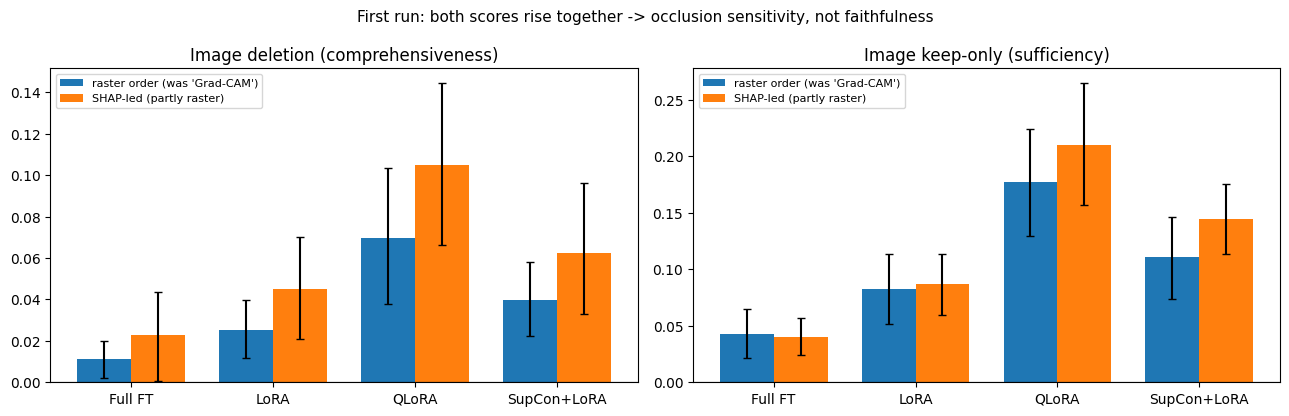

In [ ]:
# Figure IX-1 - the occlusion-sensitivity ordering in the first run (re-labelled reading).
fig, axes = plt.subplots(1, 2, figsize=(13, 4.2), sharey=False)
x = np.arange(len(STRATEGY_ORDER)); w = 0.38
panels = [("comp", "Image deletion (comprehensiveness)"), ("suff", "Image keep-only (sufficiency)")]
for ax, (kind, title) in zip(axes, panels):
    for j, (method, name) in enumerate([("gradcam_image", "raster order (was 'Grad-CAM')"),
                                        ("shap_image", "SHAP-led (partly raster)")]):
        vals = [raw[f"{method}_{kind}"][s] for s in STRATEGY_ORDER]
        mean = np.array([v[0] for v in vals]); lo = np.array([v[1] for v in vals]); hi = np.array([v[2] for v in vals])
        ax.bar(x + (j - 0.5) * w, mean, w, yerr=[mean - lo, hi - mean], capsize=3, label=name)
    ax.set_xticks(x); ax.set_xticklabels([LABELS[s] for s in STRATEGY_ORDER])
    ax.set_title(title); ax.axhline(0, color="black", lw=0.8); ax.legend(fontsize=8)
fig.suptitle("First run: both scores rise together -> occlusion sensitivity, not faithfulness", fontsize=11)
plt.tight_layout(); plt.show()

## 35. Modality and correctness breakdowns — status: withdrawn

The first run reported text comprehensiveness several times larger than image
comprehensiveness for every strategy, and lower faithfulness on misclassified memes. Both are
recorded here for completeness.

In [ ]:
# Table IX-2 - modality gap and correct/incorrect split (first run).
table4 = pd.DataFrame({
    "text comp (SHAP)":  [0.1505, 0.2186, 0.2562, 0.1367],
    "image comp (SHAP)": [0.0227, 0.0452, 0.1047, 0.0626],
    "text - image":      [0.1278, 0.1735, 0.1515, 0.0741],
    "text comp, correct":   [0.1870, 0.2383, 0.2808, 0.1793],
    "text comp, incorrect": [0.0752, 0.1768, 0.2241, 0.0728],
    "correct - incorrect":  [0.1118, 0.0615, 0.0566, 0.1064],
    "n correct (of 150)":   [101, 102, 85, 90],
}, index=pd.Index(STRATEGY_ORDER, name="strategy"))
print("Table IX-2. Modality gap and correctness split, first run")
display(table4)

Table IX-2. Modality gap and correctness split, first run


,text comp (SHAP),image comp (SHAP),text - image,"text comp, correct","text comp, incorrect",correct - incorrect,n correct (of 150)
strategy,,,,,,,
full_ft,0.1505,0.0227,0.1278,0.1870,0.0752,0.1118,101
lora,0.2186,0.0452,0.1735,0.2383,0.1768,0.0615,102
qlora,0.2562,0.1047,0.1515,0.2808,0.2241,0.0566,85
supcon_lora,0.1367,0.0626,0.0741,0.1793,0.0728,0.1064,90


**Why both are withdrawn.**

- *Text minus image* compares two different operations. The text side is caption
  **truncation** (F-19); the image side is patch **occlusion**. Even with correct operators,
  the scales differ (section 31, caution 1). The claim that the model relies more on the caption
  may well be true, and the full-FT occlusion result points that way, but this table cannot
  support it.
- *Correct minus incorrect* inherits the truncation problem. Its direction, lower faithfulness
  on errors, is plausible and common in the literature. Section 44 re-tests it on the corrected
  run.

## 36. Cross-strategy contrasts — status: superseded

Paired bootstrap differences against LoRA. The 95% intervals were not corrected for multiple
comparisons (nine contrasts).

In [ ]:
# Table IX-3 - first-run raw contrasts against LoRA (uncorrected paired bootstrap).
table5 = pd.DataFrame([
    ("gradcam_image_comp", "full_ft - lora",     -0.0143, -0.0314, +0.0040),
    ("gradcam_image_comp", "qlora - lora",       +0.0442, +0.0138, +0.0771),
    ("gradcam_image_comp", "supcon_lora - lora", +0.0144, -0.0022, +0.0309),
    ("shap_image_comp",    "full_ft - lora",     -0.0225, -0.0548, +0.0091),
    ("shap_image_comp",    "qlora - lora",       +0.0596, +0.0209, +0.0997),
    ("shap_image_comp",    "supcon_lora - lora", +0.0175, -0.0107, +0.0458),
    ("shap_text_comp",     "full_ft - lora",     -0.0681, -0.1251, -0.0167),
    ("shap_text_comp",     "qlora - lora",       +0.0376, -0.0256, +0.1012),
    ("shap_text_comp",     "supcon_lora - lora", -0.0819, -0.1397, -0.0251),
], columns=["metric", "contrast", "difference", "ci_lo", "ci_hi"])
table5["CI excludes 0 (uncorrected)"] = (table5.ci_lo > 0) | (table5.ci_hi < 0)
print("Table IX-3. First-run contrasts against LoRA, paired bootstrap 95% CI, no correction")
display(table5.set_index(["metric", "contrast"]))

Table IX-3. First-run contrasts against LoRA, paired bootstrap 95% CI, no correction


difference   ci_lo   ci_hi  CI excludes 0 (uncorrected)
metric             contrast                                                                   
gradcam_image_comp full_ft - lora         -0.0143 -0.0314  0.0040                        False
                   qlora - lora            0.0442  0.0138  0.0771                         True
                   supcon_lora - lora      0.0144 -0.0022  0.0309                        False
shap_image_comp    full_ft - lora         -0.0225 -0.0548  0.0091                        False
                   qlora - lora            0.0596  0.0209  0.0997                         True
                   supcon_lora - lora      0.0175 -0.0107  0.0458                        False
shap_text_comp     full_ft - lora         -0.0681 -0.1251 -0.0167                         True
                   qlora - lora            0.0376 -0.0256  0.1012                        False
                   supcon_lora - lora     -0.0819 -0.1397 -0.0251                         True

**Reading.** QLoRA's higher image comprehensiveness than LoRA is the occlusion-sensitivity
ordering from section 34 again; QLoRA's sufficiency is also higher, so this is fragility, not
better explanation. The two text contrasts measure sensitivity to caption truncation. None of
the nine has been corrected for multiplicity, and Part X replaces them.

## 37. The baseline-adjusted analysis — status: withdrawn

The first run also compared each attribution with a random baseline (24 tests) and compared
strategies on the adjusted scores (18 contrasts). Both tables are recorded because they were
circulated, but neither should be reported. The random baseline came from a different pipeline
(F-21), and the second table's correction was never applied (F-22).

The random means are not printed in the first run's output. They are recovered below as
*attribution mean − reported difference*.

In [ ]:
# Table IX-4 - first-run "attribution vs random" (24 tests), with the implied random means.
t6 = pd.DataFrame([
    # strategy, metric, attribution mean, reported diff, ci_lo, ci_hi, p (one-sided), Holm significant
    ("full_ft", "Grad-CAM img comp", 0.0110, +0.0126, +0.0003, +0.0254, 0.0229, False),
    ("full_ft", "Grad-CAM img suff", 0.0431, -0.0094, -0.0433, +0.0242, 0.7051, False),
    ("full_ft", "SHAP img comp",     0.0227, +0.0242, +0.0023, +0.0473, 0.0159, False),
    ("full_ft", "SHAP img suff",     0.0404, -0.0120, -0.0456, +0.0214, 0.7559, False),
    ("full_ft", "SHAP text comp",    0.1505, +0.1713, +0.1124, +0.2312, 0.0000, True),
    ("full_ft", "SHAP text suff",    0.1559, +0.1500, +0.0932, +0.2047, 0.0000, True),
    ("lora", "Grad-CAM img comp",    0.0253, +0.1121, +0.0851, +0.1393, 0.0000, True),
    ("lora", "Grad-CAM img suff",    0.0829, +0.0126, -0.0401, +0.0676, 0.3187, False),
    ("lora", "SHAP img comp",        0.0452, +0.1320, +0.0985, +0.1655, 0.0000, True),
    ("lora", "SHAP img suff",        0.0868, +0.0165, -0.0327, +0.0670, 0.2544, False),
    ("lora", "SHAP text comp",       0.2186, +0.2295, +0.1724, +0.2876, 0.0000, True),
    ("lora", "SHAP text suff",       0.1808, +0.0863, +0.0284, +0.1434, 0.0014, True),
    ("qlora", "Grad-CAM img comp",   0.0695, +0.1701, +0.1180, +0.2257, 0.0000, True),
    ("qlora", "Grad-CAM img suff",   0.1771, +0.1031, +0.0269, +0.1767, 0.0039, True),
    ("qlora", "SHAP img comp",       0.1047, +0.2053, +0.1484, +0.2650, 0.0000, True),
    ("qlora", "SHAP img suff",       0.2095, +0.1355, +0.0550, +0.2180, 0.0007, True),
    ("qlora", "SHAP text comp",      0.2562, +0.2742, +0.2031, +0.3472, 0.0000, True),
    ("qlora", "SHAP text suff",      0.2005, +0.0872, +0.0091, +0.1636, 0.0150, False),
    ("supcon_lora", "Grad-CAM img comp", 0.0397, +0.1186, +0.0843, +0.1537, 0.0000, True),
    ("supcon_lora", "Grad-CAM img suff", 0.1108, +0.0686, +0.0114, +0.1280, 0.0086, False),
    ("supcon_lora", "SHAP img comp",     0.0626, +0.1416, +0.0986, +0.1858, 0.0000, True),
    ("supcon_lora", "SHAP img suff",     0.1440, +0.1018, +0.0462, +0.1596, 0.0002, True),
    ("supcon_lora", "SHAP text comp",    0.1367, +0.1622, +0.1034, +0.2238, 0.0000, True),
    ("supcon_lora", "SHAP text suff",    0.1143, +0.0888, +0.0290, +0.1496, 0.0023, True),
], columns=["strategy", "metric", "attribution mean", "reported difference", "ci_lo", "ci_hi",
            "p (one-sided)", "reported significant"])
t6["implied random mean"] = t6["attribution mean"] - t6["reported difference"]
print("Table IX-4. First-run attribution vs 'random' (withdrawn). Note the implied random means.")
display(t6.set_index(["strategy", "metric"]).round(4))

implied = (t6[t6.metric.str.contains("comp")]
           .assign(modality=lambda d: np.where(d.metric.str.contains("text"), "text", "image"))
           .groupby(["strategy", "modality"])["implied random mean"].first().unstack())
print("Implied random comprehensiveness by strategy and modality")
display(implied.loc[STRATEGY_ORDER].round(4))

Table IX-4. First-run attribution vs 'random' (withdrawn). Note the implied random means.


attribution mean  reported difference   ci_lo   ci_hi  p (one-sided)  reported significant  implied random mean
strategy    metric                                                                                                                            
full_ft     Grad-CAM img comp            0.0110               0.0126  0.0003  0.0254         0.0229                 False              -0.0016
            Grad-CAM img suff            0.0431              -0.0094 -0.0433  0.0242         0.7051                 False               0.0525
            SHAP img comp                0.0227               0.0242  0.0023  0.0473         0.0159                 False              -0.0015
            SHAP img suff                0.0404              -0.0120 -0.0456  0.0214         0.7559                 False               0.0524
            SHAP text comp               0.1505               0.1713  0.1124  0.2312         0.0000                  True              -0.0208
            SHAP text suff               0.1559               0.1500  0.0932  0.2047         0.0000                  True               0.0059
lora        Grad-CAM img comp            0.0253               0.1121  0.0851  0.1393         0.0000                  True              -0.0868
            Grad-CAM img suff            0.0829               0.0126 -0.0401  0.0676         0.3187                 False               0.0703
            SHAP img comp                0.0452               0.1320  0.0985  0.1655         0.0000                  True              -0.0868
            SHAP img suff                0.0868               0.0165 -0.0327  0.0670         0.2544                 False               0.0703
            SHAP text comp               0.2186               0.2295  0.1724  0.2876         0.0000                  True              -0.0109
            SHAP text suff               0.1808               0.0863  0.0284  0.1434         0.0014                  True               0.0945
qlora       Grad-CAM img comp            0.0695               0.1701  0.1180  0.2257         0.0000                  True              -0.1006
            Grad-CAM img suff            0.1771               0.1031  0.0269  0.1767         0.0039                  True               0.0740
            SHAP img comp                0.1047               0.2053  0.1484  0.2650         0.0000                  True              -0.1006
            SHAP img suff                0.2095               0.1355  0.0550  0.2180         0.0007                  True               0.0740
            SHAP text comp               0.2562               0.2742  0.2031  0.3472         0.0000                  True              -0.0180
            SHAP text suff               0.2005               0.0872  0.0091  0.1636         0.0150                 False               0.1133
supcon_lora Grad-CAM img comp            0.0397               0.1186  0.0843  0.1537         0.0000                  True              -0.0789
            Grad-CAM img suff            0.1108               0.0686  0.0114  0.1280         0.0086                 False               0.0422
            SHAP img comp                0.0626               0.1416  0.0986  0.1858         0.0000                  True              -0.0790
            SHAP img suff                0.1440               0.1018  0.0462  0.1596         0.0002                  True               0.0422
            SHAP text comp               0.1367               0.1622  0.1034  0.2238         0.0000                  True              -0.0255
            SHAP text suff               0.1143               0.0888  0.0290  0.1496         0.0023                  True               0.0255

Implied random comprehensiveness by strategy and modality


modality,image,text
strategy,,
full_ft,-0.0016,-0.0208
lora,-0.0868,-0.0109
qlora,-0.1006,-0.0180
supcon_lora,-0.0789,-0.0255


**Why Table IX-4 is withdrawn.** The implied random comprehensiveness for the three
parameter-efficient models is about **−0.08 to −0.10** on images. That would mean deleting
random patches makes those models *more* confident in their own prediction, by eight to ten
points on average. Correctly oriented random deletion does not do that.

This is consistent with the sign pattern section 31 describes for scores computed on
$P(\text{hateful})$ instead of the predicted class. The pipeline also used 196 patches for a 49-patch model and a
single 20% cut-off. Every "beats random" verdict for the parameter-efficient models is
therefore produced by a random baseline that is negative. In Table IX-4, LoRA's image
comprehensiveness of 0.025 counted as 0.112 above random almost entirely because the "random"
value was −0.087.

In [ ]:
# Table IX-5 - first-run cross-strategy contrasts on baseline-adjusted scores (withdrawn).
table7 = pd.DataFrame([
    ("lora - full_ft", "Grad-CAM img comp", +0.0995, +0.0694, +0.1294, True),
    ("lora - full_ft", "Grad-CAM img suff", +0.0220, -0.0261, +0.0710, False),
    ("lora - full_ft", "SHAP img comp",     +0.1077, +0.0684, +0.1468, True),
    ("lora - full_ft", "SHAP img suff",     +0.0286, -0.0164, +0.0742, False),
    ("lora - full_ft", "SHAP text comp",    +0.0582, +0.0026, +0.1155, True),
    ("lora - full_ft", "SHAP text suff",    -0.0637, -0.1224, -0.0033, True),
    ("qlora - lora", "Grad-CAM img comp",   +0.0580, +0.0091, +0.1089, True),
    ("qlora - lora", "Grad-CAM img suff",   +0.0904, +0.0222, +0.1593, True),
    ("qlora - lora", "SHAP img comp",       +0.0734, +0.0179, +0.1307, True),
    ("qlora - lora", "SHAP img suff",       +0.1190, +0.0372, +0.1994, True),
    ("qlora - lora", "SHAP text comp",      +0.0447, -0.0210, +0.1094, False),
    ("qlora - lora", "SHAP text suff",      +0.0008, -0.0624, +0.0621, False),
    ("supcon_lora - lora", "Grad-CAM img comp", +0.0065, -0.0213, +0.0354, False),
    ("supcon_lora - lora", "Grad-CAM img suff", +0.0559, +0.0098, +0.1013, True),
    ("supcon_lora - lora", "SHAP img comp",     +0.0096, -0.0260, +0.0464, False),
    ("supcon_lora - lora", "SHAP img suff",     +0.0853, +0.0407, +0.1314, True),
    ("supcon_lora - lora", "SHAP text comp",    -0.0674, -0.1273, -0.0103, True),
    ("supcon_lora - lora", "SHAP text suff",    +0.0024, -0.0557, +0.0580, False),
], columns=["contrast", "metric", "difference", "ci_lo", "ci_hi", "reported significant"])
print("Table IX-5. First-run contrasts on 'adjusted' scores (withdrawn; Holm was not applied)")
display(table7.set_index(["contrast", "metric"]))
print(f"Reported significant: {int(table7['reported significant'].sum())}/18 "
      "- each is simply a 95% CI excluding zero, with no correction.")

Table IX-5. First-run contrasts on 'adjusted' scores (withdrawn; Holm was not applied)


difference   ci_lo   ci_hi  reported significant
contrast           metric                                                             
lora - full_ft     Grad-CAM img comp      0.0995  0.0694  0.1294                  True
                   Grad-CAM img suff      0.0220 -0.0261  0.0710                 False
                   SHAP img comp          0.1077  0.0684  0.1468                  True
                   SHAP img suff          0.0286 -0.0164  0.0742                 False
                   SHAP text comp         0.0582  0.0026  0.1155                  True
                   SHAP text suff        -0.0637 -0.1224 -0.0033                  True
qlora - lora       Grad-CAM img comp      0.0580  0.0091  0.1089                  True
                   Grad-CAM img suff      0.0904  0.0222  0.1593                  True
                   SHAP img comp          0.0734  0.0179  0.1307                  True
                   SHAP img suff          0.1190  0.0372  0.1994                  True
                   SHAP text comp         0.0447 -0.0210  0.1094                 False
                   SHAP text suff         0.0008 -0.0624  0.0621                 False
supcon_lora - lora Grad-CAM img comp      0.0065 -0.0213  0.0354                 False
                   Grad-CAM img suff      0.0559  0.0098  0.1013                  True
                   SHAP img comp          0.0096 -0.0260  0.0464                 False
                   SHAP img suff          0.0853  0.0407  0.1314                  True
                   SHAP text comp        -0.0674 -0.1273 -0.0103                  True
                   SHAP text suff         0.0024 -0.0557  0.0580                 False

Reported significant: 11/18 - each is simply a 95% CI excluding zero, with no correction.


**Why Table IX-5 is withdrawn.** Three reasons, any one of which is sufficient:

1. **It inherits Table IX-4's random baseline.**
2. **The Holm step was never applied.** The code orders contrasts by size and calls a contrast
   significant whenever its uncorrected 95% interval excludes zero (F-22).
3. **The baseline creates its own results.** On raw scores, LoRA minus full FT for Grad-CAM
   image comprehensiveness is −0.014 and not resolved (Table IX-3). After "adjustment" it becomes
   +0.0995 and significant. The adjustment produced the result.

## 38. What the first run can and cannot support

In [ ]:
# Table IX-6 - validity register for every first-run explainability result.
table8 = pd.DataFrame([
    ("Classification, AUROC, DeLong (section 19b)", "Valid", "Report as is"),
    ("Occlusion-sensitivity ordering, Full FT < LoRA < SupCon < QLoRA (Table IX-1, image)",
     "Re-labelled", "Report as model sensitivity to image occlusion, not as faithfulness"),
    ("Full FT predictions nearly insensitive to image occlusion",
     "Re-labelled", "Report with the same label; consistent with caption reliance"),
    ("Grad-CAM comprehensiveness and sufficiency (all strategies)",
     "Superseded", "Every map was zero (F-18); replace with Part X"),
    ("Image SHAP comprehensiveness and sufficiency",
     "Superseded", "Sparse values (F-20); replace with Part X"),
    ("Text SHAP comprehensiveness and sufficiency",
     "Superseded", "Masking was truncation (F-19); replace with Part X"),
    ("Text dominance, i.e. text comp >> image comp (Table IX-2)",
     "Withdrawn", "Compares truncation with occlusion on different scales"),
    ("Lower faithfulness on misclassified memes (Table IX-2)",
     "Withdrawn", "Inherits F-19; re-tested in section 44"),
    ("Contrasts against LoRA (Table IX-3)",
     "Superseded", "Uncorrected; replace with Part X"),
    ("Attribution vs random (Table IX-4)",
     "Withdrawn", "Unmatched baseline with implied negative random comprehensiveness (F-21)"),
    ("Contrasts on adjusted scores (Table IX-5)",
     "Withdrawn", "F-21 plus no multiplicity correction (F-22)"),
], columns=["result", "status", "action"]).set_index("result")
print("Table IX-6. Validity register for the first explainability run")
display(table8)

Table IX-6. Validity register for the first explainability run


,status,action
result,,
"Classification, AUROC, DeLong (section 19b)",Valid,Report as is
"Occlusion-sensitivity ordering, Full FT < LoRA < SupCon < QLoRA (Table IX-1, image)",Re-labelled,Report as model sensitivity to image occlusion...
Full FT predictions nearly insensitive to image occlusion,Re-labelled,Report with the same label; consistent with ca...
Grad-CAM comprehensiveness and sufficiency (all strategies),Superseded,Every map was zero (F-18); replace with Part X
Image SHAP comprehensiveness and sufficiency,Superseded,Sparse values (F-20); replace with Part X
Text SHAP comprehensiveness and sufficiency,Superseded,Masking was truncation (F-19); replace with Pa...
"Text dominance, i.e. text comp >> image comp (Table IX-2)",Withdrawn,Compares truncation with occlusion on differen...
Lower faithfulness on misclassified memes (Table IX-2),Withdrawn,Inherits F-19; re-tested in section 44
Contrasts against LoRA (Table IX-3),Superseded,Uncorrected; replace with Part X


**In one paragraph.** The first run is a valid measurement of how strongly each model's
prediction responds to occluding image content. On that measure, full fine-tuning is the least
responsive and QLoRA the most. It is not a valid measurement of explanation faithfulness: the
Grad-CAM maps were empty, the text operator truncated captions, the SHAP values were sparse,
and the random baseline was unmatched. The corrected pipeline in Part VIII removes all four
problems, and Parts X–XI analyse its output.

---
# Part X — Corrected analysis

This part reads the per-meme files written in section 32 and re-scored in section 32b (run 32b
first). It needs no GPU and no model, so it can run in a fresh session once Drive is mounted. Set `ANALYSIS_TAG = "corrected_quick"` to try
it on the smoke-test output first.

## 39. Statistical toolkit

**Pairing.** All four strategies are scored on the same memes. Some memes are easier to explain
than others whatever the model, so the analysis resamples **memes** and keeps each meme's scores
together. This removes the shared difficulty from every comparison (paired bootstrap; Efron &
Tibshirani, 1993).

**Quantities.**

| Quantity | Per meme | Question |
|---|---|---|
| Gain over random | method score − random score, oriented so that positive = better | Does the explanation beat a meaningless ranking? |
| Contrast | gain under strategy A − gain under strategy B | Is A's explanation more faithful than B's? |

**p-values.** Two-sided: $2\min\{\Pr^*(\bar d^* \le 0), \Pr^*(\bar d^* \ge 0)\}$, from 10,000
bootstrap means. The smallest reportable value is 0.0001, shown as "< 0.0001".

**Families of tests.** Each family is corrected with Holm's (1979) step-down procedure, which
controls the chance of any false positive at 5%. The families are fixed in advance:

| Family | Contents | Tests |
|---|---|---|
| Beats random | 4 strategies × 10 metrics (Grad-CAM, transformer attribution and SHAP) | 40 |
| **Primary contrasts (RQ2)** | Q1–Q3 × the 6 Grad-CAM and SHAP metrics | 18 |
| Supplementary contrasts | Q1–Q3 × the 4 transformer-attribution metrics | 12 |
| Exploratory contrasts | The other three strategy pairs × 10 metrics | 30 |
| Robustness | Each family above repeated under blur (image metrics) and on the logit scale | Separate families |

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
from IPython.display import display
from scipy.stats import spearmanr

RESULTS_DIR = (CONFIG["results_dir"] if "CONFIG" in globals()
               else Path("/content/drive/MyDrive/honours-clip/results"))
XAI_DIR = RESULTS_DIR / "xai"
SEED    = CONFIG["seed"] if "CONFIG" in globals() else 42

ANALYSIS_TAG = "corrected"          # "corrected_quick" to analyse the smoke test
N_BOOT, ALPHA = 10_000, 0.05
STRATEGY_ORDER = ["full_ft", "lora", "qlora", "supcon_lora"]
LABELS = {"full_ft": "Full FT", "lora": "LoRA", "qlora": "QLoRA", "supcon_lora": "SupCon+LoRA"}
METHOD_NAMES = {"gradcam": "Grad-CAM", "chefer": "Transformer attr.", "shap": "SHAP"}

# key: (column prefix, kind, modality, role)
METRICS = {}
for method, modality, role in [("gradcam", "image", "primary"), ("shap", "image", "primary"),
                               ("shap", "text", "primary"), ("chefer", "image", "supplementary"),
                               ("chefer", "text", "supplementary")]:
    for kind in ("comp", "suff"):
        METRICS[f"{method}_{modality}_{kind}"] = (f"{method}_{modality}", kind, modality, role)
PRIMARY_KEYS = [k for k, v in METRICS.items() if v[3] == "primary"]
SUPP_KEYS    = [k for k, v in METRICS.items() if v[3] == "supplementary"]
ALL_KEYS     = PRIMARY_KEYS + SUPP_KEYS
VARIANTS = {"": "main (probability, mean colour)", "_blur": "robustness: blur",
            "_logit": "robustness: logit scale"}


def label_of(key):
    prefix, kind, modality, _ = METRICS[key]
    return f"{METHOD_NAMES[prefix.split('_')[0]]} | {modality} | {kind}"


def keys_for(variant, keys):
    """Blur applies to image metrics only."""
    return [k for k in keys if variant != "_blur" or METRICS[k][2] == "image"]


def load_per_example(tag=ANALYSIS_TAG):
    per = {}
    for s in STRATEGY_ORDER:
        f = XAI_DIR / f"per_example_{s}_{tag}.csv"
        if f.exists():
            per[s] = pd.read_csv(f).drop_duplicates("index").set_index("index")
    if not per:
        raise FileNotFoundError(f"no per_example_*_{tag}.csv in {XAI_DIR}; run section 32 first")
    shared = sorted(set.intersection(*(set(d.index) for d in per.values())))
    return {s: d.loc[shared] for s, d in per.items()}, shared


def faithfulness_score(df, key, variant="", on="gain"):
    """Per-meme score oriented so that HIGHER = MORE FAITHFUL."""
    prefix, kind, modality, _ = METRICS[key]
    col, rnd = f"{prefix}_{kind}{variant}", f"random_{modality}_{kind}{variant}"
    if on == "raw":
        return df[col] if kind == "comp" else -df[col]
    return df[col] - df[rnd] if kind == "comp" else df[rnd] - df[col]


def paired_bootstrap(diff, n_boot=N_BOOT, seed=SEED):
    d = np.asarray(diff, dtype=float)
    d = d[~np.isnan(d)]
    rng = np.random.default_rng(seed)
    boot = d[rng.integers(0, len(d), size=(n_boot, len(d)))].mean(axis=1)
    lo, hi = np.percentile(boot, [2.5, 97.5])
    p = 2 * min((boot <= 0).mean(), (boot >= 0).mean())
    return dict(n=len(d), mean=float(d.mean()), ci_lo=float(lo), ci_hi=float(hi),
                p=float(min(1.0, max(p, 1 / n_boot))))


def bootstrap_mean_difference(a, b, n_boot=N_BOOT, seed=SEED):
    """Unpaired: mean(a) - mean(b), each group resampled separately."""
    a = np.asarray(a, float); a = a[~np.isnan(a)]
    b = np.asarray(b, float); b = b[~np.isnan(b)]
    rng = np.random.default_rng(seed)
    boot = (a[rng.integers(0, len(a), (n_boot, len(a)))].mean(1)
            - b[rng.integers(0, len(b), (n_boot, len(b)))].mean(1))
    lo, hi = np.percentile(boot, [2.5, 97.5])
    p = 2 * min((boot <= 0).mean(), (boot >= 0).mean())
    return dict(diff=float(a.mean() - b.mean()), ci_lo=float(lo), ci_hi=float(hi),
                p=float(min(1.0, max(p, 1 / n_boot))), n_a=len(a), n_b=len(b))


def holm(pvals):
    p = np.asarray(pvals, dtype=float)
    adjusted, running = np.empty_like(p), 0.0
    for rank, i in enumerate(np.argsort(p)):
        running = max(running, min(1.0, (len(p) - rank) * p[i]))
        adjusted[i] = running
    return adjusted


fmt_p  = lambda p: "< 0.0001" if p < 1e-4 else f"{p:.4f}"
fmt_ci = lambda r: f"{r['mean']:+.4f} [{r['ci_lo']:+.4f}, {r['ci_hi']:+.4f}]"

assert np.allclose(holm([0.01, 0.04, 0.03, 0.005]), [0.03, 0.06, 0.06, 0.02])
assert paired_bootstrap(np.random.default_rng(0).normal(0, 1, 300))["p"] > 0.05
assert paired_bootstrap(np.random.default_rng(0).normal(0.5, 1, 300))["p"] < 0.001

per, shared = load_per_example()
order = [s for s in STRATEGY_ORDER if s in per]
print(f"Loaded '{ANALYSIS_TAG}': {len(shared)} memes shared by {', '.join(LABELS[s] for s in order)}")

Loaded 'corrected': 600 memes shared by Full FT, LoRA, QLoRA, SupCon+LoRA


## 40. Faithfulness summary tables

These are mean ERASER scores (main setting) with bootstrap 95% intervals, shown next to the
matched random baseline. Compare each method row with the random row for the same modality: the
gap matters more than the absolute value.

In [ ]:
def summary_table(kind):
    rows = []
    for s in order:
        d = per[s]
        for col, name in [(f"gradcam_image_{kind}", "Grad-CAM (image)"),
                          (f"chefer_image_{kind}", "Transformer attr. (image)"),
                          (f"shap_image_{kind}", "SHAP (image)"),
                          (f"random_image_{kind}", "random (image)"),
                          (f"chefer_text_{kind}", "Transformer attr. (text)"),
                          (f"shap_text_{kind}", "SHAP (text)"),
                          (f"random_text_{kind}", "random (text)")]:
            rows.append({"strategy": LABELS[s], "ranking": name, "cell": fmt_ci(paired_bootstrap(d[col]))})
    t = pd.DataFrame(rows).pivot(index="ranking", columns="strategy", values="cell")
    return t.loc[["Grad-CAM (image)", "Transformer attr. (image)", "SHAP (image)", "random (image)",
                  "Transformer attr. (text)", "SHAP (text)", "random (text)"],
                 [LABELS[s] for s in order]]


print("Table X1. Comprehensiveness, AOPC (higher = more faithful). Mean [95% CI]")
display(summary_table("comp"))
print("Table X2. Sufficiency, AOPC (lower = more faithful). Mean [95% CI]")
display(summary_table("suff"))
print("Table X3. Prediction context on the subsample")
display(pd.DataFrame({
    "accuracy on subsample": {LABELS[s]: per[s]["correct"].mean() for s in order},
    "errors (n)":            {LABELS[s]: int((1 - per[s]["correct"]).sum()) for s in order},
    "mean confidence":       {LABELS[s]: per[s]["confidence"].mean() for s in order},
    "mean caption tokens":   {LABELS[s]: per[s]["n_tokens"].mean() for s in order},
}).round(4))

Table X1. Comprehensiveness, AOPC (higher = more faithful). Mean [95% CI]


strategy,Full FT,LoRA,QLoRA,SupCon+LoRA
ranking,,,,
Grad-CAM (image),"+0.0593 [+0.0523, +0.0666]","+0.0857 [+0.0768, +0.0952]","+0.1660 [+0.1481, +0.1848]","+0.1125 [+0.1009, +0.1246]"
Transformer attr. (image),"+0.0611 [+0.0525, +0.0697]","+0.0922 [+0.0821, +0.1029]","+0.1633 [+0.1443, +0.1831]","+0.1143 [+0.1013, +0.1275]"
SHAP (image),"+0.0884 [+0.0806, +0.0966]","+0.1959 [+0.1845, +0.2075]","+0.3329 [+0.3084, +0.3577]","+0.2580 [+0.2417, +0.2744]"
random (image),"+0.0033 [+0.0005, +0.0061]","+0.0285 [+0.0236, +0.0332]","+0.0790 [+0.0687, +0.0896]","+0.0461 [+0.0404, +0.0520]"
Transformer attr. (text),"+0.1358 [+0.1160, +0.1562]","+0.1076 [+0.0890, +0.1264]","+0.1585 [+0.1345, +0.1830]","+0.0903 [+0.0729, +0.1081]"
SHAP (text),"+0.2324 [+0.2141, +0.2508]","+0.2234 [+0.2071, +0.2406]","+0.2911 [+0.2639, +0.3182]","+0.2199 [+0.2017, +0.2386]"
random (text),"+0.0313 [+0.0248, +0.0378]","+0.0345 [+0.0283, +0.0407]","+0.0615 [+0.0524, +0.0707]","+0.0359 [+0.0291, +0.0429]"


Table X2. Sufficiency, AOPC (lower = more faithful). Mean [95% CI]


strategy,Full FT,LoRA,QLoRA,SupCon+LoRA
ranking,,,,
Grad-CAM (image),"-0.0203 [-0.0304, -0.0103]","+0.0207 [+0.0065, +0.0349]","+0.1299 [+0.1081, +0.1524]","+0.0435 [+0.0276, +0.0597]"
Transformer attr. (image),"-0.0153 [-0.0236, -0.0070]","+0.0514 [+0.0392, +0.0639]","+0.1616 [+0.1391, +0.1842]","+0.0810 [+0.0666, +0.0961]"
SHAP (image),"-0.0528 [-0.0615, -0.0440]","-0.0302 [-0.0422, -0.0185]","+0.0595 [+0.0423, +0.0773]","-0.0083 [-0.0205, +0.0042]"
random (image),"+0.0298 [+0.0186, +0.0410]","+0.0810 [+0.0669, +0.0955]","+0.1947 [+0.1718, +0.2180]","+0.1180 [+0.1008, +0.1357]"
Transformer attr. (text),"+0.0445 [+0.0304, +0.0589]","+0.0723 [+0.0566, +0.0885]","+0.1013 [+0.0810, +0.1221]","+0.0676 [+0.0508, +0.0845]"
SHAP (text),"-0.0299 [-0.0434, -0.0165]","-0.0049 [-0.0204, +0.0110]","+0.0431 [+0.0256, +0.0605]","-0.0016 [-0.0165, +0.0135]"
random (text),"+0.1269 [+0.1066, +0.1469]","+0.1287 [+0.1070, +0.1511]","+0.1536 [+0.1284, +0.1792]","+0.1011 [+0.0801, +0.1219]"


Table X3. Prediction context on the subsample


,accuracy on subsample,errors (n),mean confidence,mean caption tokens
Full FT,0.6317,221,0.8031,11.5217
LoRA,0.6483,211,0.8166,11.5217
QLoRA,0.6000,240,0.9450,11.5217
SupCon+LoRA,0.6133,232,0.8835,11.5217


#### Interpretation — faithfulness scores (Tables X1–X3)

**Image.**

| | Full FT | LoRA | QLoRA | SupCon+LoRA |
|---|---|---|---|---|
| Grad-CAM comprehensiveness | 0.059 | 0.086 | 0.166 | 0.113 |
| Transformer attr. comprehensiveness | 0.061 | 0.092 | 0.163 | 0.114 |
| KernelSHAP comprehensiveness | 0.088 | 0.196 | 0.333 | 0.258 |
| Random comprehensiveness | 0.003 | 0.029 | 0.079 | 0.046 |
| Grad-CAM sufficiency | −0.020 | 0.021 | 0.130 | 0.044 |
| Transformer attr. sufficiency | −0.015 | 0.051 | 0.162 | 0.081 |
| KernelSHAP sufficiency | −0.053 | −0.030 | 0.060 | −0.008 |
| Random sufficiency | 0.030 | 0.081 | 0.195 | 0.118 |

**Text.**

| | Full FT | LoRA | QLoRA | SupCon+LoRA |
|---|---|---|---|---|
| Transformer attr. comprehensiveness | 0.136 | 0.108 | 0.159 | 0.090 |
| KernelSHAP comprehensiveness | 0.232 | 0.223 | 0.291 | 0.220 |
| Random comprehensiveness | 0.031 | 0.035 | 0.062 | 0.036 |
| Transformer attr. sufficiency | 0.045 | 0.072 | 0.101 | 0.068 |
| KernelSHAP sufficiency | −0.030 | −0.005 | 0.043 | −0.002 |
| Random sufficiency | 0.127 | 0.129 | 0.154 | 0.101 |

- **Every method behaves as a faithful explanation should, for every strategy.** Comprehensiveness
  is well above random and sufficiency well below it.
- **KernelSHAP is the strongest method.** Deleting its top features lowers confidence by 0.09–0.33
  (image) and 0.22–0.29 (text). Keeping only them leaves the decision essentially unchanged
  (sufficiency between −0.05 and +0.06). KernelSHAP is fitted with the same removal operator that
  ERASER uses, which gives it a structural advantage in deletion tests (section 47).
- **Grad-CAM and the transformer attribution agree closely on images** (comprehensiveness
  0.06–0.17), as expected from two gradient-based methods reading the same attention layers.
- **Full fine-tuning** has the lowest image scores and almost no reaction to random patch deletion
  (0.003), consistent with its weak reliance on the image (section 44).
- **QLoRA has the largest scores for every ranking, random included.** Its predictions move most
  under any change, which is why strategies are compared on gains over random.
- **Context.** In ERASER's text benchmarks, perturbation methods (the family KernelSHAP belongs to)
  reached comprehensiveness of 0.21–0.44, and gradient methods 0.06–0.18. Here KernelSHAP reaches
  0.22–0.29 on text and Grad-CAM 0.06–0.17 on images.

**Prediction context (Table X3).**

- Accuracy at 0.5 on the balanced 600 is 0.60–0.65, so each model makes 211–240 errors, enough to
  compare explanations of correct and incorrect decisions.
- Mean confidence is 0.80–0.95. QLoRA is the most confident (0.945) and the least accurate
  (0.600), which means it is overconfident.

## 41. Do the explanations beat random?

This is the minimum bar for any faithfulness claim. A method that cannot outperform a random
ranking *on the same model and the same memes* has not shown that it identifies evidence the
model uses (Adebayo et al., 2018; DeYoung et al., 2020).

The verdicts use Holm-adjusted p-values over all 40 tests.

- **"Beats random"** on comprehensiveness: deleting the top-ranked features hurts the decision
  more than deleting random ones.
- **"Beats random"** on sufficiency: keeping only the top-ranked features preserves the
  decision better than keeping random ones.
- **"Not distinguishable"** means the data do not resolve the difference. It does not mean the
  method is equivalent to random.

In [ ]:
def beats_random_table(variant="", keys=ALL_KEYS):
    rows = []
    for s in order:
        for key in keys_for(variant, keys):
            r = paired_bootstrap(faithfulness_score(per[s], key, variant))
            rows.append({"strategy": s, "metric": key, "label": label_of(key), **r})
    t = pd.DataFrame(rows)
    t["p_holm"] = holm(t["p"])
    t["verdict"] = np.select([(t.p_holm < ALPHA) & (t["mean"] > 0), (t.p_holm < ALPHA) & (t["mean"] < 0)],
                             ["beats random", "WORSE than random"], default="not distinguishable")
    return t


def show_tests(t, title, index=("strategy", "label")):
    out = t.assign(estimate=t.apply(fmt_ci, axis=1), p=t.p.map(fmt_p), p_holm=t.p_holm.map(fmt_p))
    if "strategy" in out:
        out["strategy"] = out["strategy"].map(LABELS)
    print(title)
    display(out.set_index(list(index))[["estimate", "p", "p_holm", "verdict"]])


beats_random = beats_random_table()
show_tests(beats_random, "Table X4. Gain over matched random baseline (positive = better), Holm over "
           f"{len(beats_random)} tests")
print(f"Beats random after Holm: {int((beats_random.verdict == 'beats random').sum())}/{len(beats_random)}")

Table X4. Gain over matched random baseline (positive = better), Holm over 40 tests


estimate       p  p_holm       verdict
strategy    label                                                                                     
Full FT     Grad-CAM | image | comp           +0.0559 [+0.0505, +0.0618]  0.0001  0.0040  beats random
            Grad-CAM | image | suff           +0.0501 [+0.0444, +0.0558]  0.0001  0.0040  beats random
            SHAP | image | comp               +0.0851 [+0.0786, +0.0919]  0.0001  0.0040  beats random
            SHAP | image | suff               +0.0825 [+0.0758, +0.0892]  0.0001  0.0040  beats random
            SHAP | text | comp                +0.2011 [+0.1872, +0.2149]  0.0001  0.0040  beats random
            SHAP | text | suff                +0.1568 [+0.1448, +0.1688]  0.0001  0.0040  beats random
            Transformer attr. | image | comp  +0.0578 [+0.0511, +0.0647]  0.0001  0.0040  beats random
            Transformer attr. | image | suff  +0.0451 [+0.0388, +0.0513]  0.0001  0.0040  beats random
            Transformer attr. | text | comp   +0.1046 [+0.0888, +0.1205]  0.0001  0.0040  beats random
            Transformer attr. | text | suff   +0.0824 [+0.0679, +0.0969]  0.0001  0.0040  beats random
LoRA        Grad-CAM | image | comp           +0.0573 [+0.0497, +0.0652]  0.0001  0.0040  beats random
            Grad-CAM | image | suff           +0.0603 [+0.0545, +0.0663]  0.0001  0.0040  beats random
            SHAP | image | comp               +0.1674 [+0.1582, +0.1771]  0.0001  0.0040  beats random
            SHAP | image | suff               +0.1112 [+0.1039, +0.1187]  0.0001  0.0040  beats random
            SHAP | text | comp                +0.1890 [+0.1763, +0.2021]  0.0001  0.0040  beats random
            SHAP | text | suff                +0.1337 [+0.1227, +0.1449]  0.0001  0.0040  beats random
            Transformer attr. | image | comp  +0.0638 [+0.0551, +0.0727]  0.0001  0.0040  beats random
            Transformer attr. | image | suff  +0.0296 [+0.0215, +0.0378]  0.0001  0.0040  beats random
            Transformer attr. | text | comp   +0.0732 [+0.0588, +0.0881]  0.0001  0.0040  beats random
            Transformer attr. | text | suff   +0.0564 [+0.0437, +0.0692]  0.0001  0.0040  beats random
QLoRA       Grad-CAM | image | comp           +0.0870 [+0.0727, +0.1016]  0.0001  0.0040  beats random
            Grad-CAM | image | suff           +0.0648 [+0.0548, +0.0748]  0.0001  0.0040  beats random
            SHAP | image | comp               +0.2539 [+0.2343, +0.2736]  0.0001  0.0040  beats random
            SHAP | image | suff               +0.1352 [+0.1217, +0.1490]  0.0001  0.0040  beats random
            SHAP | text | comp                +0.2297 [+0.2089, +0.2504]  0.0001  0.0040  beats random
            SHAP | text | suff                +0.1105 [+0.0963, +0.1251]  0.0001  0.0040  beats random
            Transformer attr. | image | comp  +0.0843 [+0.0681, +0.1006]  0.0001  0.0040  beats random
            Transformer attr. | image | suff  +0.0331 [+0.0210, +0.0452]  0.0001  0.0040  beats random
            Transformer attr. | text | comp   +0.0971 [+0.0788, +0.1156]  0.0001  0.0040  beats random
            Transformer attr. | text | suff   +0.0522 [+0.0393, +0.0655]  0.0001  0.0040  beats random
SupCon+LoRA Grad-CAM | image | comp           +0.0664 [+0.0562, +0.0767]  0.0001  0.0040  beats random
            Grad-CAM | image | suff           +0.0745 [+0.0662, +0.0830]  0.0001  0.0040  beats random
            SHAP | image | comp               +0.2119 [+0.1986, +0.2252]  0.0001  0.0040  beats random
            SHAP | image | suff               +0.1263 [+0.1153, +0.1375]  0.0001  0.0040  beats random
            SHAP | text | comp                +0.1840 [+0.1699, +0.1981]  0.0001  0.0040  beats random
            SHAP | text | suff                +0.1027 [+0.0917, +0.1137]  0.0001  0.0040  beats random
            Transformer attr. | image | comp  +0.0682 [+0.0577, +0.0788]  0.0001  0.0040  beats random
            Transformer attr. | image | suff  +

Beats random after Holm: 40/40


#### Interpretation — which explanations beat random (Table X4)

**All 40 tests beat random after Holm correction** (every adjusted p ≤ 0.004).

| Method | Comprehensiveness gain | Sufficiency gain |
|---|---|---|
| Grad-CAM (image) | 0.056–0.087 | 0.050–0.075 |
| Transformer attribution (image) | 0.058–0.084 | 0.030–0.045 |
| KernelSHAP (image) | 0.085–0.254 | 0.083–0.135 |
| Transformer attribution (text) | 0.054–0.105 | 0.033–0.082 |
| KernelSHAP (text) | 0.184–0.230 | 0.103–0.157 |

*Ranges are across the four strategies; each gain is the method's score minus the matched
random score, so positive = better than random.*

- **Every method and modality identifies evidence the model actually uses, for every strategy.**
  All 20 strategy × method combinations meet the minimum bar for faithfulness.
- **The gains are practically large, not just significant.** Deleting the top KernelSHAP patches
  removes 9–25 percentage points more confidence than deleting random patches; for Grad-CAM the
  margin is 6–9 points.
- **On images, KernelSHAP's gains are 1.5 to 3 times Grad-CAM's.** Part of that difference is
  KernelSHAP's structural advantage in deletion tests (section 47), so it is a statement about the
  methods under this test rather than about the strategies.

## 42. Do the strategies differ in faithfulness?

Three planned contrasts map onto the study's design, each isolating one change:

| Question | Contrast | Held fixed | Interpretable? |
|---|---|---|---|
| **Q1** Does low-rank adaptation change faithfulness? | LoRA − Full FT | Data, head, epochs, selection rule | **Confounded**: LoRA is the better classifier |
| **Q2** Does 4-bit quantisation change faithfulness? | QLoRA − LoRA | Identical adapters | Yes: AUROC not separable |
| **Q3** Does the contrastive objective change faithfulness? | SupCon+LoRA − LoRA | Identical adapters; only the loss differs | Yes: AUROC not separable |

Every contrast uses gains over random, so a model that simply reacts more to any deletion is
not rewarded. A positive difference means the first-named strategy's explanations are more
faithful.

The Grad-CAM and SHAP metrics form the **primary** family (RQ2). The transformer-attribution
metrics form a **supplementary** family. The other three strategy pairs are **exploratory**.

In [ ]:
PRIMARY_PAIRS     = [("lora", "full_ft", "Q1"), ("qlora", "lora", "Q2"), ("supcon_lora", "lora", "Q3")]
EXPLORATORY_PAIRS = [("qlora", "full_ft", "E1"), ("supcon_lora", "full_ft", "E2"),
                     ("qlora", "supcon_lora", "E3")]


def contrast_family(pairs, keys, variant="", on="gain"):
    rows = []
    for a, b, q in pairs:
        if a not in per or b not in per:
            continue
        for key in keys_for(variant, keys):
            diff = faithfulness_score(per[a], key, variant, on) - faithfulness_score(per[b], key, variant, on)
            rows.append({"question": q, "contrast": f"{LABELS[a]} - {LABELS[b]}", "metric": key,
                         "label": label_of(key), **paired_bootstrap(diff)})
    t = pd.DataFrame(rows)
    t["p_holm"] = holm(t["p"])
    t["verdict"] = np.select([(t.p_holm < ALPHA) & (t["mean"] > 0), (t.p_holm < ALPHA) & (t["mean"] < 0)],
                             ["A more faithful", "A LESS faithful"], default="not resolved")
    return t


contrasts_primary       = contrast_family(PRIMARY_PAIRS, PRIMARY_KEYS)
contrasts_supplementary = contrast_family(PRIMARY_PAIRS, SUPP_KEYS)
contrasts_exploratory   = contrast_family(EXPLORATORY_PAIRS, ALL_KEYS)
contrasts_raw           = contrast_family(PRIMARY_PAIRS, PRIMARY_KEYS, on="raw")

IDX = ("question", "contrast", "label")
show_tests(contrasts_primary, "Table X5. PRIMARY contrasts (A - B on gain over random; "
           "positive = A more faithful), Holm over 18", IDX)
show_tests(contrasts_supplementary, "Table X6. Supplementary contrasts, transformer attribution, "
           "Holm over 12", IDX)
show_tests(contrasts_exploratory, "Table X7. Exploratory contrasts, Holm over 30", IDX)
show_tests(contrasts_raw, "Table X8. Primary contrasts on RAW scores (comp, and -suff), "
           "for comparison with the first run", IDX)

Table X5. PRIMARY contrasts (A - B on gain over random; positive = A more faithful), Holm over 18


estimate       p  p_holm          verdict
question contrast           label                                                                               
Q1       LoRA - Full FT     Grad-CAM | image | comp  +0.0013 [-0.0073, +0.0105]  0.7728  1.0000     not resolved
                            Grad-CAM | image | suff  +0.0102 [+0.0025, +0.0181]  0.0106  0.0636     not resolved
                            SHAP | image | comp      +0.0823 [+0.0720, +0.0930]  0.0001  0.0018  A more faithful
                            SHAP | image | suff      +0.0287 [+0.0205, +0.0367]  0.0001  0.0018  A more faithful
                            SHAP | text | comp       -0.0121 [-0.0248, +0.0007]  0.0638  0.2790     not resolved
                            SHAP | text | suff       -0.0231 [-0.0351, -0.0111]  0.0004  0.0036  A LESS faithful
Q2       QLoRA - LoRA       Grad-CAM | image | comp  +0.0297 [+0.0155, +0.0438]  0.0001  0.0018  A more faithful
                            Grad-CAM | image | suff  +0.0045 [-0.0052, +0.0142]  0.3662  1.0000     not resolved
                            SHAP | image | comp      +0.0865 [+0.0690, +0.1040]  0.0001  0.0018  A more faithful
                            SHAP | image | suff      +0.0240 [+0.0119, +0.0364]  0.0001  0.0018  A more faithful
                            SHAP | text | comp       +0.0407 [+0.0244, +0.0574]  0.0001  0.0018  A more faithful
                            SHAP | text | suff       -0.0232 [-0.0360, -0.0099]  0.0006  0.0048  A LESS faithful
Q3       SupCon+LoRA - LoRA Grad-CAM | image | comp  +0.0091 [-0.0002, +0.0185]  0.0558  0.2790     not resolved
                            Grad-CAM | image | suff  +0.0142 [+0.0069, +0.0216]  0.0002  0.0020  A more faithful
                            SHAP | image | comp      +0.0444 [+0.0340, +0.0549]  0.0001  0.0018  A more faithful
                            SHAP | image | suff      +0.0151 [+0.0060, +0.0243]  0.0018  0.0126  A more faithful
                            SHAP | text | comp       -0.0050 [-0.0151, +0.0051]  0.3354  1.0000     not resolved
                            SHAP | text | suff       -0.0309 [-0.0406, -0.0215]  0.0001  0.0018  A LESS faithful

Table X6. Supplementary contrasts, transformer attribution, Holm over 12


estimate       p  p_holm          verdict
question contrast           label                                                                                        
Q1       LoRA - Full FT     Transformer attr. | image | comp  +0.0060 [-0.0035, +0.0160]  0.2196  0.8784     not resolved
                            Transformer attr. | image | suff  -0.0155 [-0.0246, -0.0064]  0.0008  0.0088  A LESS faithful
                            Transformer attr. | text | comp   -0.0314 [-0.0481, -0.0146]  0.0008  0.0088  A LESS faithful
                            Transformer attr. | text | suff   -0.0260 [-0.0417, -0.0100]  0.0024  0.0216  A LESS faithful
Q2       QLoRA - LoRA       Transformer attr. | image | comp  +0.0205 [+0.0044, +0.0365]  0.0146  0.0876     not resolved
                            Transformer attr. | image | suff  +0.0036 [-0.0088, +0.0157]  0.5662  1.0000     not resolved
                            Transformer attr. | text | comp   +0.0239 [+0.0061, +0.0413]  0.0074  0.0592     not resolved
                            Transformer attr. | text | suff   -0.0042 [-0.0179, +0.0097]  0.5554  1.0000     not resolved
Q3       SupCon+LoRA - LoRA Transformer attr. | image | comp  +0.0044 [-0.0067, +0.0152]  0.4466  1.0000     not resolved
                            Transformer attr. | image | suff  +0.0074 [-0.0025, +0.0170]  0.1460  0.7300     not resolved
                            Transformer attr. | text | comp   -0.0188 [-0.0339, -0.0041]  0.0096  0.0672     not resolved
                            Transformer attr. | text | suff   -0.0229 [-0.0370, -0.0096]  0.0004  0.0048  A LESS faithful

Table X7. Exploratory contrasts, Holm over 30


estimate       p  p_holm          verdict
question contrast              label                                                                                        
E1       QLoRA - Full FT       Grad-CAM | image | comp           +0.0310 [+0.0165, +0.0459]  0.0001  0.0030  A more faithful
                               Grad-CAM | image | suff           +0.0147 [+0.0041, +0.0258]  0.0066  0.0858     not resolved
                               SHAP | image | comp               +0.1688 [+0.1500, +0.1878]  0.0001  0.0030  A more faithful
                               SHAP | image | suff               +0.0526 [+0.0395, +0.0662]  0.0001  0.0030  A more faithful
                               SHAP | text | comp                +0.0285 [+0.0089, +0.0487]  0.0032  0.0480  A more faithful
                               SHAP | text | suff                -0.0463 [-0.0613, -0.0308]  0.0001  0.0030  A LESS faithful
                               Transformer attr. | image | comp  +0.0266 [+0.0102, +0.0433]  0.0012  0.0192  A more faithful
                               Transformer attr. | image | suff  -0.0119 [-0.0251, +0.0013]  0.0800  0.5796     not resolved
                               Transformer attr. | text | comp   -0.0075 [-0.0272, +0.0127]  0.4726  0.9452     not resolved
                               Transformer attr. | text | suff   -0.0302 [-0.0477, -0.0123]  0.0006  0.0102  A LESS faithful
E2       SupCon+LoRA - Full FT Grad-CAM | image | comp           +0.0104 [-0.0006, +0.0215]  0.0644  0.5796     not resolved
                               Grad-CAM | image | suff           +0.0245 [+0.0154, +0.0336]  0.0001  0.0030  A more faithful
                               SHAP | image | comp               +0.1267 [+0.1132, +0.1405]  0.0001  0.0030  A more faithful
                               SHAP | image | suff               +0.0437 [+0.0334, +0.0543]  0.0001  0.0030  A more faithful
                               SHAP | text | comp                -0.0171 [-0.0308, -0.0034]  0.0160  0.1760     not resolved
                               SHAP | text | suff                -0.0540 [-0.0667, -0.0415]  0.0001  0.0030  A LESS faithful
                               Transformer attr. | image | comp  +0.0104 [-0.0011, +0.0223]  0.0792  0.5796     not resolved
                               Transformer attr. | image | suff  -0.0081 [-0.0189, +0.0028]  0.1426  0.7130     not resolved
                               Transformer attr. | text | comp   -0.0502 [-0.0671, -0.0332]  0.0001  0.0030  A LESS faithful
                               Transformer attr. | text | suff   -0.0489 [-0.0650, -0.0327]  0.0001  0.0030  A LESS faithful
E3       QLoRA - SupCon+LoRA   Grad-CAM | image | comp           +0.0206 [+0.0069, +0.0343]  0.0032  0.0480  A more faithful
                               Grad-CAM | image | suff           -0.0097 [-0.0205, +0.0009]  0.0712  0.5796     not resolved
                               SHAP | image | comp               +0.0421 [+0.0250, +0.0594]  0.0001  0.0030  A more faithful
                               SHAP | image | suff               +0.0089 [-0.0044, +0.0223]  0.1834  0.7336     not resolved
                               SHAP | text | comp                +0.0456 [+0.0298, +0.0618]  0.0001  0.0030  A more faithful
                               SHAP | text | suff                +0.0078 [-0.0049, +0.0209]  0.2204  0.7336     not resolved
                               Transformer attr. | image | comp  +0.0162 [+0.0004, +0.0319]  0.0436  0.4360     not resolved
                               Transformer attr. | image | suff  -0.0039 [-0.0160, +0.0085]  0.5532  0.9452     not resolved
                               Transformer attr. | text | comp   +0.0427 [+0.0252, +0.0605]  0.0001  0.0030  A more faithful
                               Transformer attr. | text | suff   +0.0188 [+0.0044, +0.0337]  0.0110  0.1320     not resolved

Table X8. Primary contrasts on RAW scores (comp, and -suff), for comparison with the first run


estimate       p  p_holm          verdict
question contrast           label                                                                               
Q1       LoRA - Full FT     Grad-CAM | image | comp  +0.0264 [+0.0156, +0.0378]  0.0001  0.0018  A more faithful
                            Grad-CAM | image | suff  -0.0410 [-0.0568, -0.0255]  0.0001  0.0018  A LESS faithful
                            SHAP | image | comp      +0.1075 [+0.0943, +0.1210]  0.0001  0.0018  A more faithful
                            SHAP | image | suff      -0.0225 [-0.0361, -0.0090]  0.0018  0.0126  A LESS faithful
                            SHAP | text | comp       -0.0090 [-0.0254, +0.0079]  0.2964  0.8892     not resolved
                            SHAP | text | suff       -0.0249 [-0.0425, -0.0079]  0.0036  0.0180  A LESS faithful
Q2       QLoRA - LoRA       Grad-CAM | image | comp  +0.0802 [+0.0624, +0.0986]  0.0001  0.0018  A more faithful
                            Grad-CAM | image | suff  -0.1092 [-0.1348, -0.0847]  0.0001  0.0018  A LESS faithful
                            SHAP | image | comp      +0.1370 [+0.1140, +0.1600]  0.0001  0.0018  A more faithful
                            SHAP | image | suff      -0.0897 [-0.1103, -0.0697]  0.0001  0.0018  A LESS faithful
                            SHAP | text | comp       +0.0677 [+0.0462, +0.0896]  0.0001  0.0018  A more faithful
                            SHAP | text | suff       -0.0480 [-0.0678, -0.0278]  0.0001  0.0018  A LESS faithful
Q3       SupCon+LoRA - LoRA Grad-CAM | image | comp  +0.0268 [+0.0156, +0.0380]  0.0001  0.0018  A more faithful
                            Grad-CAM | image | suff  -0.0228 [-0.0400, -0.0058]  0.0106  0.0424  A LESS faithful
                            SHAP | image | comp      +0.0621 [+0.0484, +0.0761]  0.0001  0.0018  A more faithful
                            SHAP | image | suff      -0.0220 [-0.0360, -0.0082]  0.0030  0.0180  A LESS faithful
                            SHAP | text | comp       -0.0035 [-0.0179, +0.0104]  0.6118  1.0000     not resolved
                            SHAP | text | suff       -0.0033 [-0.0204, +0.0149]  0.7208  1.0000     not resolved

**Why Table X8 is shown.** If a strategy wins on raw comprehensiveness but not on gain over
random, its advantage was general sensitivity to deletion, not targeted evidence. That is
exactly the pattern of the first run (Part IX). Report Table X5 as the result, and use Table X8
to explain any difference from the first run.

#### Interpretation — do the strategies differ? (Tables X5–X8)

**Primary contrasts (Table X5, Grad-CAM and KernelSHAP).** A contrast is listed as *robust* when it
is significant and keeps the same verdict under every applicable robustness check (Table X10).

| Question | More faithful: robust | More faithful: not under every check | Less faithful: robust | Less faithful: depends on the scale |
|---|---|---|---|---|
| **Q1** LoRA vs full FT | KernelSHAP image comp (+0.082) | KernelSHAP image suff (+0.029) | KernelSHAP text suff (−0.023) | — |
| **Q2** QLoRA vs LoRA | Grad-CAM image comp (+0.030); KernelSHAP image comp (+0.086); KernelSHAP text comp (+0.041) | KernelSHAP image suff (+0.024) | — | KernelSHAP text suff (−0.023 on probability; reverses on logit) |
| **Q3** SupCon+LoRA vs LoRA | Grad-CAM image suff (+0.014); KernelSHAP image comp (+0.044) | KernelSHAP image suff (+0.015) | — | KernelSHAP text suff (−0.031 on probability; reverses on logit) |

- **Q1: low-rank adaptation.** LoRA's image explanations are more faithful than full fine-tuning's.
  Its text explanations are less sufficient. This contrast is confounded by LoRA's higher AUROC.
- **Q2: 4-bit quantisation.** QLoRA's explanations are **more** faithful than LoRA's on three robust
  measures and less faithful on none robustly. Quantisation did not reduce faithfulness.
- **Q3: contrastive objective.** SupCon+LoRA's image explanations are more faithful than LoRA's on
  two robust measures. Its text results depend on the scale.

**Supplementary contrasts (Table X6, transformer attribution).**

- Q1: LoRA is less faithful than full FT on image sufficiency (−0.016), text comprehensiveness
  (−0.031) and text sufficiency (−0.026).
- Q2: no difference.
- Q3: SupCon+LoRA is less faithful on text sufficiency (−0.023).

The text direction agrees with the primary family. On image sufficiency, this method disagrees
with KernelSHAP.

**Exploratory contrasts (Table X7).**

- QLoRA and SupCon+LoRA against full FT: more faithful on image measures (Grad-CAM and KernelSHAP),
  less faithful on text sufficiency.
- QLoRA against SupCon+LoRA: more faithful on four measures, less faithful on none.

**The overall pattern is modality-specific.** The strategies that rely more on the image (section
44) have more faithful image explanations. Full fine-tuning, which relies most on the caption, has
the most sufficient text explanations. Faithfulness follows modality reliance.

**Why Table X8 matters.** On raw scores, QLoRA looks *less* faithful than LoRA on every sufficiency
measure (−0.05 to −0.11). On gains over random, those differences reverse or vanish. QLoRA reacts
more to any deletion; once that general sensitivity is removed, its explanations are at least as
faithful as LoRA's. Reading raw scores alone would have reached the opposite conclusion.

## 43. Robustness: blur operator and logit scale

Each test family is recomputed under the two robustness settings, each with its own Holm
correction. A primary conclusion is **robust** when the main setting and every applicable
robustness setting give the same verdict. Text metrics have no blur variant, so for them only
the logit check applies.

In [ ]:
robust_br = {v: beats_random_table(v) for v in ("_blur", "_logit")}
robust_pc = {v: contrast_family(PRIMARY_PAIRS, PRIMARY_KEYS, v) for v in ("_blur", "_logit")}


def agreement(main, robust, index_cols):
    t = main.set_index(index_cols)[["mean", "verdict"]].rename(columns={"verdict": "main"})
    for v, df in robust.items():
        t[VARIANTS[v].replace("robustness: ", "")] = df.set_index(index_cols)["verdict"]
    checks = [c for c in t.columns if c not in ("mean", "main")]
    t["robust"] = t.apply(lambda r: all(pd.isna(r[c]) or r[c] == r["main"] for c in checks), axis=1)
    return t


agree_br = agreement(beats_random, robust_br, ["strategy", "metric"])
agree_pc = agreement(contrasts_primary, robust_pc, ["question", "metric"])
print("Table X9. Beats-random verdicts under the main setting and both robustness checks")
display(agree_br.rename(index=LABELS, level=0))
print(f"Verdicts unchanged across settings: {int(agree_br.robust.sum())}/{len(agree_br)}")
print("\nTable X10. Primary contrast verdicts under the main setting and both robustness checks")
display(agree_pc)
print(f"Verdicts unchanged across settings: {int(agree_pc.robust.sum())}/{len(agree_pc)}")

Table X9. Beats-random verdicts under the main setting and both robustness checks


mean          main          blur          logit scale  robust
strategy    metric                                                                               
Full FT     gradcam_image_comp  0.055947  beats random  beats random         beats random    True
            gradcam_image_suff  0.050074  beats random  beats random         beats random    True
            shap_image_comp     0.085116  beats random  beats random         beats random    True
            shap_image_suff     0.082519  beats random  beats random         beats random    True
            shap_text_comp      0.201110  beats random           NaN         beats random    True
            shap_text_suff      0.156771  beats random           NaN         beats random    True
            chefer_image_comp   0.057754  beats random  beats random         beats random    True
            chefer_image_suff   0.045062  beats random  beats random         beats random    True
            chefer_text_comp    0.104571  beats random           NaN         beats random    True
            chefer_text_suff    0.082391  beats random           NaN         beats random    True
LoRA        gradcam_image_comp  0.057253  beats random  beats random         beats random    True
            gradcam_image_suff  0.060294  beats random  beats random         beats random    True
            shap_image_comp     0.167448  beats random  beats random         beats random    True
            shap_image_suff     0.111188  beats random  beats random         beats random    True
            shap_text_comp      0.188969  beats random           NaN         beats random    True
            shap_text_suff      0.133654  beats random           NaN         beats random    True
            chefer_image_comp   0.063771  beats random  beats random         beats random    True
            chefer_image_suff   0.029560  beats random  beats random         beats random    True
            chefer_text_comp    0.073183  beats random           NaN         beats random    True
            chefer_text_suff    0.056393  beats random           NaN         beats random    True
QLoRA       gradcam_image_comp  0.086957  beats random  beats random         beats random    True
            gradcam_image_suff  0.064799  beats random  beats random         beats random    True
            shap_image_comp     0.253941  beats random  beats random         beats random    True
            shap_image_suff     0.135161  beats random  beats random         beats random    True
            shap_text_comp      0.229660  beats random           NaN         beats random    True
            shap_text_suff      0.110483  beats random           NaN         beats random    True
            chefer_image_comp   0.084316  beats random  beats random         beats random    True
            chefer_image_suff   0.033118  beats random  beats random         beats random    True
            chefer_text_comp    0.097089  beats random           NaN         beats random    True
            chefer_text_suff    0.052236  beats random           NaN         beats random    True
SupCon+LoRA gradcam_image_comp  0.066386  beats random  beats random         beats random    True
            gradcam_image_suff  0.074536  beats random  beats random         beats random    True
            shap_image_comp     0.211857  beats random  beats random         beats random    True
            shap_image_suff     0.126259  beats random  beats random         beats random    True
            shap_text_comp      0.184014  beats random           NaN         beats random    True
            shap_text_suff      0.102722  beats random           NaN         beats random    True
            chefer_image_comp   0.068164  beats random  beats random         beats random    True
            chefer_image_suff   0.037007  beats random  beats random         beats random    True
            chefer_text_comp    0.054362  beats random           NaN         beats random    True
            chefer

Verdicts unchanged across settings: 39/40

Table X10. Primary contrast verdicts under the main setting and both robustness checks


mean             main             blur      logit scale  robust
question metric                                                                                 
Q1       gradcam_image_comp  0.001306     not resolved     not resolved     not resolved    True
         gradcam_image_suff  0.010221     not resolved     not resolved  A more faithful   False
         shap_image_comp     0.082332  A more faithful  A more faithful  A more faithful    True
         shap_image_suff     0.028669  A more faithful     not resolved  A more faithful   False
         shap_text_comp     -0.012142     not resolved              NaN     not resolved    True
         shap_text_suff     -0.023116  A LESS faithful              NaN  A LESS faithful    True
Q2       gradcam_image_comp  0.029704  A more faithful  A more faithful  A more faithful    True
         gradcam_image_suff  0.004505     not resolved     not resolved  A more faithful   False
         shap_image_comp     0.086493  A more faithful  A more faithful  A more faithful    True
         shap_image_suff     0.023974  A more faithful     not resolved  A more faithful   False
         shap_text_comp      0.040692  A more faithful              NaN  A more faithful    True
         shap_text_suff     -0.023171  A LESS faithful              NaN  A more faithful   False
Q3       gradcam_image_comp  0.009133     not resolved     not resolved  A more faithful   False
         gradcam_image_suff  0.014241  A more faithful  A more faithful  A more faithful    True
         shap_image_comp     0.044409  A more faithful  A more faithful  A more faithful    True
         shap_image_suff     0.015071  A more faithful     not resolved  A more faithful   False
         shap_text_comp     -0.004954     not resolved              NaN  A more faithful   False
         shap_text_suff     -0.030933  A LESS faithful              NaN  A more faithful   False

Verdicts unchanged across settings: 9/18


#### Interpretation — robustness (Tables X9–X10)

**Beats random (Table X9): 39 of 40 verdicts are unchanged** under the blur operator and on the
logit scale. The one exception is SupCon+LoRA's transformer-attribution text sufficiency, which
beats random on the probability scale but not on the logit scale.

**Strategy contrasts (Table X10): 9 of 18 verdicts are unchanged.** The pattern is informative:

- **Image comprehensiveness contrasts are robust.** Q1–Q3 for KernelSHAP and Q2 for Grad-CAM keep
  their verdict under blur and on the logit scale. The conclusion that the parameter-efficient
  strategies give more faithful image explanations does not depend on how removed patches are
  filled in or on the score scale.
- **Image sufficiency contrasts mostly depend on the removal operator.** The KernelSHAP
  image-sufficiency advantages (Q1–Q3) hold with mean-colour patches and on the logit scale, but not
  with blurred patches. The exception is Grad-CAM's Q3 sufficiency advantage, which holds under all
  three settings. Keeping only a few patches leaves an image that is mostly fill, so sufficiency is the
  measure most sensitive to what the fill looks like.
- **Text sufficiency contrasts for Q2 and Q3 reverse direction on the logit scale.** QLoRA (0.945)
  and SupCon+LoRA (0.884) are more confident than LoRA (0.817), and the probability scale
  compresses changes near 0 and 1. A difference whose sign depends on the scale reflects
  confidence rather than explanation quality, so these two are not interpreted as differences in
  faithfulness.
- **Q1's text sufficiency contrast** (full FT more faithful) holds on both scales and is robust.

## 44. Modality reliance, errors and confidence

**Modality reliance on a common scale.** Comparing text and image comprehensiveness directly
is invalid, because the bins remove very different fractions of the two inputs. The
**whole-modality removal effect** removes an entire modality instead:

- every patch replaced by the image's mean colour, or
- the whole caption deleted, leaving `[BOS][EOS]`.

Both are measured as the drop in the predicted-class probability, so the paired difference
*caption effect − image effect* is a fair test of which modality a decision depends on more.
Both inputs are unnatural (a blank image, an empty caption), so read the sign and rough size
rather than precise values.

**Errors.** Explanations of wrong decisions are the ones a moderation system most needs to
trust. This comparison is between different memes within one strategy, so it is unpaired.

**Confidence.** If less confident models show larger scores for every ranking, including random
ones, part of a raw difference is a confidence effect. Gains over random, and the logit scale,
remove most of it; the correlations below show how much there was to remove.

In [ ]:
rows = []
for s in order:
    d = per[s]
    img, txt = paired_bootstrap(d.image_removal_effect), paired_bootstrap(d.text_removal_effect)
    gap = paired_bootstrap(d.text_removal_effect - d.image_removal_effect)
    rows.append({"strategy": LABELS[s], "remove whole image": fmt_ci(img),
                 "remove whole caption": fmt_ci(txt), "caption - image": fmt_ci(gap),
                 "gap": gap["mean"], "p": gap["p"]})
modality = pd.DataFrame(rows)
modality["p_holm"] = holm(modality.p)
modality["leans on"] = np.where(modality.p_holm >= ALPHA, "not resolved",
                                np.where(modality.gap > 0, "caption", "image"))
modality_display = modality.drop(columns="gap").assign(p=modality.p.map(fmt_p),
                                                        p_holm=modality.p_holm.map(fmt_p))
print("Table X11. Whole-modality removal effect on the predicted class (Holm over 4)")
display(modality_display.set_index("strategy"))

rows = []
for s in order:
    d = per[s]
    for key in ["gradcam_image_comp", "shap_image_comp", "shap_text_comp"]:
        g = faithfulness_score(d, key)
        r = bootstrap_mean_difference(g[d.correct == 1], g[d.correct == 0])
        rows.append({"strategy": LABELS[s], "metric": label_of(key),
                     "gain, correct": g[d.correct == 1].mean(), "gain, incorrect": g[d.correct == 0].mean(),
                     "correct - incorrect": f"{r['diff']:+.4f} [{r['ci_lo']:+.4f}, {r['ci_hi']:+.4f}]",
                     "n correct / incorrect": f"{r['n_a']} / {r['n_b']}", "p": r["p"]})
errors = pd.DataFrame(rows)
errors["p_holm"] = holm(errors.p)
print("Table X12. Gain over random on correct vs incorrect predictions (unpaired; Holm over 12)")
display(errors.set_index(["strategy", "metric"]).round(4))

rows = []
for s in order:
    d = per[s]
    rows.append({"strategy": LABELS[s], "mean confidence": d.confidence.mean(),
                 "rho(confidence, random image comp)": spearmanr(d.confidence, d.random_image_comp).correlation,
                 "rho(confidence, SHAP image comp)": spearmanr(d.confidence, d.shap_image_comp).correlation,
                 "rho(confidence, SHAP image gain)":
                     spearmanr(d.confidence, faithfulness_score(d, "shap_image_comp")).correlation})
print("Table X13. Confidence vs ERASER scores (Spearman rho)")
display(pd.DataFrame(rows).set_index("strategy").round(3))

Table X11. Whole-modality removal effect on the predicted class (Holm over 4)


,remove whole image,remove whole caption,caption - image,p,p_holm,leans on
strategy,,,,,,
Full FT,"+0.0397 [+0.0264, +0.0531]","+0.1624 [+0.1398, +0.1849]","+0.1227 [+0.0939, +0.1507]",0.0001,0.0004,caption
LoRA,"+0.0961 [+0.0768, +0.1164]","+0.1646 [+0.1358, +0.1938]","+0.0685 [+0.0395, +0.0985]",0.0001,0.0004,caption
QLoRA,"+0.1879 [+0.1592, +0.2172]","+0.1841 [+0.1518, +0.2164]","-0.0038 [-0.0418, +0.0347]",0.8492,1.0000,not resolved
SupCon+LoRA,"+0.1193 [+0.0963, +0.1428]","+0.1161 [+0.0908, +0.1418]","-0.0032 [-0.0325, +0.0256]",0.8302,1.0000,not resolved


Table X12. Gain over random on correct vs incorrect predictions (unpaired; Holm over 12)


gain, correct  gain, incorrect         correct - incorrect n correct / incorrect       p  p_holm
strategy    metric                                                                                                                   
Full FT     Grad-CAM | image | comp         0.0556           0.0565  -0.0008 [-0.0122, +0.0103]             379 / 221  0.8746  1.0000
            SHAP | image | comp             0.0821           0.0903  -0.0083 [-0.0217, +0.0050]             379 / 221  0.2308  1.0000
            SHAP | text | comp              0.1960           0.2098  -0.0138 [-0.0437, +0.0148]             379 / 221  0.3348  1.0000
LoRA        Grad-CAM | image | comp         0.0537           0.0638  -0.0101 [-0.0276, +0.0068]             389 / 211  0.2448  1.0000
            SHAP | image | comp             0.1557           0.1892  -0.0335 [-0.0525, -0.0143]             389 / 211  0.0010  0.0080
            SHAP | text | comp              0.1728           0.2188  -0.0459 [-0.0731, -0.0187]             389 / 211  0.0001  0.0012
QLoRA       Grad-CAM | image | comp         0.0749           0.1051  -0.0302 [-0.0600, -0.0009]             360 / 240  0.0408  0.2448
            SHAP | image | comp             0.2154           0.3118  -0.0964 [-0.1360, -0.0573]             360 / 240  0.0001  0.0012
            SHAP | text | comp              0.2018           0.2714  -0.0696 [-0.1125, -0.0293]             360 / 240  0.0002  0.0018
SupCon+LoRA Grad-CAM | image | comp         0.0656           0.0677  -0.0021 [-0.0238, +0.0195]             368 / 232  0.8486  1.0000
            SHAP | image | comp             0.1860           0.2529  -0.0669 [-0.0930, -0.0411]             368 / 232  0.0001  0.0012
            SHAP | text | comp              0.1659           0.2128  -0.0469 [-0.0757, -0.0184]             368 / 232  0.0012  0.0084

Table X13. Confidence vs ERASER scores (Spearman rho)


,mean confidence,"rho(confidence, random image comp)","rho(confidence, SHAP image comp)","rho(confidence, SHAP image gain)"
strategy,,,,
Full FT,0.803,-0.003,-0.458,-0.562
LoRA,0.817,-0.018,-0.450,-0.527
QLoRA,0.945,-0.440,-0.700,-0.681
SupCon+LoRA,0.884,-0.279,-0.577,-0.612


#### Interpretation — modality reliance, errors and confidence (Tables X11–X13)

**Modality reliance (Table X11).**

| Strategy | Remove whole image | Remove whole caption | Caption − image | Leans on |
|---|---|---|---|---|
| Full FT | 0.040 | 0.162 | +0.123 | caption |
| LoRA | 0.096 | 0.165 | +0.069 | caption |
| QLoRA | 0.188 | 0.184 | −0.004 | neither |
| SupCon+LoRA | 0.119 | 0.116 | −0.003 | neither |

- **Full fine-tuning depends on the caption about four times as much as on the image.** This is
  consistent with its overfitting: it drifts towards the shortcut that the benchmark's benign
  confounders were built to penalise.
- **LoRA uses the image more but still leans on the caption. QLoRA and SupCon+LoRA depend on both
  modalities equally.**
- **This explains the faithfulness pattern in section 42.** The image explanations are most faithful
  for the models that use the image most, and text sufficiency is highest for the model that relies
  most on the caption.

**Errors (Table X12).**

- **Explanations of wrong decisions are *not* less faithful.** Grad-CAM's gain is the same on
  correct and incorrect predictions for every strategy.
- **KernelSHAP's gain is *larger* on errors** for LoRA, QLoRA and SupCon+LoRA (differences 0.03–0.10,
  Holm-adjusted p ≤ 0.009), and the same for full FT.
- **The likely reason is confidence.** Errors are made with lower confidence, and a less confident
  prediction moves further when its evidence is removed (see below).
- **For moderation,** the explanations identify the evidence that drives a mistaken decision, which
  is when an explanation is most needed.

**Confidence (Table X13).**

- **KernelSHAP's gain falls as confidence rises** (ρ = −0.53 to −0.68), which is the
  probability-scale effect anticipated in section 30.
- **QLoRA is the most confident model and still has the largest gains,** so its advantage is not
  produced by low confidence. Confidence works against it. The logit-scale check (section 43)
  supports the same conclusion for its image explanations.

## 45. Figures

- **Figure X1:** gains over random with 95% intervals. A bar whose interval clears zero beats
  random.
- **Figure X2:** whole-modality removal effects.

Both are saved to `xai/` at 180 dpi for the thesis.

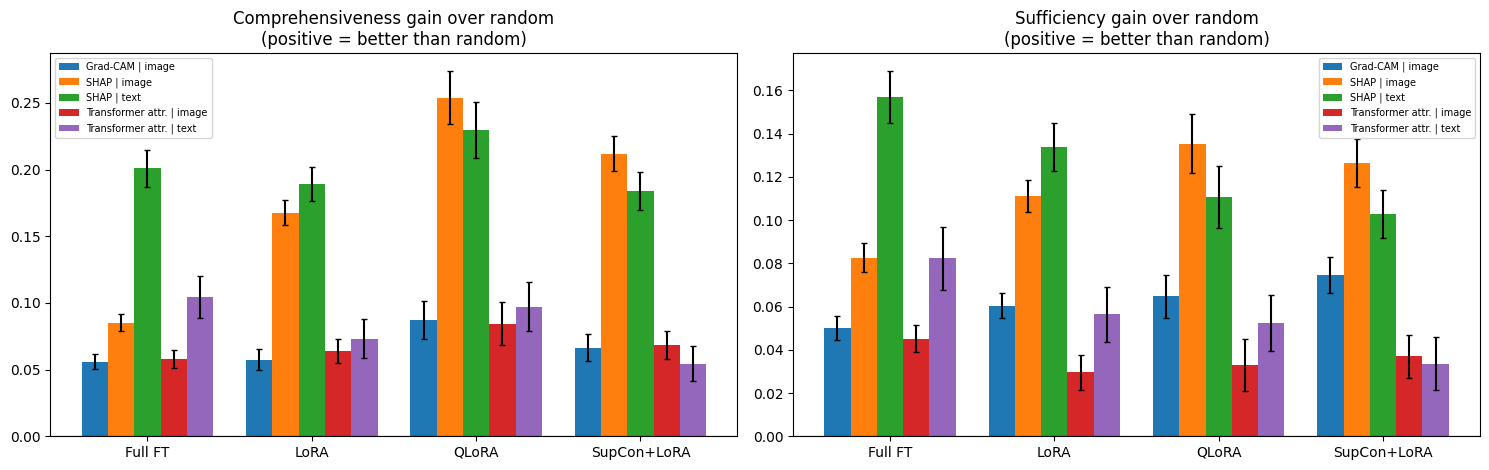

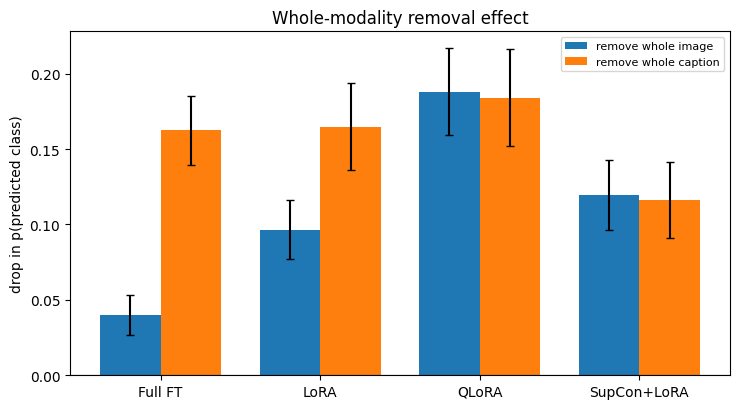

In [ ]:
x = np.arange(len(order))
fig, axes = plt.subplots(1, 2, figsize=(15, 4.8))
for ax, kind, title in [(axes[0], "comp", "Comprehensiveness gain over random"),
                        (axes[1], "suff", "Sufficiency gain over random")]:
    keys = [k for k in ALL_KEYS if METRICS[k][1] == kind]
    w = 0.8 / len(keys)
    for j, key in enumerate(keys):
        r = beats_random[beats_random.metric == key].set_index("strategy").loc[order]
        ax.bar(x + (j - (len(keys) - 1) / 2) * w, r["mean"], w, capsize=2,
               yerr=[r["mean"] - r.ci_lo, r.ci_hi - r["mean"]],
               label=label_of(key).replace(f" | {kind}", ""))
    ax.axhline(0, color="black", lw=0.8)
    ax.set_xticks(x); ax.set_xticklabels([LABELS[s] for s in order])
    ax.set_title(f"{title}\n(positive = better than random)"); ax.legend(fontsize=7)
plt.tight_layout()
plt.savefig(XAI_DIR / f"figure_gain_over_random_{ANALYSIS_TAG}.png", dpi=180, bbox_inches="tight")
plt.show()

fig, ax = plt.subplots(figsize=(7.5, 4.2))
w = 0.38
for j, (col, name) in enumerate([("image_removal_effect", "remove whole image"),
                                 ("text_removal_effect", "remove whole caption")]):
    rs = [paired_bootstrap(per[s][col]) for s in order]
    m = np.array([r["mean"] for r in rs])
    ax.bar(x + (j - 0.5) * w, m, w, capsize=3, label=name,
           yerr=[m - np.array([r["ci_lo"] for r in rs]), np.array([r["ci_hi"] for r in rs]) - m])
ax.axhline(0, color="black", lw=0.8)
ax.set_xticks(x); ax.set_xticklabels([LABELS[s] for s in order])
ax.set_ylabel("drop in p(predicted class)"); ax.legend(fontsize=8)
ax.set_title("Whole-modality removal effect")
plt.tight_layout()
plt.savefig(XAI_DIR / f"figure_modality_removal_{ANALYSIS_TAG}.png", dpi=180, bbox_inches="tight")
plt.show()

#### Interpretation — figures

- **Figure X1:** every bar lies above zero, so every method beats random for every strategy, on
  both measures. The KernelSHAP bars are the tallest, and the QLoRA group is the highest for the
  image methods.
- **Figure X2:** full fine-tuning's caption bar is about four times its image bar, while QLoRA and
  SupCon+LoRA have bars of equal height. This is the modality reliance that underlies the
  faithfulness pattern.

Both figures are saved in `xai/` for Chapter 4.

---
# Part XI — Answering the research questions

## 46. RQ2: does the optimisation strategy change explanation faithfulness?

> **RQ2.** How does the choice of optimisation strategy affect the faithfulness of post-hoc
> explanations generated by Grad-CAM and KernelSHAP, measured by ERASER comprehensiveness and
> sufficiency and reported separately for the visual and textual modalities?

### Decision rule (fixed in advance)

For each planned question, the six primary contrasts (Table X5) are combined:

| Outcome across the six metrics | Verdict |
|---|---|
| At least one significantly **less** faithful, none more | **Reduced** faithfulness |
| At least one significantly **more** faithful, none less | **Increased** faithfulness |
| Significant in both directions | **Mixed**: report which metric moved which way |
| None significant | **No detectable difference** |

A verdict is labelled **robust** when the significant contrasts behind it keep the same verdict
under the blur and logit checks (Table X10).

### Expectations stated in advance

- **The project plan's hypothesis:** 4-bit quantisation **degrades** faithfulness, because
  information lost in the frozen weights may push the model towards different features (Q2).
- **The competing mechanism:** low-rank adaptation **preserves** faithfulness, because it keeps
  the model close to CLIP's pretrained representation. Full fine-tuning's near-insensitivity to
  image occlusion in the first run (Part IX) makes this the more likely direction for Q1.

Stating both directions in advance makes the verdict below a test rather than a description.

In [ ]:
if "contrasts_primary" not in globals():
    raise RuntimeError("Run Part X (sections 39-45) first.")

QUESTION_TEXT = {"Q1": "Does low-rank adaptation change faithfulness? (LoRA vs Full FT)",
                 "Q2": "Does 4-bit quantisation change faithfulness? (QLoRA vs LoRA)",
                 "Q3": "Does the contrastive objective change faithfulness? (SupCon+LoRA vs LoRA)",
                 "E1": "QLoRA vs Full FT", "E2": "SupCon+LoRA vs Full FT", "E3": "QLoRA vs SupCon+LoRA"}
CAVEAT = {"Q1": "confounded by AUROC", "Q2": "clean", "Q3": "clean",
          "E1": "confounded by AUROC", "E2": "confounded by AUROC", "E3": "clean"}


def decide(g):
    more = g[g.verdict == "A more faithful"]
    less = g[g.verdict == "A LESS faithful"]
    if len(less) and not len(more):
        v = "REDUCED faithfulness"
    elif len(more) and not len(less):
        v = "INCREASED faithfulness"
    elif len(more) and len(less):
        v = "MIXED"
    else:
        v = "no detectable difference"
    return v, more, less


def robust_flag(q, sig_rows):
    if not len(sig_rows):
        return "-"
    rows = agree_pc.loc[[(q, m) for m in sig_rows.metric]] if q in agree_pc.index.get_level_values(0) else None
    return "robust" if rows is not None and bool(rows.robust.all()) else "NOT robust"


rows = []
for family, df in [("primary", contrasts_primary), ("supplementary", contrasts_supplementary),
                   ("exploratory", contrasts_exploratory)]:
    for q, g in df.groupby("question", sort=False):
        v, more, less = decide(g)
        rows.append({"family": family, "question": q, "asks": QUESTION_TEXT[q], "verdict": v,
                     "more faithful on": "; ".join(more.label) or "-",
                     "less faithful on": "; ".join(less.label) or "-",
                     "robust?": robust_flag(q, pd.concat([more, less])) if family == "primary" else "-",
                     "caveat": CAVEAT[q]})
verdicts = pd.DataFrame(rows).set_index(["family", "question"])
print("Table XI-1. Verdict per question")
display(verdicts)

print("\nRQ2 answer, generated from the primary family:")
for q in ["Q1", "Q2", "Q3"]:
    if ("primary", q) in verdicts.index:
        r = verdicts.loc[("primary", q)]
        extra = "" if r.verdict == "no detectable difference" else f" [{r['robust?']}]"
        print(f"  {q}: {r.verdict}{extra}. {QUESTION_TEXT[q]}" + (" Caveat: " + r.caveat if r.caveat != "clean" else ""))
q2 = verdicts.loc[("primary", "Q2")].verdict if ("primary", "Q2") in verdicts.index else None
if q2:
    held = "SUPPORTED" if q2 == "REDUCED faithfulness" else "NOT SUPPORTED"
    print(f"\nProject-plan hypothesis (quantisation degrades faithfulness): {held} (Q2 verdict: {q2}).")

Table XI-1. Verdict per question


asks                   verdict                                   more faithful on  \
family        question                                                                                                                                   
primary       Q1        Does low-rank adaptation change faithfulness? ...                     MIXED           SHAP | image | comp; SHAP | image | suff   
              Q2        Does 4-bit quantisation change faithfulness? (...                     MIXED  Grad-CAM | image | comp; SHAP | image | comp; ...   
              Q3        Does the contrastive objective change faithful...                     MIXED  Grad-CAM | image | suff; SHAP | image | comp; ...   
supplementary Q1        Does low-rank adaptation change faithfulness? ...      REDUCED faithfulness                                                  -   
              Q2        Does 4-bit quantisation change faithfulness? (...  no detectable difference                                                  -   
              Q3        Does the contrastive objective change faithful...      REDUCED faithfulness                                                  -   
exploratory   E1                                         QLoRA vs Full FT                     MIXED  Grad-CAM | image | comp; SHAP | image | comp; ...   
              E2                                   SupCon+LoRA vs Full FT                     MIXED  Grad-CAM | image | suff; SHAP | image | comp; ...   
              E3                                     QLoRA vs SupCon+LoRA    INCREASED faithfulness  Grad-CAM | image | comp; SHAP | image | comp; ...   

                                                         less faithful on     robust?               caveat  
family        question                                                                                      
primary       Q1                                       SHAP | text | suff  NOT robust  confounded by AUROC  
              Q2                                       SHAP | text | suff  NOT robust                clean  
              Q3                                       SHAP | text | suff  NOT robust                clean  
supplementary Q1        Transformer attr. | image | suff; Transformer ...           -  confounded by AUROC  
              Q2                                                        -           -                clean  
              Q3                          Transformer attr. | text | suff           -                clean  
exploratory   E1        SHAP | text | suff; Transformer attr. | text |...           -  confounded by AUROC  
              E2        SHAP | text | suff; Transformer attr. | text |...           -  confounded by AUROC  
              E3                                                        -           -                clean


RQ2 answer, generated from the primary family:
  Q1: MIXED [NOT robust]. Does low-rank adaptation change faithfulness? (LoRA vs Full FT) Caveat: confounded by AUROC
  Q2: MIXED [NOT robust]. Does 4-bit quantisation change faithfulness? (QLoRA vs LoRA)
  Q3: MIXED [NOT robust]. Does the contrastive objective change faithfulness? (SupCon+LoRA vs LoRA)

Project-plan hypothesis (quantisation degrades faithfulness): NOT SUPPORTED (Q2 verdict: MIXED).


#### Interpretation — the answer to RQ2

**The pre-specified verdicts.** Under the decision rule fixed in advance, all three questions are
**MIXED**: each has measures that are significantly more faithful and at least one that is
significantly less faithful. None is robust in every component. The table in section 42 shows
what lies behind each verdict:

- **Q1 (LoRA vs full FT): genuinely mixed, along modality lines.** LoRA's image explanations are
  more faithful (robust), and its text sufficiency is lower (robust). The contrast is confounded by
  LoRA's higher AUROC.
- **Q2 (QLoRA vs LoRA): mixed only because of one scale-dependent measure.** On every robust
  measure, QLoRA is **more** faithful (Grad-CAM image comprehensiveness, KernelSHAP image
  comprehensiveness, KernelSHAP text comprehensiveness). Its only "less faithful" measure reverses
  on the logit scale.
- **Q3 (SupCon+LoRA vs LoRA): mixed only because of one scale-dependent measure.** On robust
  measures, SupCon+LoRA's image explanations are more faithful. Its only "less faithful" measure
  reverses on the logit scale.

**The project plan's hypothesis is not supported.** 4-bit quantisation does not degrade explanation
faithfulness. On robust measures, it is associated with *more* faithful explanations.

> **RQ2 answer.** The optimisation strategy changes explanation faithfulness, and the change is
> modality-specific. Parameter-efficient strategies, whose decisions use the image more, give
> more faithful image explanations than full fine-tuning. Full fine-tuning, which relies mostly on
> the caption, gives more sufficient text explanations. Within the parameter-efficient family,
> neither 4-bit quantisation nor the contrastive objective reduces faithfulness on any robust
> measure. All explanations, under every strategy, are substantially more faithful than a random
> ranking.

### Wording the RQ2 answer

Keep "faithfulness" rather than "explainability" in each claim, and match the claim to the
verdict:

| Verdict | Claim |
|---|---|
| No detectable difference | The strategies did not differ detectably in the faithfulness of *[method]* attributions (difference [CI], Holm-adjusted p). Equivalence is **not** claimed. |
| Reduced or increased | *[A]*'s *[method]* attributions were less (more) faithful than *[B]*'s on *[metric]* (difference [CI], Holm-adjusted p). State whether the result is robust. For Q1, add that LoRA is also the better classifier. |
| Mixed | Name each metric and direction. Mixed results usually mean the strategies differ in *how* evidence is spread (comprehensiveness versus sufficiency), not in whether explanations can be trusted. |

**Q2 in particular.** QLoRA differs from LoRA only in 4-bit storage of the frozen weights.
Whichever way the verdict falls, it is a clean answer to the project plan's hypothesis.

## 47. How good are the explanations overall?

"Good" needs criteria that can fail. Four are used, in order of importance.

1. **Better than random** on comprehensiveness *and* sufficiency, after Holm correction
   (Table X4). This is the minimum bar.
2. **Robust:** the same verdict under blur and on the logit scale (Table X9).
3. **Practically large.** A comprehensiveness gain of 0.01 is a one-point change in confidence.
4. **Holds on errors** (Table X12).

| Grade | Criterion |
|---|---|
| **Faithful** | Beats random on comprehensiveness and sufficiency |
| **Partially faithful** | Beats random on one of the two |
| **Not shown to be faithful** | Beats random on neither |
| **Worse than random** | Significantly worse on at least one; investigate before reporting |

**Context, not thresholds.** ERASER's reference results are for text-only BERT models. Across
four of its datasets, perturbation-based LIME (the family KernelSHAP belongs to) reached
comprehensiveness of about 0.21–0.44, gradient-based attribution 0.06–0.18, and random orderings
0.03–0.08 (DeYoung et al., 2020).

**Expected before the run.**

- **KernelSHAP has a structural advantage in deletion tests.** It is fitted with the same removal
  operator ERASER then uses. Grad-CAM and the transformer attribution have no such advantage, so
  SHAP outscoring them says less about the methods than it appears to.
- **Image attributions are bounded by image reliance.** A model that barely uses the image
  (Table X11) leaves an image explanation nothing to find.

In [ ]:
SOURCES = [("gradcam_image", "Grad-CAM (image)"), ("chefer_image", "Transformer attr. (image)"),
           ("shap_image", "SHAP (image)"), ("chefer_text", "Transformer attr. (text)"),
           ("shap_text", "SHAP (text)")]


def grade(comp_v, suff_v):
    if "WORSE than random" in (comp_v, suff_v):
        return "worse than random"
    n = (comp_v == "beats random") + (suff_v == "beats random")
    return {2: "faithful", 1: "partially faithful", 0: "not shown to be faithful"}[n]


br = beats_random.set_index(["strategy", "metric"])
rows = []
for s in order:
    for src, name in SOURCES:
        c, u = br.loc[(s, f"{src}_comp")], br.loc[(s, f"{src}_suff")]
        robust = bool(agree_br.loc[[(s, f"{src}_comp"), (s, f"{src}_suff")]].robust.all())
        rows.append({"strategy": LABELS[s], "attribution": name,
                     "comp": per[s][f"{src}_comp"].mean(), "comp gain": c["mean"], "comp verdict": c.verdict,
                     "suff": per[s][f"{src}_suff"].mean(), "suff gain": u["mean"], "suff verdict": u.verdict,
                     "grade": grade(c.verdict, u.verdict), "robust": robust})
scorecard = pd.DataFrame(rows)
print("Table XI-2. Scorecard: every strategy x attribution source")
display(scorecard.set_index(["strategy", "attribution"]).round(4))
print("Table XI-3. Grades at a glance (* = not robust to the blur or logit check)")
grid = scorecard.assign(cell=scorecard.grade + np.where(scorecard.robust, "", " *")) \
                .pivot(index="attribution", columns="strategy", values="cell")
display(grid.loc[[n for _, n in SOURCES], [LABELS[s] for s in order]])

Table XI-2. Scorecard: every strategy x attribution source


comp  comp gain  comp verdict    suff  suff gain  suff verdict     grade  robust
strategy    attribution                                                                                                  
Full FT     Grad-CAM (image)           0.0593     0.0559  beats random -0.0203     0.0501  beats random  faithful    True
            Transformer attr. (image)  0.0611     0.0578  beats random -0.0153     0.0451  beats random  faithful    True
            SHAP (image)               0.0884     0.0851  beats random -0.0528     0.0825  beats random  faithful    True
            Transformer attr. (text)   0.1358     0.1046  beats random  0.0445     0.0824  beats random  faithful    True
            SHAP (text)                0.2324     0.2011  beats random -0.0299     0.1568  beats random  faithful    True
LoRA        Grad-CAM (image)           0.0857     0.0573  beats random  0.0207     0.0603  beats random  faithful    True
            Transformer attr. (image)  0.0922     0.0638  beats random  0.0514     0.0296  beats random  faithful    True
            SHAP (image)               0.1959     0.1674  beats random -0.0302     0.1112  beats random  faithful    True
            Transformer attr. (text)   0.1076     0.0732  beats random  0.0723     0.0564  beats random  faithful    True
            SHAP (text)                0.2234     0.1890  beats random -0.0049     0.1337  beats random  faithful    True
QLoRA       Grad-CAM (image)           0.1660     0.0870  beats random  0.1299     0.0648  beats random  faithful    True
            Transformer attr. (image)  0.1633     0.0843  beats random  0.1616     0.0331  beats random  faithful    True
            SHAP (image)               0.3329     0.2539  beats random  0.0595     0.1352  beats random  faithful    True
            Transformer attr. (text)   0.1585     0.0971  beats random  0.1013     0.0522  beats random  faithful    True
            SHAP (text)                0.2911     0.2297  beats random  0.0431     0.1105  beats random  faithful    True
SupCon+LoRA Grad-CAM (image)           0.1125     0.0664  beats random  0.0435     0.0745  beats random  faithful    True
            Transformer attr. (image)  0.1143     0.0682  beats random  0.0810     0.0370  beats random  faithful    True
            SHAP (image)               0.2580     0.2119  beats random -0.0083     0.1263  beats random  faithful    True
            Transformer attr. (text)   0.0903     0.0544  beats random  0.0676     0.0334  beats random  faithful   False
            SHAP (text)                0.2199     0.1840  beats random -0.0016     0.1027  beats random  faithful    True

Table XI-3. Grades at a glance (* = not robust to the blur or logit check)


strategy,Full FT,LoRA,QLoRA,SupCon+LoRA
attribution,,,,
Grad-CAM (image),faithful,faithful,faithful,faithful
Transformer attr. (image),faithful,faithful,faithful,faithful
SHAP (image),faithful,faithful,faithful,faithful
Transformer attr. (text),faithful,faithful,faithful,faithful *
SHAP (text),faithful,faithful,faithful,faithful


**Reading the grades.**

- **A row graded "faithful" for every strategy** shows that the method works on this architecture
  whatever the adaptation. That is a claim about the method.
- **A cell that differs from the rest of its row** shows the adaptation changing whether the
  method works. That is a claim about the strategy, and it must match a significant contrast in
  Table X5. Otherwise it is a threshold effect (one test just above 0.05, another just below)
  and must not be reported as a difference.
- **A column that is weak throughout** shows a model whose decisions resist attribution in
  general. Check that model's modality reliance (Table X11) and confidence (Table X13) first.

#### Interpretation — how good are the explanations overall?

**Grades: all 20 strategy × method combinations are "faithful".** Each beats random on both
comprehensiveness and sufficiency. 19 of 20 keep that grade under both robustness checks; the
exception is SupCon+LoRA's transformer-attribution text sufficiency on the logit scale.

Against the four criteria of this section:

1. **Better than random:** met in 40 of 40 tests.
2. **Robust:** met in 39 of 40.
3. **Practically large.** Deleting the top-ranked evidence removes 5–25 percentage points more
   confidence than deleting random evidence (Table X4).
4. **Holds on errors.** Faithfulness is no lower on misclassified memes (Table X12).

**By method.**

| Method | Assessment |
|---|---|
| **KernelSHAP** | The most faithful, on both modalities. Its text comprehensiveness (0.22–0.29) is in the range ERASER reports for perturbation methods on text tasks. Part of its lead comes from being fitted with ERASER's own removal operator |
| **Grad-CAM** | Faithful but more modest (image comprehensiveness 0.06–0.17), in the range ERASER reports for gradient methods. It is limited by reading one layer and by the 7×7 grid |
| **Transformer attribution** | Very close to Grad-CAM on images, and it adds a faithful text explanation that Grad-CAM cannot provide |

**Are the explanations good?** By the faithfulness criteria of this study, yes: every method
identifies evidence the models actually use, under every strategy. Two qualifications apply:

- Deletion tests use unnatural inputs, and the 7×7 grid limits image precision.
- Faithfulness is not usefulness. Whether moderators would understand or trust these explanations
  is a separate question (section 51).

## 48. RQ3: the efficiency–faithfulness trade-off

> **RQ3.** What is the relationship between a strategy's efficiency (trainable parameters,
> training time, peak GPU memory) and the faithfulness of its explanations? Are efficiency gains
> obtained at a cost in faithfulness?

Table XI-4 puts each strategy's cost next to what it delivers. A trade-off exists only if a
cheaper strategy is significantly less faithful (section 46). Otherwise the efficiency comes
without a measurable explanation cost.

- **Peak GPU memory** is from section 17: one forward–backward step, with gradient checkpointing
  off for every strategy. It excludes optimiser state; the optional profile in section 17 adds
  it.
- **Storage** is shown as trainable parameters × 4 bytes, which is what a deployment must store
  given the public CLIP weights.

In [ ]:
efficiency = pd.DataFrame({
    "trainable parameters": [151_671_554, 1_377_281, 1_377_281, 1_541_505],
    "trainable-only MB":    [606.7, 5.5, 5.5, 6.2],
    "peak GPU GB (fwd-bwd)": [3.161, 3.040, 2.597, 3.042],
    "train minutes":        [23.6, 22.4, 22.1, 23.3],
    "test AUROC":           [0.6844, 0.7340, 0.7218, 0.7351],
}, index=STRATEGY_ORDER)
for key, name in [("gradcam_image_comp", "Grad-CAM image comp gain"),
                  ("shap_image_comp", "SHAP image comp gain"),
                  ("shap_text_comp", "SHAP text comp gain")]:
    g = beats_random[beats_random.metric == key].set_index("strategy")
    efficiency[name] = [f"{g.loc[s, 'mean']:+.3f} [{g.loc[s, 'ci_lo']:+.3f}, {g.loc[s, 'ci_hi']:+.3f}]"
                        if s in g.index else "-" for s in STRATEGY_ORDER]
qv = lambda q: verdicts.loc[("primary", q)].verdict if ("primary", q) in verdicts.index else "-"
efficiency["faithfulness verdict"] = ["reference", qv("Q1") + " (vs Full FT)",
                                      qv("Q2") + " (vs LoRA)", qv("Q3") + " (vs LoRA)"]
efficiency.index = [LABELS[s] for s in STRATEGY_ORDER]
print("Table XI-4. What each strategy costs and what it delivers")
display(efficiency)

cost = [qv(q) for q in ("Q1", "Q2")]
if any(v in ("REDUCED faithfulness", "MIXED") for v in cost):
    print("\nRQ3: at least one cheaper strategy shows reduced (or mixed) faithfulness -> a trade-off exists; "
          "see Table XI-1 for which metrics.")
else:
    print("\nRQ3: no cheaper strategy shows reduced faithfulness -> the efficiency gains came without a "
          "detectable faithfulness cost on this benchmark.")

Table XI-4. What each strategy costs and what it delivers


,trainable parameters,trainable-only MB,peak GPU GB (fwd-bwd),train minutes,test AUROC,Grad-CAM image comp gain,SHAP image comp gain,SHAP text comp gain,faithfulness verdict
Full FT,151671554,606.7,3.161,23.6,0.6844,"+0.056 [+0.050, +0.062]","+0.085 [+0.079, +0.092]","+0.201 [+0.187, +0.215]",reference
LoRA,1377281,5.5,3.040,22.4,0.7340,"+0.057 [+0.050, +0.065]","+0.167 [+0.158, +0.177]","+0.189 [+0.176, +0.202]",MIXED (vs Full FT)
QLoRA,1377281,5.5,2.597,22.1,0.7218,"+0.087 [+0.073, +0.102]","+0.254 [+0.234, +0.274]","+0.230 [+0.209, +0.250]",MIXED (vs LoRA)
SupCon+LoRA,1541505,6.2,3.042,23.3,0.7351,"+0.066 [+0.056, +0.077]","+0.212 [+0.199, +0.225]","+0.184 [+0.170, +0.198]",MIXED (vs LoRA)



RQ3: at least one cheaper strategy shows reduced (or mixed) faithfulness -> a trade-off exists; see Table XI-1 for which metrics.


#### Interpretation — the answer to RQ3

| Strategy | Cost relative to full FT | Faithfulness relative to its comparator |
|---|---|---|
| LoRA | 110× fewer parameters, 6 MB to deploy, same training time | More faithful on images (robust); less sufficient on text (robust; confounded with higher AUROC) |
| QLoRA | As LoRA, plus 0.44 GB less peak memory than LoRA | More faithful than LoRA on three robust measures; less faithful on none robustly |
| SupCon+LoRA | As LoRA (slightly more parameters) | More faithful than LoRA on images (robust) |

> **RQ3 answer.** Efficiency gains are not obtained at a consistent cost in faithfulness. The
> cheaper strategies give more faithful image explanations than full fine-tuning, and the cheapest
> in memory (QLoRA) is at least as faithful as LoRA on every robust measure. The only robust cost is
> lower text sufficiency for LoRA against full fine-tuning. That cost accompanies LoRA's greater use
> of the image and its higher AUROC, so it reflects where the model looks rather than a loss caused
> by efficiency.

Across the four strategies, efficiency, classification performance and image faithfulness move in
the same direction rather than trading off against each other.

## 49. Summary of the answers

**RQ1: classification performance.** All three parameter-efficient strategies classify hateful
memes significantly better than full fine-tuning: +0.037 to +0.051 AUROC, Holm-adjusted
p ≤ 0.0004. They train at most 1.02% of its parameters, and none of the three is distinguishable
from the others. The training curves explain the result: full fine-tuning overfits and degrades
after epoch 3, while the low-rank strategies plateau, because under limited supervision the
low-rank constraint acts as regularisation.

**RQ2: explanation faithfulness.**

- Grad-CAM, KernelSHAP and the transformer attribution beat a matched random baseline for every
  strategy, in both modalities (40 of 40 tests; 39 robust to the blur and logit checks).
- The strategy changes faithfulness in a modality-specific way. Parameter-efficient strategies
  give more faithful image explanations than full fine-tuning, while full fine-tuning gives more
  sufficient text explanations.
- This mirrors modality reliance: full fine-tuning relies on the caption about four times as much
  as on the image, whereas QLoRA and SupCon+LoRA rely on both equally.
- 4-bit quantisation does not reduce faithfulness, so the project plan's hypothesis is not
  supported.

**RQ3: efficiency and the trade-off.**

- *Efficiency:* parameters and deployable storage fall about 110-fold. 4-bit storage cuts
  forward–backward peak memory by 15% against LoRA. Training time is unchanged.
- *Trade-off:* there is no consistent faithfulness cost. The cheaper strategies are more faithful
  on images; the one robust cost (LoRA's text sufficiency) is confounded with its higher AUROC and
  its greater use of the image.

## 50. What the thesis has achieved

1. **An empirical result for multimodal hateful-meme detection.** Low-rank adaptation of CLIP
   outperforms full fine-tuning while training about 1% of the parameters. 4-bit quantisation and
   a supervised contrastive objective produce no detectable change in AUROC on top of it.
2. **Evidence that parameter-efficient adaptation does not cost explanation faithfulness.** Every
   strategy's explanations are substantially more faithful than random. The cheaper strategies
   give more faithful image explanations, and 4-bit quantisation does not reduce faithfulness.
3. **A modality-specific account of faithfulness.** Faithfulness follows how much each strategy's
   decisions rely on the image and the caption, measured on a common scale by whole-modality
   removal.
4. **A controlled comparison framework.** One model factory, one training function and one test
   function make "only the strategy varies" true by construction. Seeding, checkpoint reloading
   and experiment logging make it reproducible, and 26 verified findings are documented.
5. **Sound statistical practice.** Paired bootstrap and DeLong intervals, Holm correction within
   pre-specified families, two robustness checks, and a demonstration, on the study's own data,
   that F1 and raw ERASER scores can mislead.
6. **Three transferable pitfalls.** Verification identified three ways in which ERASER-style
   evaluation silently goes wrong on Hugging Face CLIP:
   - the Grad-CAM hook point;
   - the pad token doubling as the end-of-text read-out;
   - SHAP's default regularisation.

## 51. Limitations and remaining work

**Limitations.**

- **Data.** A filtered subset of the Hateful Memes Challenge (about 80% of the canonical data),
  so absolute AUROC is not comparable with the leaderboard. The strategy comparison is
  unaffected.
- **Seeds.** One training run per strategy. Seed variation, measured at about 0.004 AUROC, bounds
  what differences within the parameter-efficient group can mean.
- **Tuning.** All four strategies use one fixed configuration. Full fine-tuning in particular
  might improve with a schedule or layer-wise learning-rate decay.
- **Architecture.** One backbone (ViT-B/32, giving a 7×7 explanation grid) and late fusion by
  concatenation, which cannot represent image–text interactions directly.
- **Deletion-based evaluation.** Masked inputs are unnatural. The blur check and the gain over
  random limit the effect but cannot remove it (Hooker et al., 2019). Image-sufficiency contrasts
  in particular depend on the fill operator.
- **Score scale.** Two text-sufficiency contrasts (Q2, Q3) change direction between the probability
  and logit scales. They are reported as confidence effects, not as differences in faithfulness.
- **Method advantage.** KernelSHAP is fitted with ERASER's own removal operator, which favours it in
  deletion tests.
- **4-bit numerics.** QLoRA's single and batched forward passes differ slightly (F-26). This affects
  at most 5 of 600 predictions.
- **Hardware.** The explanation stage ran over several Colab sessions. The GPU used for each
  strategy is stated in Chapter 3.
- **Faithfulness is not usefulness.** Whether moderators would understand or act on these
  explanations needs a user study.

**Remaining work.**

| Step | Where | Time |
|---|---|---|
| Optional: memory including optimiser state | Section 17 | About 2 minutes |
| Thesis update | Chapter 3 (method), Chapter 4 (RQ2, RQ3 results), Chapter 5 (discussion), Chapter 6 (conclusion) | — |

Future work: ViT-B/16 (a 14×14 grid), several seeds per strategy, an interaction-based fusion head,
and a user study of explanation usefulness.

## References (APA 7th)

Adebayo, J., Gilmer, J., Muelly, M., Goodfellow, I., Hardt, M., & Kim, B. (2018). Sanity checks
for saliency maps. *Advances in Neural Information Processing Systems, 31*.

Chefer, H., Gur, S., & Wolf, L. (2021). Generic attention-model explainability for interpreting
bi-modal and encoder-decoder transformers. In *Proceedings of the IEEE/CVF International
Conference on Computer Vision* (pp. 397–406).

DeLong, E. R., DeLong, D. M., & Clarke-Pearson, D. L. (1988). Comparing the areas under two or
more correlated receiver operating characteristic curves: A nonparametric approach.
*Biometrics, 44*(3), 837–845.

Dettmers, T., Pagnoni, A., Holtzman, A., & Zettlemoyer, L. (2023). QLoRA: Efficient finetuning of
quantized LLMs. *Advances in Neural Information Processing Systems, 36*.

DeYoung, J., Jain, S., Rajani, N. F., Lehman, E., Xiong, C., Socher, R., & Wallace, B. C. (2020).
ERASER: A benchmark to evaluate rationalized NLP models. In *Proceedings of the 58th Annual
Meeting of the Association for Computational Linguistics* (pp. 4443–4458).

Efron, B., & Tibshirani, R. J. (1993). *An introduction to the bootstrap*. Chapman & Hall.

Holm, S. (1979). A simple sequentially rejective multiple test procedure. *Scandinavian Journal of
Statistics, 6*(2), 65–70.

Hooker, S., Erhan, D., Kindermans, P.-J., & Kim, B. (2019). A benchmark for interpretability
methods in deep neural networks. *Advances in Neural Information Processing Systems, 32*.

Hu, E. J., Shen, Y., Wallis, P., Allen-Zhu, Z., Li, Y., Wang, S., Wang, L., & Chen, W. (2022).
LoRA: Low-rank adaptation of large language models. In *International Conference on Learning
Representations*.

Jacovi, A., & Goldberg, Y. (2020). Towards faithfully interpretable NLP systems: How should we
define and evaluate faithfulness? In *Proceedings of the 58th Annual Meeting of the Association
for Computational Linguistics* (pp. 4198–4205).

Khosla, P., Teterwak, P., Wang, C., Sarna, A., Tian, Y., Isola, P., Maschinot, A., Liu, C., &
Krishnan, D. (2020). Supervised contrastive learning. *Advances in Neural Information Processing
Systems, 33*.

Kiela, D., Firooz, H., Mohan, A., Goswami, V., Singh, A., Ringshia, P., & Testuggine, D. (2020).
The hateful memes challenge: Detecting hate speech in multimodal memes. *Advances in Neural
Information Processing Systems, 33*.

Lundberg, S. M., & Lee, S.-I. (2017). A unified approach to interpreting model predictions.
*Advances in Neural Information Processing Systems, 30*.

Radford, A., Kim, J. W., Hallacy, C., Ramesh, A., Goh, G., Agarwal, S., Sastry, G., Askell, A.,
Mishkin, P., Clark, J., Krueger, G., & Sutskever, I. (2021). Learning transferable visual models
from natural language supervision. In *Proceedings of the 38th International Conference on
Machine Learning* (pp. 8748–8763). PMLR.

Selvaraju, R. R., Cogswell, M., Das, A., Vedantam, R., Parikh, D., & Batra, D. (2017). Grad-CAM:
Visual explanations from deep networks via gradient-based localization. In *Proceedings of the
IEEE International Conference on Computer Vision* (pp. 618–626).

Sturmfels, P., Lundberg, S., & Lee, S.-I. (2020). Visualizing the impact of feature attribution
baselines. *Distill, 5*(1), e22.

Sun, X., & Xu, W. (2014). Fast implementation of DeLong's algorithm for comparing the areas under
correlated receiver operating characteristic curves. *IEEE Signal Processing Letters, 21*(11),
1389–1393.

Check volume and page details against Zotero before submission.